In [1]:
# ===================== HW CELL 1: Setup, tools, read-only inventory, md5 check, hardware config =====================
import os, sys, json, time, shutil, subprocess, hashlib, platform, importlib
sys.dont_write_bytecode = True                      # NEW: importing Prototype_10/code/*.py must not create __pycache__ on Drive
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'
import numpy as np, pandas as pd, torch
from google.colab import drive

# (from Prototype10 Cell 1) stuck-mount fix
if os.path.isdir('/content/drive') and not os.path.ismount('/content/drive'):
    shutil.rmtree('/content/drive')
drive.mount('/content/drive')

FORCE_CONFIG   = False      # True = overwrite hardware_verification/config/hw_config.json with the defaults below
FORCE_SNAPSHOT = False      # True = re-take the read-only snapshot (only if you changed Prototype_10 on purpose)

# ---------- 1) Tools (from hardware1 Cell 0, made conditional) ----------
if not (shutil.which('iverilog') and shutil.which('yosys')):
    subprocess.run("apt-get update -qq && apt-get install -y -qq iverilog yosys > /dev/null 2>&1", shell=True)
def _ver(cmd):
    try: return subprocess.check_output(cmd, stderr=subprocess.STDOUT).decode().splitlines()[0]
    except Exception as e: return f"NOT AVAILABLE ({e})"
iverilog_v, yosys_v = _ver(["iverilog", "-V"]), _ver(["yosys", "-V"])

# ---------- 2) Shared helper module (written to Drive, imported by every later cell) ----------
ROOT = '/content/drive/MyDrive/Prototype_10'
HW_ROOT = os.path.join(ROOT, 'hardware_verification')
for d in ['config', 'quantization', 'sram_audit', 'mappings', 'noc', 'rtl', 'figures', 'reports', 'code']:
    os.makedirs(os.path.join(HW_ROOT, d), exist_ok=True)          # the ONLY directories this notebook creates

HWC_SRC = r'''# hw_common.py -- helpers of the hardware_verification notebook (written by HW Cell 1).
# Writes ONLY under hardware_verification/; Prototype_10 outside it is read-only (verify_readonly() proves it).
import os, json, time
ROOT = '/content/drive/MyDrive/Prototype_10'
HW_ROOT = os.path.join(ROOT, 'hardware_verification')
SUBDIRS = ['config', 'quantization', 'sram_audit', 'mappings', 'noc', 'rtl', 'figures', 'reports', 'code']
HW = {d: os.path.join(HW_ROOT, d) for d in SUBDIRS}
HW_MANIFEST = os.path.join(HW_ROOT, 'manifest_hw.json')
P10_MANIFEST = os.path.join(ROOT, 'manifest.json')
SNAPSHOT_PATH = os.path.join(HW['config'], 'readonly_snapshot.json')

def chk(ok, msg):
    print(f"  {'✅' if ok else '❌'} {msg}"); assert ok, msg
def soft(ok, msg):
    print(f"  {'✅' if ok else '⚠️'} {msg}"); return bool(ok)

def hw_path(*parts):
    p = os.path.abspath(os.path.join(HW_ROOT, *parts))
    assert p.startswith(HW_ROOT + os.sep), f"refusing to write outside hardware_verification: {p}"
    os.makedirs(os.path.dirname(p), exist_ok=True)
    return p

def register_hw(path, desc):                       # SEPARATE manifest (never touches Prototype_10/manifest.json)
    p = os.path.abspath(path); assert p.startswith(HW_ROOT + os.sep), p
    m = json.load(open(HW_MANIFEST)) if os.path.exists(HW_MANIFEST) else {}
    m[os.path.relpath(p, HW_ROOT)] = desc
    with open(HW_MANIFEST, 'w') as f: json.dump(m, f, indent=2)

def write_json(path, obj, desc):
    with open(path, 'w') as f: json.dump(obj, f, indent=2, default=str)
    register_hw(path, desc)

def scan_readonly():                               # every file of Prototype_10 OUTSIDE hardware_verification: [size, mtime_s]
    out = {}
    for d, dirs, fs in os.walk(ROOT):
        if os.path.abspath(d).startswith(HW_ROOT): dirs[:] = []; continue
        for f in fs:
            p = os.path.join(d, f); st = os.stat(p); out[os.path.relpath(p, ROOT)] = [st.st_size, int(st.st_mtime)]
    return out

def verify_readonly():
    snap = json.load(open(SNAPSHOT_PATH))['files']; now = scan_readonly()
    added, removed = sorted(set(now) - set(snap)), sorted(set(snap) - set(now))
    size_ch = sorted(k for k in snap if k in now and snap[k][0] != now[k][0])
    mt_ch = sorted(k for k in snap if k in now and snap[k][0] == now[k][0] and snap[k][1] != now[k][1])
    chk(not added and not removed and not size_ch,
        f"Prototype_10 outside hardware_verification unchanged vs snapshot ({len(snap)} files; added {added[:3]}, removed {removed[:3]}, size-changed {size_ch[:3]})")
    soft(not mt_ch, f"no modification-time changes ({len(mt_ch)} files differ)")
'''
HWC_PATH = os.path.join(HW_ROOT, 'code', 'hw_common.py')
with open(HWC_PATH, 'w') as f: f.write(HWC_SRC)
if HW_ROOT + '/code' not in sys.path: sys.path.insert(0, HW_ROOT + '/code')
import hw_common; importlib.reload(hw_common)
from hw_common import chk, soft, hw_path, register_hw, write_json, scan_readonly, verify_readonly, HW_MANIFEST, SNAPSHOT_PATH
register_hw(HWC_PATH, "helpers: chk/soft, write-guard (hw_path), separate manifest, read-only snapshot + verification")

# ---------- 3) Print Prototype10 config.json and manifest.json (read-only) ----------
CONFIG_PATH = os.path.join(ROOT, 'config', 'config.json'); P10_MANIFEST = os.path.join(ROOT, 'manifest.json')
chk(os.path.exists(CONFIG_PATH), f"config.json found: {CONFIG_PATH}")
chk(os.path.exists(P10_MANIFEST), f"manifest.json found: {P10_MANIFEST}")
config = json.load(open(CONFIG_PATH)); p10_manifest = json.load(open(P10_MANIFEST))
PATHS, HWP, TRAIN, ARCH = config['PATHS'], config['HW'], config['TRAIN'], config['ARCH']
print("\nCONFIG.JSON (Prototype10; created %s)" % config.get('created'))
for k in ['SEED', 'SEEDS', 'TRAIN', 'FT', 'ARCH', 'MASK', 'HW', 'STEPS', 'DATA', 'ENV']:
    print(f"  {k}: {json.dumps(config.get(k), default=str)[:900]}")
for k in ['MODEL_CODE', 'TRAIN_CODE', 'MAPPING_CODE']:
    print(f"  {k}: md5 {config.get(k, {}).get('md5')}")
for s, ai in config.get('ARCH_INFO', {}).items():
    print(f"  ARCH_INFO[{s}]: {json.dumps(ai)[:600]}")
print(f"\nMANIFEST.JSON (Prototype10): {len(p10_manifest)} entries")
for k, v in p10_manifest.items(): print(f"  {k:<48} {str(v)[:95]}")

# ---------- 4) Import Prototype10 code FROM Drive (not rewritten) + md5 check against config ----------
print("\nCODE FILES (imported from Drive; md5 vs config.json)")
code_dir = PATHS['code']
for fn, key in (('p10_model.py', 'MODEL_CODE'), ('p10_train.py', 'TRAIN_CODE'), ('p10_mapping.py', 'MAPPING_CODE')):
    md5 = hashlib.md5(open(os.path.join(code_dir, fn), 'rb').read()).hexdigest()
    chk(md5 == config[key]['md5'], f"{fn}: md5 {md5} == config {key} {config[key]['md5']}")
print("  p10_post.py:", "present" if os.path.exists(os.path.join(code_dir, 'p10_post.py')) else "MISSING", "(no md5 stored in config; not imported)")
if code_dir not in sys.path: sys.path.insert(0, code_dir)
import p10_model, p10_train, p10_mapping
from p10_train import variant_key, variant_paths, is_done, load_variant, eval_fast
from p10_model import FastSNN, run_fast, count_params, mask_report, fc_connections
p10_mapping.set_hw(HWP)
soft(not os.path.isdir(os.path.join(code_dir, '__pycache__')), "no __pycache__ in Prototype_10/code (if present it pre-existed this notebook)")

# ---------- 5) Inventory of the 9 variants + data + hypergraph artifacts ----------
DIRS = {k: PATHS[k] for k in ('models', 'masks', 'results', 'spike_traces')}
SIZES, MODES, SEED = ['S', 'M', 'L'], ['dense', 'pre', 'post'], config['SEED']
KEYS = [variant_key(s, m, SEED) for s in SIZES for m in MODES]
EXPECTED_BEST = {'S_dense_s42': 58.63, 'S_pre_s42': 58.34, 'S_post_s42': 58.15, 'M_dense_s42': 62.87, 'M_pre_s42': 61.62,
                 'M_post_s42': 63.74, 'L_dense_s42': 63.65, 'L_pre_s42': 64.22, 'L_post_s42': 63.55}      # from Prototype10 Cell 8/10 outputs
tu = config['STEPS']['total_updates']; EXP_UPD = dict(dense=tu['dense'], pre=tu['pre'], post=tu['post'])
print("\nVARIANTS (stale guard: total_updates dense/pre %d, post %d)" % (EXP_UPD['dense'], EXP_UPD['post']))
print(f"  {'variant':<13}{'files':>6}{'best val':>10}{'ep':>5}{'updates':>9}{'params':>9}{'FC conn':>9}{'masked sp.':>11}")
inv = []
for key in KEYS:
    mode = key.split('_')[1]; P = variant_paths(DIRS, key)
    chk(all(os.path.exists(p) for p in P.values()), f"{key}: all {len(P)} files present")
    r = json.load(open(P['results']))
    print(f"  {key:<13}{len(P):>6}{r['best_acc']*100:>9.2f}%{r['best_epoch']:>5}{r['total_updates']:>9}{r['n_params']:>9,}{r['fc_connections']:>9,}{r['masked_layers_sparsity']*100:>10.1f}%")
    chk(r['total_updates'] == EXP_UPD[mode], f"{key}: total_updates {r['total_updates']} == {EXP_UPD[mode]} (not stale)")
    soft(round(r['best_acc'] * 100, 2) == EXPECTED_BEST[key], f"{key}: best-val {r['best_acc']*100:.2f}% == value in the Prototype10 outputs ({EXPECTED_BEST[key]})")
    inv.append(dict(variant=key, best_val=r['best_acc'], best_epoch=r['best_epoch'], total_updates=r['total_updates'], n_params=r['n_params'],
                    fc_connections=r['fc_connections'], masked_layers_sparsity=r['masked_layers_sparsity']))
_X = np.load(os.path.join(PATHS['data'], 'X_ea.npy'), mmap_mode='r'); _iv = np.load(os.path.join(PATHS['data'], 'idx_va.npy'))
chk(_X.shape == (5184, 22, 1001) and len(_iv) == 1037, f"data: X_ea {_X.shape} float32={_X.dtype == np.float32}, val trials {len(_iv)}"); del _X
tw = np.load(os.path.join(PATHS['spike_traces'], 'trace_windows.npz'))
print(f"  trace_windows.npz keys {tw.files}; windows {len(tw['positions_in_val'])}, per class {np.bincount(tw['labels']).tolist()}")
tz = np.load(variant_paths(DIRS, 'S_dense_s42')['trace'])
print("  trace_S_dense_s42.npz: " + ", ".join(f"{k}{tuple(tz[k].shape)}" for k in tz.files if k.startswith('L')) + f", T={int(tz['T'])}, layer_names={tz['layer_names'].tolist()}")
HG_DIR = PATHS['hypergraph']
for fn in ['hypergraphs_val.pkl', 'partitions_val.pkl', 'mapping_audit.csv', 'ablation_val.csv', 'mapping_metrics_val.csv', 'c_vs_a_diagnosis_val.csv', 'pair_stats_val.csv']:
    chk(os.path.exists(os.path.join(HG_DIR, fn)), f"hypergraph/{fn} ({os.path.getsize(os.path.join(HG_DIR, fn))/1e3:.0f} kB)")
mp = PATHS['mappings']; print(f"  Prototype_10/mappings/ contains: {sorted(os.listdir(mp)) if os.path.isdir(mp) else 'MISSING'} (placements were not saved: Cell 5 regenerates them)")

# ---------- 6) Read-only snapshot of everything outside hardware_verification ----------
print("\nREAD-ONLY SNAPSHOT")
if FORCE_SNAPSHOT or not os.path.exists(SNAPSHOT_PATH):
    files = scan_readonly(); write_json(SNAPSHOT_PATH, dict(created=time.strftime("%Y-%m-%d %H:%M:%S"), files=files), "size/mtime of every Prototype_10 file outside hardware_verification at the start (read-only proof)")
    print(f"  snapshot taken: {len(files)} files, {sum(v[0] for v in files.values())/1e6:.1f} MB")
    top = {}
    for k, v in files.items(): t = k.split('/')[0] if '/' in k else '(root)'; top[t] = top.get(t, [0, 0]); top[t][0] += 1; top[t][1] += v[0]
    for t, (n, b) in sorted(top.items()): print(f"    {t:<14}{n:>5} files {b/1e6:>9.1f} MB")
else:
    print("  snapshot exists: verifying"); verify_readonly()
unreg = sorted(set(scan_readonly()) - set(p10_manifest))
soft(not unreg, f"every Prototype_10 file is in ITS manifest ({len(unreg)} not registered: {unreg[:3]})")

# ---------- 7) Hardware config (ALL assumptions; edit the JSON before Cell 3 if you want other defaults) ----------
cyc_ns = HWP['L_R'] + HWP['L_T']
HWCFG = dict(
  created=time.strftime("%Y-%m-%d %H:%M:%S"),
  evidence_levels=dict(i="ANALYTICAL estimate (rates x hop distances)", ii="TRACE-DRIVEN replay (real spike traces, link-load accounting)",
                       iii="CYCLE-LEVEL simulation of the stated NoC model (finite buffers, backpressure)", iv="RTL = functional/accounting check of counters",
                       note="none of these is a measurement of real silicon; never call one level by another's name"),
  models=dict(keys=KEYS, seed=SEED, checkpoint="best-val (same as hypergraphs/traces)", expected_updates=EXP_UPD),
  data=dict(quantisation_eval="full val set (1037 trials)", noc_windows="32 saved trace windows (8 per class), per class and overall",
            stress_window="data-chosen window with the highest packet count under mapping A, labelled as such"),
  p10_constants=dict(HW=HWP, source="Prototype10 config.json (Loihi-small values)"),
  quantization=dict(status="PROPOSAL (not from the notebooks)",
     gate=dict(rule="paired val-accuracy drop vs float32 reference of the SAME checkpoint <= 1.0 point AND prediction agreement >= 95%", max_drop_points=1.0, min_agreement=0.95, declared_before_running=True),
     main=dict(weight_bits=8, membrane_bits=16, input_bits=16, beta_frac_bits=8), sweeps=dict(weight_bits=[8, 6, 4], membrane_bits=[16, 12], input_bits=[16, 12, 8]),
     layernorm_variants=dict(a="LN in float32 on integer-quantised weights (hybrid)", b="LN in fixed point (integer mean/var, reciprocal-sqrt LUT or Newton, fixed-point gamma/beta)"),
     references=["bf16 run_fast (source of the validated accuracy)", "independent float32 forward (no autocast)"],
     memory_formats=dict(weight_only="int8 x retained synapses", csr_like="weights + ceil(log2(in_features)) bits per retained synapse index", crossbar="all dense positions stored incl. zeros"),
     bn_fold="folded exactly into conv in eval mode (verified numerically in Cell 2)"),
  noc=dict(status="PROPOSAL (not from the notebooks)", topology="2D mesh n x n, n = p10_mapping._grid(cores)", routing="deterministic XY", packet="single-flit spike packet per (active source neuron, destination core != own core)",
     link="1 flit/cycle/link", hop_cycles=1, fifo_depth=4, fifo_sweep=[2, 4, 8, None], arbitration="round-robin", flow_control="credit-based backpressure",
     injection_ejection="1 packet/cycle/core", sync="tick-synchronous barrier (tick ends when the network is drained)", cycle_ns=cyc_ns, cycle_ns_note="1 cycle = L_R + L_T",
     energy="hops*(E_R+E_T) + packets*E_R", E_BUF_pJ=0.45, E_BUF_note="ASSUMPTION taken from hardware1, not a Loihi constant; stall energy reported separately", L_STALL_ns=2.1, L_STALL_note="ASSUMPTION from hardware1 (trace-driven model only)",
     main_placement_seed=42, robustness_placement_seeds=HWP['PLACEMENT_SEEDS'], iterations=HWP['ITERATIONS']),
  mapping=dict(A="sequential + linear", B="sequential + Hilbert + refinement", C="overlap + linear", D="overlap + Hilbert + refinement", C_NPC=HWP['C_NPC'],
               regenerate="random.seed(seed) right before placement_refinement(hilbert_initial_placement(pm)), as Prototype10 Cell 11 `refined`", acceptance="ELP equals ablation_val.csv / mapping_metrics_val.csv"),
  system_overhead=dict(status="PROPOSAL (all locations/sizes are assumptions)", frontend="values delivered per tick to cores hosting conv units from an I/O port at a mesh corner (hop-weighted)",
     layernorm="per hidden layer per tick: partial sums to a root core and back, 2*(cores_in_layer-1) packets; conv units and readout excluded", first="counts and hop-weighted counts; then optionally injected into the cycle-level simulator"),
  rtl=dict(status="PROPOSAL", widths="core id and coordinates parametrised with clog2", ticks=config['DATA'].get('T_time_steps', 201), scope="accounting/counter check only, not a router"),
  limitations=["one training seed (42)", "no test set: val used for selection, rates and traces (optimistic)", "post-sparse got 1600 extra updates; pre vs post unresolved",
               "every mapping violates C_SPC (some also C_APC): communication-cost estimates for capacity-violating mappings", "32 trace windows only",
               "NoC/energy constants are Loihi-small values from the notebooks plus labelled assumptions", "conv front-end compute energy and LayerNorm hardware not modelled with real constants",
               "RTL is a counter-level check", "none of this is silicon measurement"],
  env=dict(python=platform.python_version(), torch=torch.__version__, numpy=np.__version__, pandas=pd.__version__, iverilog=iverilog_v, yosys=yosys_v,
           device="cuda" if torch.cuda.is_available() else "cpu", gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"),
  p10_config_created=config.get('created'), p10_code_md5={k: config[k]['md5'] for k in ('MODEL_CODE', 'TRAIN_CODE', 'MAPPING_CODE')})
HWCFG_PATH = os.path.join(HW_ROOT, 'config', 'hw_config.json')
if os.path.exists(HWCFG_PATH) and not FORCE_CONFIG:
    HWCFG = json.load(open(HWCFG_PATH)); print(f"\nHARDWARE CONFIG: loaded existing {HWCFG_PATH} (edits preserved; FORCE_CONFIG=True resets)")
else:
    write_json(HWCFG_PATH, HWCFG, "hardware verification config: ALL assumptions (quantisation gate, NoC model, overhead model, RTL scope), limitations, versions"); print(f"\nHARDWARE CONFIG: written {HWCFG_PATH}")
print("ASSUMPTION TABLE (everything marked PROPOSAL is mine, not a fact from the notebooks)")
for sec in ('quantization', 'noc', 'system_overhead', 'rtl', 'mapping'):
    print(f"  [{sec}] {HWCFG[sec].get('status', '')}")
    for k, v in HWCFG[sec].items():
        if k != 'status': print(f"      {k:<22} {json.dumps(v)[:150]}")
inv_path = os.path.join(HW_ROOT, 'config', 'variant_inventory.csv'); pd.DataFrame(inv).to_csv(inv_path, index=False)
register_hw(inv_path, "9 variants: best-val, epoch, total_updates, params, FC connections, sparsity (as found on Drive)")

# ---------- 8) Environment + checks ----------
print("\nENVIRONMENT")
print(f"  Python {platform.python_version()} | Torch {torch.__version__} | NumPy {np.__version__} | device {HWCFG['env']['device']} ({HWCFG['env']['gpu']})")
print(f"  {iverilog_v}\n  {yosys_v}")
chk(torch.cuda.is_available(), "GPU available (run_fast uses bf16 autocast on 'cuda')")
chk('NOT AVAILABLE' not in iverilog_v + yosys_v, "iverilog and yosys available")
chk(os.path.exists(HWC_PATH) and os.path.exists(HWCFG_PATH) and os.path.exists(HW_MANIFEST), "hw_common.py, hw_config.json and manifest_hw.json saved")
verify_readonly()
print(f"\nSaved under {HW_ROOT}: code/hw_common.py, config/hw_config.json, config/readonly_snapshot.json, config/variant_inventory.csv, manifest_hw.json")
print("\nCell 1 complete.")

Mounted at /content/drive
  ✅ config.json found: /content/drive/MyDrive/Prototype_10/config/config.json
  ✅ manifest.json found: /content/drive/MyDrive/Prototype_10/manifest.json

CONFIG.JSON (Prototype10; created 2026-10-22 21:17:50)
  SEED: 42
  SEEDS: [42]
  TRAIN: {"EPOCHS": 150, "BATCH_SIZE": 128, "DROP_LAST": true, "VAL_BATCH_SIZE": 128, "LR": 0.003, "WARMUP_EPOCHS": 3, "WEIGHT_DECAY": 0.01, "DROPOUT": 0.1, "LABEL_SMOOTH": 0.1, "KERNEL": 51, "STRIDE": 5, "MAX_SHIFT": 25, "NOISE_STD": 0.02, "READOUT_BETA": 0.9, "GRAD_CLIP": 1.0, "GATE_ACCURACY": 0.5, "LAST_K_EPOCHS": 10, "N_CLASSES": 4, "N_CHANNELS": 22}
  FT: {"FT_EPOCHS": 50, "FT_LR": 0.001, "FT_WARM": 2, "FT_WEIGHT_DECAY": 0.01}
  ARCH: {"S": {"fpc": 2, "hidden": [64]}, "M": {"fpc": 4, "hidden": [128, 64]}, "L": {"fpc": 8, "hidden": [256, 128, 64]}}
  MASK: {"SPARSITY": 0.5, "RULE": "fixed fan-in: each output neuron keeps k=round((1-SPARSITY)*in_features) inputs", "MASKED_LAYERS": "FC layers from conv-units->hidden1 through las

In [2]:
# ===================== HW CELL 2: models + val data, reload check, independent float32 reference, trace reproduction, BN fold, beta/param ranges =====================
import os, sys, json, time, copy, importlib
sys.dont_write_bytecode = True
import numpy as np, pandas as pd, torch, torch.nn.functional as F

FORCE = False                                   # True = recompute every variant (otherwise cached results in quantization/cache are reused)
ROOT = '/content/drive/MyDrive/Prototype_10'
if not os.path.ismount('/content/drive'):
    from google.colab import drive; drive.mount('/content/drive')
HWDIR = ROOT + '/hardware_verification/code'
if HWDIR not in sys.path: sys.path.insert(0, HWDIR)
from hw_common import chk, soft, hw_path, register_hw, write_json, verify_readonly, HW_ROOT
config = json.load(open(ROOT + '/config/config.json')); PATHS, TRAIN = config['PATHS'], config['TRAIN']
if PATHS['code'] not in sys.path: sys.path.insert(0, PATHS['code'])
import p10_model, p10_train
from p10_model import run_fast
from p10_train import variant_key, variant_paths, load_variant
DIRS = {k: PATHS[k] for k in ('models', 'masks', 'results', 'spike_traces')}
KEYS = [variant_key(s, m, config['SEED']) for s in ('S', 'M', 'L') for m in ('dense', 'pre', 'post')]

# ---------- 0) Runtime (live; replaces the stale env block of hw_config.json) ----------
chk(torch.cuda.is_available(), "GPU runtime (the bf16 reference run_fast needs 'cuda')")
dev = 'cuda'
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False       # NEW: the float32 reference must be real float32
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False             # (from Prototype10 Cell 1)
env = dict(python=sys.version.split()[0], torch=torch.__version__, numpy=np.__version__, pandas=pd.__version__, device=dev, gpu=torch.cuda.get_device_name(0),
           tf32_matmul=torch.backends.cuda.matmul.allow_tf32, tf32_cudnn=torch.backends.cudnn.allow_tf32, time=time.strftime("%Y-%m-%d %H:%M:%S"))
p = hw_path('config', 'env_runtime.json'); write_json(p, env, "live runtime of the last Cell 2 run (hw_config.json env block may be stale)")
print("RUNTIME", env)

# ---------- 1) Independent float32 reference + BN folding (code file on Drive, re-importable) ----------
HWREF_SRC = r'''# hw_ref.py -- independent float32 reference forward of FastSNN + BatchNorm folding (written by HW Cell 2)
import torch, torch.nn.functional as F
import p10_model

@torch.no_grad()
def run_fp32(model, xb, trace=False):
    """Same algorithm as p10_model.run_fast, written independently and WITHOUT autocast (pure float32, TF32 must be off). Eval mode only.
    returns (logits, [spike counts (B,N) per spiking layer], [uint8 traces (T,B,N)] or None)"""
    assert not model.training
    c1 = model.bn1(model.conv1(xb)).permute(2, 0, 1).contiguous()                 # (T, B, F1)
    T, B, _ = c1.shape
    sizes = model.spike_sizes
    be = [torch.sigmoid(p) for p in model.betas]
    mem = [torch.zeros(B, n, device=xb.device) for n in sizes]
    sums = [torch.zeros(B, n, device=xb.device) for n in sizes]
    tr = [torch.zeros(T, B, n, dtype=torch.uint8, device=xb.device) for n in sizes] if trace else None
    Weff = [fc.weight * fc.mask for fc in model.fcs]
    rb = p10_model.READOUT_BETA
    out = torch.zeros(B, model.readout.out_features, device=xb.device); acc = torch.zeros_like(out)
    for t in range(T):
        mem[0] = be[0] * mem[0] + c1[t]
        s = (mem[0] - 1.0 > 0).float(); mem[0] = mem[0] - s; sums[0] += s
        if trace: tr[0][t] = s.to(torch.uint8)
        for i, fc in enumerate(model.fcs):
            ln = model.norms[i]
            h = F.layer_norm(F.linear(s, Weff[i], fc.bias), ln.normalized_shape, ln.weight, ln.bias, ln.eps)
            mem[i + 1] = be[i + 1] * mem[i + 1] + h
            s = (mem[i + 1] - 1.0 > 0).float(); mem[i + 1] = mem[i + 1] - s; sums[i + 1] += s
            if trace: tr[i + 1][t] = s.to(torch.uint8)
        out = rb * out + F.linear(s, model.readout.weight, model.readout.bias); acc = acc + out
    return acc / T, sums, tr

def fold_bn(model):
    """eval-mode BatchNorm1d folded into the depthwise conv, float64: w' = w*g/sqrt(var+eps); b' = (b-mean)*g/sqrt(var+eps)+beta"""
    c, bn = model.conv1, model.bn1
    sc = bn.weight.detach().double() / torch.sqrt(bn.running_var.detach().double() + bn.eps)
    w = c.weight.detach().double() * sc[:, None, None]
    b = (c.bias.detach().double() - bn.running_mean.detach().double()) * sc + bn.bias.detach().double()
    return w, b
'''
REF_PATH = hw_path('code', 'hw_ref.py')
with open(REF_PATH, 'w') as f: f.write(HWREF_SRC)
register_hw(REF_PATH, "independent float32 reference forward (run_fp32) and BN folding (fold_bn)")
import hw_ref; importlib.reload(hw_ref); from hw_ref import run_fp32, fold_bn

# ---------- 2) Val data + fixed trace windows ----------
_X = np.load(os.path.join(PATHS['data'], 'X_ea.npy'), mmap_mode='r'); _iv = np.load(os.path.join(PATHS['data'], 'idx_va.npy')); _y = np.load(os.path.join(PATHS['data'], 'y.npy'))
vx = torch.from_numpy(np.ascontiguousarray(_X[_iv])); vy = _y[_iv].astype(np.int64); del _X
tw = np.load(os.path.join(PATHS['spike_traces'], 'trace_windows.npz')); pos = tw['positions_in_val']
chk(vx.shape == (1037, 22, 1001) and np.array_equal(tw['labels'], vy[pos]), f"val {tuple(vx.shape)}; trace windows {len(pos)} with matching labels")
BS = TRAIN['VAL_BATCH_SIZE']

# ---------- 3) Per-variant analysis (cached per variant) ----------
def f(x): return float(x)
def analyse(key):
    P = variant_paths(DIRS, key); res = json.load(open(P['results'])); sc = np.load(P['scores']); rt = np.load(P['rates']); mk = np.load(P['masks'])
    model, ck = load_variant(P['best'], dev); names = res['spike_layer_names']; L = len(names)
    for i, fc in enumerate(model.fcs):
        m = fc.mask.detach().cpu().numpy().astype(np.uint8)
        chk(np.array_equal(m, mk[f'fc{i+1}']), f"{key} fc{i+1}: mask buffer equals masks_{key}.npz")
        soft(int(((fc.weight * fc.mask) != 0).sum()) == int(m.sum()), f"{key} fc{i+1}: effective nonzero weights == mask.sum() ({int(m.sum())})")
    # --- full val pass: bf16 reference (run_fast, as in Prototype10) and float32 reference ---
    Gb, Gf, Sb, Sf = [], [], [[] for _ in range(L)], [[] for _ in range(L)]
    for i in range(0, len(vx), BS):
        xb = vx[i:i + BS].to(dev)
        with torch.no_grad():
            lb, sb, T = run_fast(model, xb, record=True); lf, sf, _ = run_fp32(model, xb)
        Gb.append(lb.cpu()); Gf.append(lf.cpu())
        for l in range(L): Sb[l].append(sb[l].cpu()); Sf[l].append(sf[l].cpu())
    Gb, Gf = torch.cat(Gb), torch.cat(Gf); Sb, Sf = [torch.cat(s) for s in Sb], [torch.cat(s) for s in Sf]
    pb, pf = Gb.argmax(1).numpy(), Gf.argmax(1).numpy(); okb, okf = pb == vy, pf == vy
    rate_d = max(float(np.abs(Sb[l].double().sum(0).numpy() / (len(vx) * T) - rt[f'best_L{l+1}']).max()) for l in range(L))
    ref = dict(variant=key, n=len(vx), T=int(T), acc_bf16=f(okb.mean()), acc_fp32=f(okf.mean()), saved_best_acc=res['best_acc'],
               delta_pts=f((okf.mean() - okb.mean()) * 100), agree_pct=f((pb == pf).mean() * 100), bf16_ok_fp32_wrong=int((okb & ~okf).sum()), fp32_ok_bf16_wrong=int((~okb & okf).sum()),
               maxabs_dlogit=f((Gb - Gf).abs().max()), meanabs_dlogit=f((Gb - Gf).abs().mean()), maxabs_dlogit_vs_saved=f(np.abs(Gb.numpy() - sc['logits']).max()),
               max_rate_diff_vs_saved=rate_d, logit_absmax=f(Gf.abs().max()))
    spk = [dict(variant=key, layer=names[l], neurons=int(Sb[l].shape[1]), total_bf16=f(Sb[l].sum()), total_fp32=f(Sf[l].sum()), rel_total_diff_pct=f((Sf[l].sum() - Sb[l].sum()) / Sb[l].sum() * 100),
                mean_abs_count_diff=f((Sb[l] - Sf[l]).abs().mean()), frac_trial_neuron_differ=f((Sb[l] != Sf[l]).float().mean()), mean_count_bf16=f(Sb[l].mean())) for l in range(L)]
    np.savez_compressed(hw_path('quantization', f'ref_{key}.npz'), logits_bf16=Gb.numpy(), logits_fp32=Gf.numpy(), labels=vy,
                        **{f'spikes_fp32_L{l+1}': Sf[l].numpy().astype(np.uint8) for l in range(L)}, **{f'spikes_bf16_L{l+1}': Sb[l].numpy().astype(np.uint8) for l in range(L)})
    # --- reproduce the saved spike traces (32 fixed windows, batch of 32 as in Prototype10 save_variant) ---
    saved = np.load(P['trace']); xs = vx[pos].to(dev)
    chk(np.array_equal(saved['positions'], pos) and np.array_equal(saved['labels'], vy[pos]), f"{key}: saved trace positions/labels equal the fixed windows")
    with torch.no_grad():
        lgt, _, _, trb = run_fast(model, xs, trace=True); lgf, _, trf = run_fp32(model, xs, trace=True)
    trr = []
    for l in range(L):
        sv = saved[f'L{l+1}']; a, b = trb[l].cpu().numpy(), trf[l].cpu().numpy()
        trr.append(dict(variant=key, layer=names[l], entries=int(sv.size), saved_spikes=int(sv.sum()), mismatch_bf16_vs_saved=int((a != sv).sum()), mismatch_fp32_vs_saved=int((b != sv).sum()),
                        maxabs_dlogit_bf16_vs_saved=f(np.abs(lgt.cpu().numpy() - saved['logits']).max()), pred_agree_fp32_vs_saved=f((lgf.argmax(1).cpu().numpy() == saved['logits'].argmax(1)).mean())))
    # --- BN fold exactness (float64) + float32 module check ---
    mc = copy.deepcopy(model).cpu().eval(); w64, b64 = fold_bn(mc); x64 = vx[:128].double(); cv, bn = mc.conv1, mc.bn1
    kw = dict(stride=cv.stride, padding=cv.padding, groups=cv.groups)
    y = F.conv1d(x64, cv.weight.detach().double(), cv.bias.detach().double(), **kw); d = lambda v: v.detach().double()[None, :, None]
    yref = (y - d(bn.running_mean)) / torch.sqrt(d(bn.running_var) + bn.eps) * d(bn.weight) + d(bn.bias); yf = F.conv1d(x64, w64, b64, **kw)
    with torch.no_grad(): y32 = mc.bn1(mc.conv1(vx[:128]))
    bnr = dict(variant=key, maxabs_fold_vs_unfolded_f64=f((yref - yf).abs().max()), maxabs_fold_f64_vs_module_f32=f((y32.double() - yf).abs().max()), out_absmax=f(yref.abs().max()),
               folded_w_absmax=f(w64.abs().max()), folded_b_absmax=f(b64.abs().max()), unfolded_w_absmax=f(cv.weight.abs().max()))
    # --- learned beta + parameter ranges (inputs to the quantisation design) ---
    bet = []
    for l in range(L):
        b = torch.sigmoid(model.betas[l]).detach().cpu().numpy()
        bet.append(dict(variant=key, layer=names[l], n=len(b), beta_min=f(b.min()), beta_p1=f(np.percentile(b, 1)), beta_median=f(np.median(b)), beta_mean=f(b.mean()), beta_p99=f(np.percentile(b, 99)),
                        beta_max=f(b.max()), n_below_0p5=int((b < 0.5).sum()), n_above_0p95=int((b > 0.95).sum())))
    par = [dict(variant=key, tensor='conv_folded', w_absmax=f(w64.abs().max()), b_min=f(b64.min()), b_max=f(b64.max()))]
    for i, fc in enumerate(model.fcs):
        We = (fc.weight * fc.mask).detach(); nz = We[We != 0].abs(); ln = model.norms[i]
        par.append(dict(variant=key, tensor=f'fc{i+1}', w_absmax=f(We.abs().max()), w_min_nonzero_abs=f(nz.min()), b_min=f(fc.bias.min()), b_max=f(fc.bias.max()),
                        ln_gamma_min=f(ln.weight.min()), ln_gamma_max=f(ln.weight.max()), ln_beta_min=f(ln.bias.min()), ln_beta_max=f(ln.bias.max()), ln_eps=f(ln.eps)))
    ro = model.readout; par.append(dict(variant=key, tensor='readout', w_absmax=f(ro.weight.abs().max()), b_min=f(ro.bias.min()), b_max=f(ro.bias.max())))
    del model; torch.cuda.empty_cache()
    return dict(ref=ref, spk=spk, tr=trr, bn=bnr, beta=bet, par=par)

recs = {}
for key in KEYS:
    cp = hw_path('quantization', 'cache', f'ref_{key}.json'); t0 = time.time()
    if os.path.exists(cp) and os.path.exists(hw_path('quantization', f'ref_{key}.npz')) and not FORCE:
        recs[key] = json.load(open(cp)); print(f"[{key}] cached"); continue
    print(f"[{key}] analysing ...", end=" "); recs[key] = analyse(key)
    write_json(cp, recs[key], f"{key}: cached Cell 2 results (reference check, spike mismatch, trace reproduction, BN fold, beta/param ranges)")
    register_hw(hw_path('quantization', f'ref_{key}.npz'), f"{key}: val logits (bf16 and float32 reference) + per-trial spike counts of both references, for paired comparison")
    print(f"{time.time()-t0:.0f}s")

# ---------- 4) Tables ----------
R = pd.DataFrame([recs[k]['ref'] for k in KEYS]); S = pd.DataFrame([x for k in KEYS for x in recs[k]['spk']]); TR = pd.DataFrame([x for k in KEYS for x in recs[k]['tr']])
BN = pd.DataFrame([recs[k]['bn'] for k in KEYS]); BE = pd.DataFrame([x for k in KEYS for x in recs[k]['beta']]); PR = pd.DataFrame([x for k in KEYS for x in recs[k]['par']])
print("\n[1] RELOAD CHECK + float32 vs bf16 REFERENCE (full val, 1037 trials). bf16 = run_fast as in Prototype10; fp32 = independent forward, no autocast")
print(f"{'variant':<13}{'saved':>8}{'bf16':>8}{'fp32':>8}{'Δ pts':>7}{'agree%':>8}{'bf16✓fp32✗':>11}{'fp32✓bf16✗':>11}{'max|Δlogit|':>12}{'mean|Δlogit|':>13}{'|Δ| vs saved':>13}{'rate Δ':>9}")
for r in R.itertuples():
    print(f"{r.variant:<13}{r.saved_best_acc*100:>7.2f}%{r.acc_bf16*100:>7.2f}%{r.acc_fp32*100:>7.2f}%{r.delta_pts:>+7.2f}{r.agree_pct:>8.2f}{r.bf16_ok_fp32_wrong:>11}{r.fp32_ok_bf16_wrong:>11}{r.maxabs_dlogit:>12.2e}{r.meanabs_dlogit:>13.2e}{r.maxabs_dlogit_vs_saved:>13.1e}{r.max_rate_diff_vs_saved:>9.1e}")
    chk(abs(r.acc_bf16 - r.saved_best_acc) < 1e-9, f"{r.variant}: reload reproduces saved best-val accuracy exactly ({r.acc_bf16*100:.2f}%)")
    soft(r.maxabs_dlogit_vs_saved < 1e-3 and r.max_rate_diff_vs_saved < 1e-4, f"{r.variant}: logits within 1e-3 of scores_*.npz, rates within 1e-4 of rates_*.npz")
    soft(r.agree_pct >= 98.0, f"{r.variant}: fp32 vs bf16 prediction agreement {r.agree_pct:.2f}% (informational, no gate)")
print("\n[2] SPIKE COUNTS per layer: bf16 vs fp32 (per trial and neuron, over T steps)")
print(f"{'variant':<13}{'layer':<12}{'neurons':>8}{'mean cnt bf16':>14}{'rel total diff':>15}{'mean|Δcnt|':>11}{'frac differ':>12}")
for r in S.itertuples(): print(f"{r.variant:<13}{r.layer:<12}{r.neurons:>8}{r.mean_count_bf16:>14.3f}{r.rel_total_diff_pct:>+14.3f}%{r.mean_abs_count_diff:>11.4f}{r.frac_trial_neuron_differ:>12.4f}")
print("\n[3] SAVED TRACE REPRODUCTION (32 windows, batch of 32): mismatching (t, window, neuron) entries")
print(f"{'variant':<13}{'layer':<12}{'entries':>10}{'saved spikes':>13}{'bf16≠saved':>12}{'fp32≠saved':>12}{'max|Δlogit| bf16':>17}{'pred agree fp32':>16}")
for r in TR.itertuples(): print(f"{r.variant:<13}{r.layer:<12}{r.entries:>10,}{r.saved_spikes:>13,}{r.mismatch_bf16_vs_saved:>12,}{r.mismatch_fp32_vs_saved:>12,}{r.maxabs_dlogit_bf16_vs_saved:>17.1e}{r.pred_agree_fp32_vs_saved:>16.3f}")
exact = bool((TR.mismatch_bf16_vs_saved == 0).all()); soft(exact, f"fresh bf16 trace == saved trace bit for bit for every variant and layer ({'yes' if exact else 'NO: see mismatch counts above; the saved trace stays the NoC input'})")
print("\n[4] BN FOLD (eval mode, folded into the depthwise conv)")
print(f"{'variant':<13}{'|fold-unfold| f64':>18}{'|fold f64-module f32|':>23}{'conv out absmax':>16}{'w absmax: unfolded→folded':>27}{'folded |b| max':>15}")
for r in BN.itertuples():
    print(f"{r.variant:<13}{r.maxabs_fold_vs_unfolded_f64:>18.2e}{r.maxabs_fold_f64_vs_module_f32:>23.2e}{r.out_absmax:>16.3f}{r.unfolded_w_absmax:>13.3f} → {r.folded_w_absmax:<9.3f}{r.folded_b_absmax:>15.3f}")
    chk(r.maxabs_fold_vs_unfolded_f64 < 1e-9, f"{r.variant}: BN fold is exact in float64 (max|diff| {r.maxabs_fold_vs_unfolded_f64:.1e})")
print("\n[5] LEARNED LEAK beta = sigmoid(param), per spiking layer")
print(f"{'variant':<13}{'layer':<12}{'n':>5}{'min':>8}{'p1':>8}{'median':>8}{'mean':>8}{'p99':>8}{'max':>8}{'<0.5':>6}{'>0.95':>7}")
for r in BE.itertuples(): print(f"{r.variant:<13}{r.layer:<12}{r.n:>5}{r.beta_min:>8.4f}{r.beta_p1:>8.4f}{r.beta_median:>8.4f}{r.beta_mean:>8.4f}{r.beta_p99:>8.4f}{r.beta_max:>8.4f}{r.n_below_0p5:>6}{r.n_above_0p95:>7}")
print("\n[6] PARAMETER RANGES (effective weights = weight*mask; conv = BN-folded)")
pd.set_option('display.width', 250, 'display.max_columns', 20, 'display.float_format', lambda v: f"{v:.4g}")
print(PR.to_string(index=False))

# ---------- 5) Save ----------
for nm, df, desc in (('ref_check', R, "reload check + bf16 vs float32 reference accuracy/logits per variant"), ('spike_mismatch', S, "bf16 vs fp32 spike counts per layer"),
                     ('trace_repro', TR, "fresh trace vs saved trace_*.npz mismatches"), ('bn_fold', BN, "BN fold exactness and folded ranges"),
                     ('beta_ranges', BE, "learned beta ranges per layer"), ('param_ranges', PR, "effective weight / bias / LN parameter ranges")):
    p = hw_path('quantization', f'{nm}.csv'); df.to_csv(p, index=False); register_hw(p, desc)
verify_readonly()
print("\nSaved: quantization/{ref_check,spike_mismatch,trace_repro,bn_fold,beta_ranges,param_ranges}.csv, quantization/ref_*.npz, quantization/cache/*.json, code/hw_ref.py, config/env_runtime.json")
print("\nCell 2 complete.")

  ✅ GPU runtime (the bf16 reference run_fast needs 'cuda')
RUNTIME {'python': '3.13.15', 'torch': '2.11.0+cu130', 'numpy': '2.1.3', 'pandas': '2.2.3', 'device': 'cuda', 'gpu': 'Tesla T4', 'tf32_matmul': False, 'tf32_cudnn': False, 'time': '2026-10-23 08:42:10'}
  ✅ val (1037, 22, 1001); trace windows 32 with matching labels
[S_dense_s42] analysing ...   ✅ S_dense_s42 fc1: mask buffer equals masks_S_dense_s42.npz
  ✅ S_dense_s42 fc1: effective nonzero weights == mask.sum() (2816)
  ✅ S_dense_s42: saved trace positions/labels equal the fixed windows


/tmp/ipykernel_537/2606870381.py:85: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  def f(x): return float(x)


7s
[S_pre_s42] analysing ...   ✅ S_pre_s42 fc1: mask buffer equals masks_S_pre_s42.npz
  ✅ S_pre_s42 fc1: effective nonzero weights == mask.sum() (1408)
  ✅ S_pre_s42: saved trace positions/labels equal the fixed windows
7s
[S_post_s42] analysing ...   ✅ S_post_s42 fc1: mask buffer equals masks_S_post_s42.npz
  ✅ S_post_s42 fc1: effective nonzero weights == mask.sum() (1408)
  ✅ S_post_s42: saved trace positions/labels equal the fixed windows
6s
[M_dense_s42] analysing ...   ✅ M_dense_s42 fc1: mask buffer equals masks_M_dense_s42.npz
  ✅ M_dense_s42 fc1: effective nonzero weights == mask.sum() (11264)
  ✅ M_dense_s42 fc2: mask buffer equals masks_M_dense_s42.npz
  ✅ M_dense_s42 fc2: effective nonzero weights == mask.sum() (8192)
  ✅ M_dense_s42: saved trace positions/labels equal the fixed windows
7s
[M_pre_s42] analysing ...   ✅ M_pre_s42 fc1: mask buffer equals masks_M_pre_s42.npz
  ✅ M_pre_s42 fc1: effective nonzero weights == mask.sum() (5632)
  ✅ M_pre_s42 fc2: mask buffer equals 

In [4]:
# ===================== HW CELL 3: Proof #1 -- integer emulator of FastSNN (int weights, LIF with saturation, LN variants a/b), sweeps, memory =====================
import os, sys, json, time, math, importlib
sys.dont_write_bytecode = True
import numpy as np, pandas as pd, torch, torch.nn.functional as F

FORCE = False                                                     # True = recompute every variant (cache: quantization/cache/int_{key}.json)
ROOT = '/content/drive/MyDrive/Prototype_10'
if not os.path.ismount('/content/drive'):
    from google.colab import drive; drive.mount('/content/drive')
HWDIR = ROOT + '/hardware_verification/code'
if HWDIR not in sys.path: sys.path.insert(0, HWDIR)
from hw_common import chk, soft, hw_path, register_hw, write_json, verify_readonly
config = json.load(open(ROOT + '/config/config.json')); PATHS, TRAIN = config['PATHS'], config['TRAIN']
HWCFG = json.load(open(ROOT + '/hardware_verification/config/hw_config.json'))
if PATHS['code'] not in sys.path: sys.path.insert(0, PATHS['code'])
import p10_model, p10_train
from p10_train import variant_key, variant_paths, load_variant
import hw_ref
chk(torch.cuda.is_available(), "GPU runtime")
dev = 'cuda'
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False        # REQUIRED: integer-valued float32 matmuls must stay exact
DIRS = {k: PATHS[k] for k in ('models', 'masks', 'results', 'spike_traces')}
KEYS = HWCFG['models']['keys']; GATE = HWCFG['quantization']['gate']

# ---------- 1) Emulator source (written to Drive, imported; NEW code, not in hardware1) ----------
EMU_SRC = r'''# hw_emu.py -- integer (fixed-point) emulator of FastSNN (written by HW Cell 3). Emulation of a DEFINED datapath, not silicon.
# Datapath (all ASSUMPTIONS of this notebook): input ADC int{ib}; depthwise conv with BN folded, int{wb} per-channel weights, wide integer accumulate,
# per-channel requantisation multiplier (16-bit mantissa) into the membrane LSB; LIF membrane = signed {mb}-bit with saturation, per-neuron leak
# beta_q/256 (8 fractional bits, round-to-nearest shift), threshold 2^fm (= 1.0), reset by subtraction; FC = int{wb} per-tensor weights x binary spikes
# into a 32-bit accumulator (+bias); LayerNorm variant a = float32 on dequantised accumulator, b = fixed point (integer mean/variance, 1024-entry
# reciprocal-sqrt LUT, Q12 gamma); readout = int{wb} weights, leaky integrator (beta 230/256) in a {mb}-bit register, logits = sum/T.
import math, numpy as np, torch, torch.nn.functional as F
import p10_model
from hw_ref import fold_bn
LUT_BITS, LN_FV, LN_FG, LN_RS, BETA_FRAC = 10, 8, 12, 16, 8
def rs_lut(dev):
    i = torch.arange(1 << LUT_BITS, dtype=torch.float64)
    return torch.round(65536.0 / torch.sqrt(1.0 + 3.0 * (i + 0.5) / (1 << LUT_BITS))).long().to(dev)
def mant_shift(m, mant_bits=16):
    m = torch.as_tensor(m, dtype=torch.float64).clamp(min=1e-30)
    sh = (mant_bits - 1) - torch.floor(torch.log2(m)); mant = torch.round(m * torch.pow(2.0, sh))
    return mant.long(), sh.long()
def requant(acc, mant, sh):
    assert int(sh.min()) >= 1, "requant shift < 1"
    return (acc * mant + torch.bitwise_left_shift(torch.ones_like(sh), sh - 1)) >> sh
@torch.no_grad()
def calib_ranges(model, xb):
    """float32 pass: max|membrane| per spiking layer (after leak+current, before spike/reset) and max|readout state|"""
    c1 = model.bn1(model.conv1(xb)).permute(2, 0, 1).contiguous(); T, B, _ = c1.shape
    be = [torch.sigmoid(p) for p in model.betas]; sz = model.spike_sizes; dv = xb.device
    mem = [torch.zeros(B, n, device=dv) for n in sz]; mx = [torch.zeros((), device=dv) for _ in sz]
    out = torch.zeros(B, 4, device=dv); mo = torch.zeros((), device=dv); W = [fc.weight * fc.mask for fc in model.fcs]
    for t in range(T):
        m = be[0] * mem[0] + c1[t]; mx[0] = torch.maximum(mx[0], m.abs().max()); s = (m > 1.0).float(); mem[0] = m - s
        for i, fc in enumerate(model.fcs):
            ln = model.norms[i]; h = F.layer_norm(F.linear(s, W[i], fc.bias), ln.normalized_shape, ln.weight, ln.bias, ln.eps)
            m = be[i + 1] * mem[i + 1] + h; mx[i + 1] = torch.maximum(mx[i + 1], m.abs().max()); s = (m > 1.0).float(); mem[i + 1] = m - s
        out = p10_model.READOUT_BETA * out + F.linear(s, model.readout.weight, model.readout.bias); mo = torch.maximum(mo, out.abs().max())
    return dict(mem=[float(v) for v in mx], out=float(mo))
def build_q(model, cal, X_FS, wb, mb, ib, margin=1.25):
    dv = next(model.parameters()).device; qw = (1 << (wb - 1)) - 1; L = len(model.spike_sizes)
    Q = dict(wb=wb, mb=mb, ib=ib, L=L, step_in=X_FS / (1 << (ib - 1)), in_lo=-(1 << (ib - 1)), in_hi=(1 << (ib - 1)) - 1, gclip=0)
    def fm_of(v):
        r = ((1 << (mb - 1)) - 1) / (margin * max(v, 1e-3)); return int(min(max(math.floor(math.log2(r)), 0), mb - 4))
    Q['fm'] = [fm_of(v) for v in cal['mem']]; Q['fm_out'] = fm_of(cal['out']); Q['TH'] = [1 << f for f in Q['fm']]
    wf, bf = fold_bn(model); sw = qw / wf.abs().amax(dim=(1, 2)).clamp(min=1e-12)
    Q['conv_wq'] = torch.clamp(torch.round(wf * sw[:, None, None]), -qw, qw)
    mant, sh = mant_shift(Q['step_in'] * 2.0 ** Q['fm'][0] / sw); Q['conv_mant'], Q['conv_sh'] = mant[None, :, None], sh[None, :, None]
    Q['conv_bq'] = torch.round(bf * 2.0 ** Q['fm'][0]).long()
    Q['beta_q'] = [torch.clamp(torch.round(torch.sigmoid(p.detach().double()) * (1 << BETA_FRAC)), 0, (1 << BETA_FRAC) - 1).long() for p in model.betas]
    Q['fcs'] = []
    for i, fc in enumerate(model.fcs):
        W = (fc.weight * fc.mask).detach().double(); s = qw / float(W.abs().max()); ln = model.norms[i]; N = fc.out_features; assert N & (N - 1) == 0
        g = torch.round(ln.weight.detach().double() * (1 << LN_FG)); Q['gclip'] += int((g.abs() > 32767).sum()); g = torch.clamp(g, -32767, 32767).long()
        Q['fcs'].append(dict(Wq=torch.clamp(torch.round(W * s), -qw, qw).float(), s=s, bq=torch.round(fc.bias.detach().double() * s).long(), N=N, logN=int(math.log2(N)),
                             ln_w=ln.weight.detach().float(), ln_b=ln.bias.detach().float(), eps=ln.eps, gq=g, lbq=torch.round(ln.bias.detach().double() * 2.0 ** Q['fm'][i + 1]).long(),
                             eps_q=max(1, int(round(ln.eps * s * s * (1 << LN_FV))))))
    Wr = model.readout.weight.detach().double(); sr = qw / float(Wr.abs().max())
    Q['ro_Wq'] = torch.clamp(torch.round(Wr * sr), -qw, qw).float(); Q['ro_bq'] = torch.round(model.readout.bias.detach().double() * sr).long()
    mr, shr = mant_shift(torch.tensor(2.0 ** Q['fm_out'] / sr)); Q['ro_mant'], Q['ro_sh'] = mr.to(dv), shr.to(dv)
    Q['ro_beta_q'] = int(round(p10_model.READOUT_BETA * (1 << BETA_FRAC)))
    for k in ('conv_wq', 'conv_mant', 'conv_sh', 'conv_bq'): Q[k] = Q[k].to(dv)
    Q['beta_q'] = [b.to(dv) for b in Q['beta_q']]; Q['ro_Wq'], Q['ro_bq'] = Q['ro_Wq'].to(dv), Q['ro_bq'].to(dv)
    for ly in Q['fcs']:
        for k in ('Wq', 'bq', 'ln_w', 'ln_b', 'gq', 'lbq'): ly[k] = ly[k].to(dv)
    return Q
def ln_fixed(acc, ly, fm, lut):
    N, logN = ly['N'], ly['logN']
    mu = (acc.sum(1, keepdim=True) + (N >> 1)) >> logN; d = acc - mu
    assert int(d.abs().max()) < (1 << 25), "LN fixed-point input too large for int64 emulation"
    var = (((d * d).sum(1, keepdim=True) << LN_FV) + (N >> 1)) >> logN; var = var + ly['eps_q']
    e = torch.frexp(var.double())[1].long() - 1; e2 = e - (e & 1)
    xn = torch.where(e2 > 12, var >> (e2 - 12).clamp(min=0), var << (12 - e2).clamp(min=0))
    idx = (((xn - 4096) * (1 << LUT_BITS)) // 12288).clamp(0, (1 << LUT_BITS) - 1); rs = lut[idx]
    sh = LN_RS + LN_FG + (e2 >> 1) - (LN_FV >> 1) - fm; t = d * rs * ly['gq'][None, :]
    shp, shn = sh.clamp(min=1), (-sh).clamp(min=0)
    right = (t + torch.bitwise_left_shift(torch.ones_like(shp), shp - 1)) >> shp
    return torch.where(sh > 0, right, t << shn) + ly['lbq'][None, :]
@torch.no_grad()
def run_int(model, Q, x, ln_mode, lut):
    dv = x.device; B = x.shape[0]; L = Q['L']; mb = Q['mb']; lo, hi = -(1 << (mb - 1)), (1 << (mb - 1)) - 1
    xs = torch.round(x.double() / Q['step_in']); clip = float(((xs < Q['in_lo']) | (xs > Q['in_hi'])).double().mean()); xq = torch.clamp(xs, Q['in_lo'], Q['in_hi'])
    cur0 = []
    for i in range(0, B, 256):
        a = F.conv1d(xq[i:i + 256], Q['conv_wq'], None, stride=p10_model.STRIDE, padding=p10_model.KERNEL // 2, groups=p10_model.N_CH).round().long()
        cur0.append((requant(a, Q['conv_mant'], Q['conv_sh']) + Q['conv_bq'][None, :, None]).permute(2, 0, 1).contiguous())
    cur0 = torch.cat(cur0, 1); T = cur0.shape[0]
    sizes = [cur0.shape[2]] + [ly['N'] for ly in Q['fcs']]
    mem = [torch.zeros(B, n, dtype=torch.long, device=dv) for n in sizes]; cnt = [torch.zeros(B, n, dtype=torch.int32, device=dv) for n in sizes]
    sat = [torch.zeros((), dtype=torch.long, device=dv) for _ in range(L + 1)]; amax = [torch.zeros((), dtype=torch.long, device=dv) for _ in Q['fcs']]
    out = torch.zeros(B, 4, dtype=torch.long, device=dv); osum = torch.zeros(B, 4, dtype=torch.long, device=dv)
    for t in range(T):
        m = ((mem[0] * Q['beta_q'][0] + 128) >> BETA_FRAC) + cur0[t]; sat[0] += ((m > hi) | (m < lo)).sum(); m = m.clamp(lo, hi)
        s = m > Q['TH'][0]; mem[0] = m - s.long() * Q['TH'][0]; cnt[0] += s.int(); spk = s.float()
        for i, ly in enumerate(Q['fcs']):
            l = i + 1; a = F.linear(spk, ly['Wq']).round().long() + ly['bq']; amax[i] = torch.maximum(amax[i], a.abs().max())
            if ln_mode == 'a': cur = torch.round(F.layer_norm(a.float() / ly['s'], (ly['N'],), ly['ln_w'], ly['ln_b'], ly['eps']).double() * 2.0 ** Q['fm'][l]).long()
            else: cur = ln_fixed(a, ly, Q['fm'][l], lut)
            m = ((mem[l] * Q['beta_q'][l] + 128) >> BETA_FRAC) + cur; sat[l] += ((m > hi) | (m < lo)).sum(); m = m.clamp(lo, hi)
            s = m > Q['TH'][l]; mem[l] = m - s.long() * Q['TH'][l]; cnt[l] += s.int(); spk = s.float()
        a = F.linear(spk, Q['ro_Wq']).round().long() + Q['ro_bq']; cur = requant(a, Q['ro_mant'], Q['ro_sh'])
        o = ((out * Q['ro_beta_q'] + 128) >> BETA_FRAC) + cur; sat[L] += ((o > hi) | (o < lo)).sum(); out = o.clamp(lo, hi); osum += out
    return dict(logits=(osum.double() / 2.0 ** Q['fm_out'] / T).cpu().numpy(), counts=[c.cpu().numpy() for c in cnt], sat=[int(v) for v in sat],
                amax=[int(v) for v in amax], clip=clip, T=T, sizes=sizes)
'''
EMU_PATH = hw_path('code', 'hw_emu.py')
with open(EMU_PATH, 'w') as f: f.write(EMU_SRC)
register_hw(EMU_PATH, "integer emulator of FastSNN: int weights, per-channel conv requant, saturating LIF, LayerNorm variants a (float) / b (fixed point), readout integrator")
import hw_emu; importlib.reload(hw_emu); lut = hw_emu.rs_lut(dev)

# ---------- 2) Data: val (evaluation) and a TRAIN subset (calibration of ranges only; keeps val clean) ----------
_X = np.load(os.path.join(PATHS['data'], 'X_ea.npy'), mmap_mode='r'); _y = np.load(os.path.join(PATHS['data'], 'y.npy'))
iv, it = np.load(os.path.join(PATHS['data'], 'idx_va.npy')), np.load(os.path.join(PATHS['data'], 'idx_tr.npy'))
vx = torch.from_numpy(np.ascontiguousarray(_X[iv])).to(dev)
ci = np.sort(it[np.linspace(0, len(it) - 1, 512).astype(int)]); cx = torch.from_numpy(np.ascontiguousarray(_X[ci])).to(dev); del _X
p9999 = float(torch.quantile(cx.flatten()[::7].abs().float(), 0.9999)); X_FS = float(2 ** math.ceil(math.log2(p9999)))
print(f"CALIBRATION: 512 TRAIN trials; |x| 99.99th pct {p9999:.2f} -> ADC full scale X_FS = {X_FS:g} (power of two; ASSUMPTION; clipping on val reported per run)")

# ---------- 3) Configs: HP = emulator sanity (near-float), main, one-at-a-time sweeps ----------
CFG = [('HP', 12, 24, 16), ('main', 8, 16, 16), ('wb6', 6, 16, 16), ('wb4', 4, 16, 16), ('mb12', 8, 12, 16), ('ib12', 8, 16, 12), ('ib8', 8, 16, 8)]
LNM = ['a', 'b']
def mem_rows(model, key, size, mode):
    rows = []; F1 = model.F1; K = p10_model.KERNEL; nfc = len(model.fcs)
    ret = [int(fc.mask.sum()) for fc in model.fcs]; tot = [fc.mask.numel() for fc in model.fcs]; infs = [fc.in_features for fc in model.fcs]
    ro = model.readout.weight.numel(); conv = F1 * K; n_fc_neurons = sum(fc.out_features for fc in model.fcs); n_spk = F1 + n_fc_neurons
    neuron_bits = n_spk * 8 + n_fc_neurons * (16 + 16 + 16) + F1 * (16 + 24) + 4 * 16            # leak 8b; FC bias/gamma/beta 16b; conv bias 16b + requant 24b; readout bias 16b (ASSUMED widths)
    for wb in (8, 6, 4):
        wonly = (conv + ro + sum(ret)) * wb; idx = sum(r * math.ceil(math.log2(i)) for r, i in zip(ret, infs)) if mode != 'dense' else 0; xbar = (conv + ro + sum(tot)) * wb
        rows.append(dict(variant=key, size=size, mode=mode, wb=wb, conv_w=conv, readout_w=ro, fc_retained=sum(ret), fc_total=sum(tot), fc_connections=sum(ret) + ro,
                         weight_only_KiB=wonly / 8192, csr_index_KiB=idx / 8192, weight_plus_index_KiB=(wonly + idx) / 8192, crossbar_KiB=xbar / 8192, neuron_params_KiB=neuron_bits / 8192,
                         total_weight_only_KiB=(wonly + neuron_bits) / 8192, total_csr_KiB=(wonly + idx + neuron_bits) / 8192, total_crossbar_KiB=(xbar + neuron_bits) / 8192,
                         fp32_params_KiB=sum(p.numel() for p in model.parameters()) * 4 / 1024))
    return rows

def metrics(ref, out, cfg, lnm, Q):
    lg = out['logits']; y = ref['labels']; p = lg.argmax(1); pf, pb = ref['logits_fp32'].argmax(1), ref['logits_bf16'].argmax(1)
    ai, af, ab = (p == y).mean(), (pf == y).mean(), (pb == y).mean(); L = Q['L']
    r = dict(config=cfg[0], wb=cfg[1], mb=cfg[2], ib=cfg[3], ln=lnm, acc_int=float(ai), acc_fp32=float(af), acc_bf16=float(ab), drop_vs_fp32_pts=float((ai - af) * 100), drop_vs_bf16_pts=float((ai - ab) * 100),
             agree_fp32=float((p == pf).mean() * 100), agree_bf16=float((p == pb).mean() * 100), floor_agree_fp32_vs_bf16=float((pf == pb).mean() * 100),
             int_ok_fp32_wrong=int(((p == y) & (pf != y)).sum()), fp32_ok_int_wrong=int(((p != y) & (pf == y)).sum()),
             mean_abs_dlogit=float(np.abs(lg - ref['logits_fp32']).mean()), max_abs_dlogit=float(np.abs(lg - ref['logits_fp32']).max()),
             sat_total=int(sum(out['sat'])), sat_per_layer=str(out['sat']), input_clip_frac=out['clip'], fm=str(Q['fm']), fm_out=Q['fm_out'],
             acc_bits_needed=str([int(math.ceil(math.log2(a + 1))) + 1 for a in out['amax']]), gamma_clipped=Q['gclip'])
    for l in range(L):
        c, rc = out['counts'][l].astype(np.int64), ref[f'spikes_fp32_L{l+1}'].astype(np.int64)
        r[f'spk_rel_diff_pct_L{l+1}'] = float((c.sum() - rc.sum()) / max(rc.sum(), 1) * 100); r[f'spk_mean_abs_diff_L{l+1}'] = float(np.abs(c - rc).mean())
    r['gate_pass'] = bool(r['drop_vs_fp32_pts'] >= -GATE['max_drop_points'] and r['agree_fp32'] >= GATE['min_agreement'] * 100)
    r['gate_unattainable_by_rounding'] = bool(r['floor_agree_fp32_vs_bf16'] < GATE['min_agreement'] * 100)
    return r

# ---------- 4) Per-variant loop (cached) ----------
ALL, MEM = [], []
for key in KEYS:
    cp = hw_path('quantization', 'cache', f'int_{key}.json'); size, mode = key.split('_')[0], key.split('_')[1]
    if os.path.exists(cp) and not FORCE:
        d = json.load(open(cp)); ALL += d['runs']; MEM += d['mem']; print(f"[{key}] cached ({len(d['runs'])} runs)"); continue
    t0 = time.time(); model, _ = load_variant(variant_paths(DIRS, key)['best'], dev); model.eval()
    ref = dict(np.load(hw_path('quantization', f'ref_{key}.npz'))); cal = hw_emu.calib_ranges(model, cx.float()); runs = []; keep = {}
    for cfg in CFG:
        Q = hw_emu.build_q(model, cal, X_FS, cfg[1], cfg[2], cfg[3])
        for lnm in LNM:
            out = hw_emu.run_int(model, Q, vx, lnm, lut); r = metrics(ref, out, cfg, lnm, Q); r['variant'] = key; r['size'], r['mode'] = size, mode; runs.append(r)
            if cfg[0] == 'main': keep[f'logits_{lnm}'] = out['logits']; keep.update({f'counts_{lnm}_L{l+1}': out['counts'][l].astype(np.uint8) for l in range(len(out['counts']))})
    mem = mem_rows(model, key, size, mode); res = json.load(open(variant_paths(DIRS, key)['results']))
    chk(mem[0]['fc_connections'] == res['fc_connections'], f"{key}: retained FC + readout weights {mem[0]['fc_connections']:,} == fc_connections in results")
    np.savez_compressed(hw_path('quantization', f'int_main_{key}.npz'), **keep, labels=ref['labels'])
    register_hw(hw_path('quantization', f'int_main_{key}.npz'), f"{key}: logits and per-neuron spike counts of the main integer configuration (int8 / 16-bit membrane / 16-bit input), LN variants a and b")
    write_json(cp, dict(runs=runs, mem=mem), f"{key}: cached integer-emulation runs (all configs, LN a/b) and memory rows")
    ALL += runs; MEM += mem; print(f"[{key}] {len(runs)} runs in {time.time()-t0:.0f}s"); del model; torch.cuda.empty_cache()
D = pd.DataFrame(ALL); M = pd.DataFrame(MEM)

# ---------- 5) Tables ----------
pd.set_option('display.width', 250, 'display.max_columns', 40)
hp = D[D.config == 'HP']
print("\n[1] EMULATOR SANITY: HP config (12-bit weights, 24-bit membrane, 16-bit input) vs float32 reference. Floor = fp32 vs bf16 agreement of the same checkpoint")
print(f"{'variant':<13}{'LN':>3}{'acc fp32':>9}{'acc HP':>8}{'Δ pts':>7}{'agree fp32':>11}{'floor':>7}{'|Δlogit| mean':>14}{'sat':>6}")
for r in hp.itertuples():
    print(f"{r.variant:<13}{r.ln:>3}{r.acc_fp32*100:>8.2f}%{r.acc_int*100:>7.2f}%{r.drop_vs_fp32_pts:>+7.2f}{r.agree_fp32:>10.2f}%{r.floor_agree_fp32_vs_bf16:>6.1f}%{r.mean_abs_dlogit:>14.3e}{r.sat_total:>6}")
soft((hp.agree_fp32 >= hp.floor_agree_fp32_vs_bf16 - 2.0).all(), "HP emulator agrees with fp32 about as well as bf16 does (within 2 points of the bf16 floor) for every variant and LN mode")
soft((hp.drop_vs_fp32_pts.abs() <= 1.5).all(), "HP emulator accuracy within 1.5 points of fp32 for every variant")
spk_cols = [c for c in D.columns if c.startswith('spk_rel')]
D['max_abs_spk_rel_diff_pct'] = D[spk_cols].abs().max(axis=1)
print("\nMAX |layer-total spike-count difference vs fp32| in %, per config (max over variants and both LN modes):")
print(D.groupby('config').max_abs_spk_rel_diff_pct.max().round(3).to_string())
bad = D[D.max_abs_spk_rel_diff_pct >= 5.0][['variant', 'config', 'ln', 'max_abs_spk_rel_diff_pct']]
print(f"  runs with a layer-total spike change >= 5%: {len(bad)} of {len(D)}")
if len(bad): print(bad.round(2).to_string(index=False))
chk(D[D.config == 'HP'].max_abs_spk_rel_diff_pct.max() < 5.0,
    "HP emulator: no layer's total spike count differs by more than 5% vs fp32 (emulator sanity; coarse sweep configs may deviate: reported above, not asserted)")
mn = D[D.config == 'main']
print("\n[2] MAIN CONFIG: int8 weights / 16-bit membrane / 16-bit input. Δ = paired accuracy difference in points vs the reference of the SAME checkpoint; gate (declared before running): Δfp32 >= -1.0 AND agreement(fp32) >= 95%")
print(f"{'variant':<13}{'LN':>3}{'acc fp32':>9}{'acc int':>8}{'Δ fp32':>8}{'Δ bf16':>8}{'agr fp32':>9}{'agr bf16':>9}{'floor':>7}{'int✓fp32✗':>10}{'fp32✓int✗':>10}{'|Δlogit|':>9}{'sat':>5}{'acc bits':>12}  gate")
for r in mn.itertuples():
    g = "PASS" if r.gate_pass else ("FAIL (floor<95%: unattainable by rounding alone)" if r.gate_unattainable_by_rounding else "FAIL")
    print(f"{r.variant:<13}{r.ln:>3}{r.acc_fp32*100:>8.2f}%{r.acc_int*100:>7.2f}%{r.drop_vs_fp32_pts:>+8.2f}{r.drop_vs_bf16_pts:>+8.2f}{r.agree_fp32:>8.2f}%{r.agree_bf16:>8.2f}%{r.floor_agree_fp32_vs_bf16:>6.1f}%{r.int_ok_fp32_wrong:>10}{r.fp32_ok_int_wrong:>10}{r.mean_abs_dlogit:>9.3f}{r.sat_total:>5}{r.acc_bits_needed:>12}  {g}")
print("   (agr bf16 / Δ bf16 compare with the bf16 run_fast that produced the validated accuracy; 'floor' = fp32 vs bf16 agreement of that checkpoint)")
for lnm in LNM:
    s = mn[mn.ln == lnm]; print(f"   LN {lnm}: gate PASS {int(s.gate_pass.sum())}/9 | mean Δ fp32 {s.drop_vs_fp32_pts.mean():+.2f} pts | mean agreement {s.agree_fp32.mean():.2f}% | floor mean {s.floor_agree_fp32_vs_bf16.mean():.2f}% | gate unattainable-by-rounding variants {int(s.gate_unattainable_by_rounding.sum())}")
print("\n[3] SPIKE-COUNT MISMATCH vs the fp32 trace, main config (relative difference of LAYER TOTALS %, mean |Δcount| per trial and neuron)")
for r in mn.itertuples():
    parts = []
    for l in range(1, 5):
        v = getattr(r, f'spk_rel_diff_pct_L{l}', None)
        if v is not None and not pd.isna(v):
            parts.append(f"L{l}: {v:+.2f}% / {getattr(r, f'spk_mean_abs_diff_L{l}'):.2f}")
    print(f"  {r.variant:<13}LN {r.ln}: " + " | ".join(parts))
print("\n[4] OVERFLOW / SATURATION: membrane + readout saturation events (all configs; main must be explained if non-zero), input clipping, gamma clipping")
sv = D.groupby('config').agg(sat_events=('sat_total', 'sum'), runs_with_sat=('sat_total', lambda v: int((v > 0).sum())), clip_max=('input_clip_frac', 'max'), gamma_clip=('gamma_clipped', 'sum')); print(sv.to_string())
soft(int(mn.sat_total.sum()) == 0, f"main config: zero membrane/readout saturation events ({int(mn.sat_total.sum())} found; fm chosen with 25% headroom on train calibration)")
chk(all(max(eval(b)) <= 32 for b in D.acc_bits_needed), "FC dot-product accumulator needs <= 32 bits in every run (assumed 32-bit accumulator never overflows)")
print("\n[5] SWEEPS (one factor at a time around main). cell = Δ vs fp32 pts / agreement vs fp32 %; '!' = gate fail, '*' = gate fail but fp32↔bf16 floor already <95%")
for lnm in LNM:
    print(f"  LN {lnm}:   " + "".join(f"{c[0]:>16}" for c in CFG))
    for key in KEYS:
        row = ""
        for c in CFG:
            r = D[(D.variant == key) & (D.config == c[0]) & (D.ln == lnm)].iloc[0]; mark = '' if r.gate_pass else ('*' if r.gate_unattainable_by_rounding else '!')
            row += f"{r.drop_vs_fp32_pts:>+8.2f}/{r.agree_fp32:>5.1f}{mark:<2}"
        print(f"  {key:<13}{row}")
print("  config key: HP (12/24/16) | main (wb8, mb16, ib16) | wb6 | wb4 | mb12 (12-bit membrane) | ib12 | ib8   (weight bits / membrane bits / input bits)")
print("\n[6] FIXED-POINT LAYOUT chosen from TRAIN calibration (main config): fractional bits fm per spiking layer (threshold = 2^fm LSB), readout fm_out")
for r in D[(D.config == 'main') & (D.ln == 'a')].itertuples(): print(f"  {r.variant:<13}fm {r.fm:<18} fm_out {r.fm_out}")
print("\n[7] MEMORY FOOTPRINT (KiB) at int8 weights. Assumed widths: leak 8b, FC bias/LN gamma/LN beta 16b, conv bias 16b + requant 24b per channel, readout bias 16b; LUT (1024x16b = 2 KiB) shared and excluded")
m8 = M[M.wb == 8]
print(f"{'variant':<13}{'FP32':>8}{'w only':>8}{'index':>8}{'w+index':>9}{'crossbar':>9}{'neuron prm':>11}{'TOTAL w-only':>13}{'TOTAL csr':>10}{'TOTAL xbar':>11}{'csr vs xbar':>12}")
for r in m8.itertuples(): print(f"{r.variant:<13}{r.fp32_params_KiB:>8.1f}{r.weight_only_KiB:>8.1f}{r.csr_index_KiB:>8.1f}{r.weight_plus_index_KiB:>9.1f}{r.crossbar_KiB:>9.1f}{r.neuron_params_KiB:>11.1f}{r.total_weight_only_KiB:>13.1f}{r.total_csr_KiB:>10.1f}{r.total_crossbar_KiB:>11.1f}{(r.total_csr_KiB/r.total_crossbar_KiB-1)*100:>+11.1f}%")
print("   dense variants: w+index = w only (no index needed); sparse variants: CSR-like index = ceil(log2(in_features)) bits per retained FC synapse (conv and readout are dense, no index).")
print("   weight bits 6 / 4 (total CSR KiB): " + " | ".join(f"{k}: {M[(M.variant==k)&(M.wb==6)].total_csr_KiB.iloc[0]:.1f}/{M[(M.variant==k)&(M.wb==4)].total_csr_KiB.iloc[0]:.1f}" for k in KEYS))

# ---------- 6) Save ----------
for nm, df, desc in (('int_runs', D, "every integer-emulation run: variant x config x LN variant, paired metrics vs fp32 and bf16, saturation, accumulator bits, spike mismatch"),
                     ('int_main', mn, "main configuration (int8/16/16) per variant and LN variant, with gate verdicts"), ('memory', M, "memory footprint per variant and weight bits: weight-only, CSR-like index, crossbar, neuron parameters")):
    p = hw_path('quantization', f'{nm}.csv'); df.to_csv(p, index=False); register_hw(p, desc)
write_json(hw_path('quantization', 'int_setup.json'), dict(X_FS=X_FS, p9999=p9999, calib="512 train trials", configs=CFG, ln_variants=LNM, gate=GATE,
           lut=dict(entries=1024, bits=16), ln_consts=dict(var_frac_bits=8, gamma_frac_bits=12), beta_frac_bits=8, accumulator="32-bit assumed (needed bits reported)", rounding="round-to-nearest (add half, arithmetic shift)"), "assumptions actually used by the integer emulator")
verify_readonly()
print("\nSaved: quantization/{int_runs,int_main,memory}.csv, int_setup.json, int_main_*.npz, cache/int_*.json, code/hw_emu.py")
print("\nCell 3 complete.")

  ✅ GPU runtime
CALIBRATION: 512 TRAIN trials; |x| 99.99th pct 5.56 -> ADC full scale X_FS = 8 (power of two; ASSUMPTION; clipping on val reported per run)
[S_dense_s42] cached (14 runs)
[S_pre_s42] cached (14 runs)
[S_post_s42] cached (14 runs)
[M_dense_s42] cached (14 runs)
[M_pre_s42] cached (14 runs)
[M_post_s42] cached (14 runs)
[L_dense_s42] cached (14 runs)
[L_pre_s42] cached (14 runs)
[L_post_s42] cached (14 runs)

[1] EMULATOR SANITY: HP config (12-bit weights, 24-bit membrane, 16-bit input) vs float32 reference. Floor = fp32 vs bf16 agreement of the same checkpoint
variant       LN acc fp32  acc HP  Δ pts agree fp32  floor |Δlogit| mean   sat
S_dense_s42    a   57.67%  57.67%  +0.00     97.40%  95.4%     4.636e-02     0
S_dense_s42    b   57.67%  57.86%  +0.19     97.20%  95.4%     4.629e-02     0
S_pre_s42      a   57.67%  56.61%  -1.06     97.01%  96.5%     4.648e-02     0
S_pre_s42      b   57.67%  56.80%  -0.87     97.01%  96.5%     4.650e-02     0
S_post_s42     a   58.1

SRAM AUDIT | C_NPC 32 (enforced), C_APC 128 axons, C_SPC 512 synapses | weight bits 8 | nominal per-core synapse SRAM = C_SPC x weight bits = 4096 bits (0.50 KiB)  [ASSUMPTION: C_SPC counts synapse slots at weight width]
Placement does not change SRAM use: pipelines A and B share the SEQUENTIAL partition, C and D share the OVERLAP partition -> each partition is audited once.

[1] PARTITIONS: saved partitions_val.pkl vs recomputed with p10_mapping
  ✅ S_dense_s42: saved sequential and overlap partitions are identical to the recomputed ones
  ✅ S_pre_s42: saved sequential and overlap partitions are identical to the recomputed ones
  ✅ S_post_s42: saved sequential and overlap partitions are identical to the recomputed ones
  ✅ M_dense_s42: saved sequential and overlap partitions are identical to the recomputed ones
  ✅ M_pre_s42: saved sequential and overlap partitions are identical to the recomputed ones
  ✅ M_post_s42: saved sequential and overlap partitions are identical to the recompu

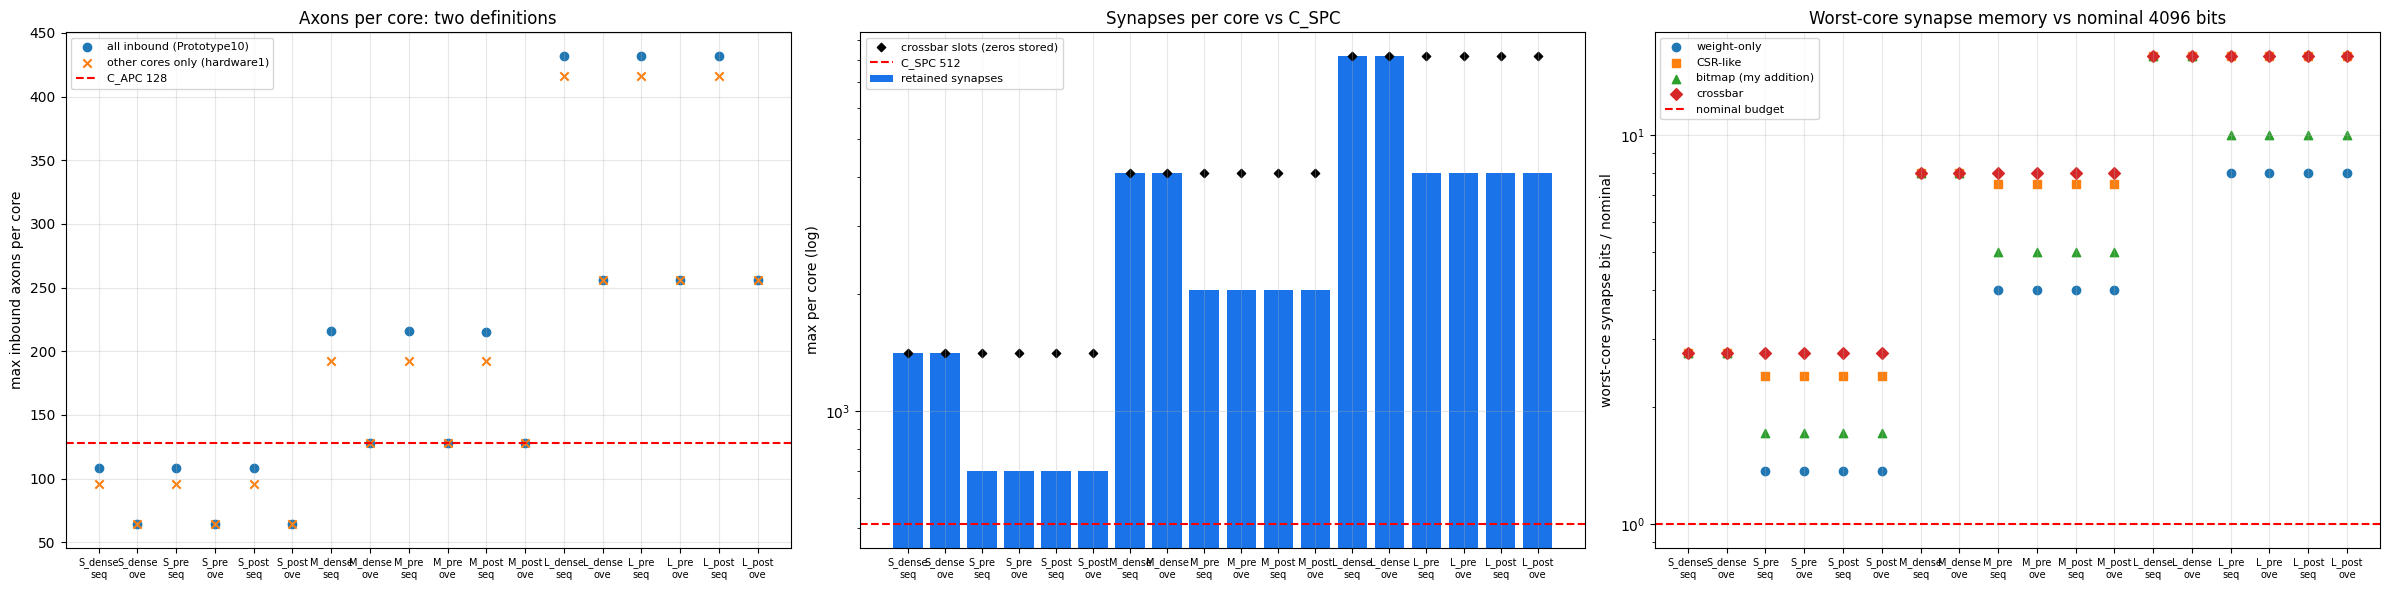

  ✅ Prototype_10 outside hardware_verification unchanged vs snapshot (108 files; added [], removed [], size-changed [])
  ✅ no modification-time changes (0 files differ)

Saved: sram_audit/{sram_audit_summary,sram_per_core}.csv, sram_audit_setup.json, figures/04_sram_audit.png

Cell 4 complete.


In [6]:
# ===================== HW CELL 4: Proof #2 -- SRAM / axon audit with BOTH definitions, partitions of A-D for all 9 models, per-core memory =====================
import os, sys, json, math, pickle, time
sys.dont_write_bytecode = True
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = '/content/drive/MyDrive/Prototype_10'
if not os.path.ismount('/content/drive'):
    from google.colab import drive; drive.mount('/content/drive')
HWDIR = ROOT + '/hardware_verification/code'
if HWDIR not in sys.path: sys.path.insert(0, HWDIR)
from hw_common import chk, soft, hw_path, register_hw, write_json, verify_readonly
config = json.load(open(ROOT + '/config/config.json')); PATHS, HW = config['PATHS'], config['HW']
HWCFG = json.load(open(ROOT + '/hardware_verification/config/hw_config.json'))
if PATHS['code'] not in sys.path: sys.path.insert(0, PATHS['code'])
import p10_model, p10_mapping
p10_mapping.set_hw(HW)
KEYS = HWCFG['models']['keys']; C_NPC, C_APC, C_SPC = HW['C_NPC'], HW['C_APC'], HW['C_SPC']
WB = HWCFG['quantization']['main']['weight_bits']; NOMINAL_BITS = C_SPC * WB
NEURON_BITS = dict(conv=8 + 16 + 24, hidden=8 + 16 + 16 + 16, readout=16)     # (same ASSUMED widths as Cell 3: leak 8b; conv bias 16b + requant 24b; FC bias/gamma/beta 16b; readout bias 16b)
print(f"SRAM AUDIT | C_NPC {C_NPC} (enforced), C_APC {C_APC} axons, C_SPC {C_SPC} synapses | weight bits {WB} | nominal per-core synapse SRAM = C_SPC x weight bits = {NOMINAL_BITS} bits ({NOMINAL_BITS/8192:.2f} KiB)  [ASSUMPTION: C_SPC counts synapse slots at weight width]")
print("Placement does not change SRAM use: pipelines A and B share the SEQUENTIAL partition, C and D share the OVERLAP partition -> each partition is audited once.")

# ---------- 1) Inputs (read-only) and reproducibility of the partitions ----------
HG = pickle.load(open(PATHS['hypergraph'] + '/hypergraphs_val.pkl', 'rb')); hypergraphs, node_maps = HG['hypergraphs'], HG['node_maps']
PART = pickle.load(open(PATHS['hypergraph'] + '/partitions_val.pkl', 'rb'))['partitions']
print("\n[1] PARTITIONS: saved partitions_val.pkl vs recomputed with p10_mapping")
for key in KEYS:
    nodes, h_edges, sf = hypergraphs[key]
    seq = p10_mapping.sequential_partitioning(nodes, C_NPC); ovl = p10_mapping.overlap_partitioning(nodes, h_edges, sf, C_NPC)
    chk(PART[key]['sequential'] == seq and PART[key]['overlap'] == ovl, f"{key}: saved sequential and overlap partitions are identical to the recomputed ones")

# ---------- 2) hardware1 audit, copied (definition HW1: inbound axons counted from OTHER cores only; synapses of all sources) ----------
def hw1_audit(h_edges, partition_map):                                   # (from hardware1 Cell 3 audit_sram_constraints; only the status strings were removed)
    cores = sorted(set(partition_map.values())); inbound_axons = {c: set() for c in cores}; inbound_synapses = {c: 0 for c in cores}
    for src, dsts in h_edges.items():
        src_c = partition_map[src]
        for d in dsts:
            dst_c = partition_map[d]
            if dst_c != src_c: inbound_axons[dst_c].add(src)
            inbound_synapses[dst_c] += 1
    return dict(max_axons=max(len(a) for a in inbound_axons.values()), total_axon_slots=sum(len(a) for a in inbound_axons.values()), max_syn=max(inbound_synapses.values()))

# ---------- 3) Vectorised audit of one partition (both axon definitions, crossbar slots, per-core memory formats) ----------
def audit_partition(key, pm, mode):
    nodes, h_edges, sf = hypergraphs[key]; N = len(nodes); nm = node_maps[key]; lnames = list(nm); sizes = [nm[n][1] for n in lnames]; offs = [nm[n][0] for n in lnames]
    assert offs == list(np.cumsum([0] + sizes[:-1])) and sum(sizes) == N
    lid = np.repeat(np.arange(len(sizes)), sizes); in_f = np.array([0] + sizes[:-1]); infan = in_f[lid]
    P = np.array([pm[n] for n in range(N)]); K = int(P.max()) + 1
    src = np.repeat(np.fromiter(h_edges.keys(), dtype=np.int64), [len(v) for v in h_edges.values()]); dst = np.concatenate([np.asarray(v, dtype=np.int64) for v in h_edges.values()]); pc = P[dst]
    ax_all = np.bincount(np.unique(pc.astype(np.int64) * N + src) // N, minlength=K)                       # Prototype10 definition: every distinct inbound source incl. intra-core
    inter = P[src] != pc; ax_int = np.bincount(np.unique(pc[inter].astype(np.int64) * N + src[inter]) // N, minlength=K)   # hardware1 definition: other cores only
    syn = np.bincount(pc, minlength=K); neu = np.bincount(P, minlength=K)
    slots = np.bincount(P, weights=infan, minlength=K).astype(np.int64)                                    # crossbar semantic: dense positions of every hosted neuron (zeros stored)
    idxb = np.ceil(np.log2(np.maximum(infan, 2)))
    idxb[lid == len(sizes) - 1] = 0   # readout is dense: no CSR index (same convention as Cell 3)                                                       # CSR-like: bits to address a source inside the destination layer's input
    idx_bits = np.bincount(pc, weights=idxb[dst], minlength=K); sparse = mode != 'dense'
    nb = np.array([NEURON_BITS['conv']] + [NEURON_BITS['hidden']] * (len(sizes) - 2) + [NEURON_BITS['readout']])[lid]; neu_bits = np.bincount(P, weights=nb, minlength=K)
    slots_sp = np.bincount(P, weights=np.where(lid == len(sizes) - 1, 0, infan), minlength=K)   # dense positions of the SPARSE layers only
    syn_w = syn * WB; syn_csr = syn_w + (idx_bits if sparse else 0); syn_bitmap = (slots_sp + syn_w) if sparse else syn_w; syn_xbar = slots * WB
    # --- cross-checks against the two reference implementations ---
    ca = p10_mapping.core_audit(h_edges, pm); h1 = hw1_audit(h_edges, pm)
    chk(ca['max axons/core'] == ax_all.max() and ca['max synapses/core'] == syn.max() and ca['cores > C_apc'] == int((ax_all > C_APC).sum()) and ca['cores > C_spc'] == int((syn > C_SPC).sum()),
        f"{key}: vectorised audit == p10_mapping.core_audit (max axons {ca['max axons/core']}, max syn {ca['max synapses/core']})")
    chk(h1['max_axons'] == ax_int.max() and h1['max_syn'] == syn.max() and h1['total_axon_slots'] == ax_int.sum(), f"{key}: vectorised inter-core axons == copied hardware1 audit (max {h1['max_axons']}, total slots {h1['total_axon_slots']})")
    chk(int(syn.sum()) == sum(len(v) for v in h_edges.values()), f"{key}: synapses over cores sum to the hypergraph total ({int(syn.sum()):,})")
    core_rows = []
    for c in range(K):
        mem = P == c; lay = Counter(lnames[l] for l in lid[mem])
        core_rows.append(dict(core=c, neurons=int(neu[c]), layers=" ".join(f"{k}:{v}" for k, v in lay.items()), axons_all=int(ax_all[c]), axons_inter=int(ax_int[c]), synapses=int(syn[c]), crossbar_slots=int(slots[c]),
                              syn_bits_weight_only=int(syn_w[c]), syn_bits_csr=int(syn_csr[c]), syn_bits_bitmap=int(syn_bitmap[c]), syn_bits_crossbar=int(syn_xbar[c]), neuron_bits=int(neu_bits[c])))
    cmax = int(np.argmax(syn)); lay_max = Counter(lnames[l] for l in lid[P == cmax])
    return dict(K=K, neu=neu, ax_all=ax_all, ax_int=ax_int, syn=syn, slots=slots, syn_w=syn_w, syn_csr=syn_csr, syn_bitmap=syn_bitmap, syn_xbar=syn_xbar, neu_bits=neu_bits, idx_total=float(idx_bits.sum()),
                total_syn=int(syn.sum()), conv_w=int(sizes[0] * p10_model.KERNEL), core_rows=core_rows, maxcore=dict(core=cmax, layers=dict(lay_max), fanin=int(in_f[lid[P == cmax]].max())))

SUM, PER = [], []
for key in KEYS:
    size, mode = key.split('_')[0], key.split('_')[1]
    for part, pipes in (('sequential', 'A,B'), ('overlap', 'C,D')):
        a = audit_partition(key, PART[key][part], mode)
        row = dict(variant=key, size=size, mode=mode, partition=part, pipelines=pipes, cores=a['K'], neurons_max=int(a['neu'].max()), neurons_min=int(a['neu'].min()), synapses_total=a['total_syn'],
                   max_axons_all=int(a['ax_all'].max()), cores_over_APC_all=int((a['ax_all'] > C_APC).sum()), max_axons_inter=int(a['ax_int'].max()), cores_over_APC_inter=int((a['ax_int'] > C_APC).sum()),
                   total_inter_axon_slots=int(a['ax_int'].sum()), max_synapses=int(a['syn'].max()), cores_over_SPC=int((a['syn'] > C_SPC).sum()), max_syn_over_C_SPC=float(a['syn'].max() / C_SPC),
                   max_crossbar_slots=int(a['slots'].max()), cores_over_SPC_crossbar=int((a['slots'] > C_SPC).sum()), min_cores_by_synapse_capacity=int(math.ceil(a['total_syn'] / C_SPC)),
                   maxsyn_core_layers=str(a['maxcore']['layers']), maxsyn_core_fanin_per_neuron=a['maxcore']['fanin'],
                   x_nominal_weight_only=float(a['syn_w'].max() / NOMINAL_BITS), x_nominal_csr=float(a['syn_csr'].max() / NOMINAL_BITS), x_nominal_bitmap=float(a['syn_bitmap'].max() / NOMINAL_BITS), x_nominal_crossbar=float(a['syn_xbar'].max() / NOMINAL_BITS),
                   max_core_syn_KiB_weight_only=float(a['syn_w'].max() / 8192), max_core_syn_KiB_csr=float(a['syn_csr'].max() / 8192), max_core_syn_KiB_bitmap=float(a['syn_bitmap'].max() / 8192), max_core_syn_KiB_crossbar=float(a['syn_xbar'].max() / 8192),
                   max_core_neuron_state_KiB=float(a['neu_bits'].max() / 8192))
        row['_tot'] = dict(w=a['syn_w'].sum() + a['conv_w'] * WB, idx=a['idx_total'] if mode != 'dense' else 0.0, xb=(a['slots'].sum() + a['conv_w']) * WB, nb=a['neu_bits'].sum())
        SUM.append(row)
        for r in a['core_rows']: PER.append(dict(variant=key, partition=part, pipelines=pipes, **r))
# consistency with Cell 3 memory table: sums over cores (+ conv weights, which live in the front-end) must reproduce the chip totals
MEM = pd.read_csv(ROOT + '/hardware_verification/quantization/memory.csv'); m8 = MEM[MEM.wb == WB].set_index('variant')
print("\n[2] CROSS-CHECKS")
for r in SUM:
    m = m8.loc[r['variant']]; t = r['_tot']
    chk(abs(t['w'] / 8192 - m.weight_only_KiB) < 1e-6 and abs(t['idx'] / 8192 - m.csr_index_KiB) < 1e-6 and abs(t['xb'] / 8192 - m.crossbar_KiB) < 1e-6 and abs(t['nb'] / 8192 - m.neuron_params_KiB) < 1e-6,
        f"{r['variant']:<12}{r['partition']:<11}: per-core sums reproduce the Cell 3 chip memory (w-only {t['w']/8192:.2f}, index {t['idx']/8192:.2f}, crossbar {t['xb']/8192:.2f}, neuron {t['nb']/8192:.2f} KiB)")
D = pd.DataFrame([{k: v for k, v in r.items() if k != '_tot'} for r in SUM]); PC = pd.DataFrame(PER)
ref = pd.read_csv(PATHS['hypergraph'] + '/mapping_audit.csv'); ok = True
for r in D.itertuples():
    q = ref[(ref.variant == r.variant) & (ref.pipeline == r.partition)].iloc[0]
    ok &= (q.max_axons_core == r.max_axons_all and q.max_synapses_core == r.max_synapses and q.cores_over_C_APC == r.cores_over_APC_all and q.cores_over_C_SPC == r.cores_over_SPC and q.cores == r.cores)
chk(bool(ok), "all 18 partition rows equal Prototype10 hypergraph/mapping_audit.csv (cores, max axons, max synapses, cores over C_APC / C_SPC; Prototype10 definition)")

# ---------- 4) Tables (everything computed; no hard-coded conclusions) ----------
print(f"\n[3] AUDIT PER PARTITION (limits: C_NPC {C_NPC}, C_APC {C_APC}, C_SPC {C_SPC}). axons: P10 = all inbound sources, HW1 = other cores only. syn = retained synapses; xbar = crossbar slots (zeros stored)")
print(f"{'variant':<12}{'part.':<7}{'pipes':<5}{'cores':>6}{'n max/min':>10}{'axons P10':>10}{'>APC':>5}{'axons HW1':>10}{'>APC':>5}{'syn max':>8}{'>SPC':>5}{'xN':>6}{'xbar max':>9}{'>SPC':>5}{'cores needed by syn':>20}")
for r in D.itertuples():
    print(f"{r.variant:<12}{r.partition[:3]:<7}{r.pipelines:<5}{r.cores:>6}{str(r.neurons_max)+'/'+str(r.neurons_min):>10}{r.max_axons_all:>10}{r.cores_over_APC_all:>5}{r.max_axons_inter:>10}{r.cores_over_APC_inter:>5}{r.max_synapses:>8}{r.cores_over_SPC:>5}{r.max_syn_over_C_SPC:>6.1f}{r.max_crossbar_slots:>9}{r.cores_over_SPC_crossbar:>5}{r.min_cores_by_synapse_capacity:>13} (used {r.cores})")
print("   xN = max synapses per core / C_SPC. 'cores needed by syn' = ceil(total synapses / C_SPC): a lower bound for ANY partition, ignoring the 32-neuron cap.")
print("\n[4] WHERE THE WORST CORE COMES FROM (core with the most synapses): hosted layers and fan-in per neuron")
for r in D.itertuples(): print(f"  {r.variant:<12}{r.partition:<11} max {r.max_synapses:>5} syn: layers {r.maxsyn_core_layers}, fan-in {r.maxsyn_core_fanin_per_neuron}")
print(f"\n[5] PER-CORE SYNAPSE MEMORY, worst core, multiples of the nominal budget ({NOMINAL_BITS} bits). formats: weight-only / CSR-like (+index) / bitmap (+1 bit per dense position; MY ADDITION) / crossbar (zeros stored). Dense: no index/bitmap")
print(f"{'variant':<12}{'part.':<7}{'w-only':>8}{'CSR':>8}{'bitmap':>8}{'xbar':>8}{'worst core KiB: w-only':>24}{'CSR':>7}{'bitmap':>8}{'xbar':>7}{'neuron state KiB':>18}")
for r in D.itertuples(): print(f"{r.variant:<12}{r.partition[:3]:<7}{r.x_nominal_weight_only:>8.1f}{r.x_nominal_csr:>8.1f}{r.x_nominal_bitmap:>8.1f}{r.x_nominal_crossbar:>8.1f}{r.max_core_syn_KiB_weight_only:>24.2f}{r.max_core_syn_KiB_csr:>7.2f}{r.max_core_syn_KiB_bitmap:>8.2f}{r.max_core_syn_KiB_crossbar:>7.2f}{r.max_core_neuron_state_KiB:>18.3f}")
print("\n[6] COMPUTED SUMMARY")
n = len(D)
print(f"  partitions violating C_SPC (retained synapses): {int((D.cores_over_SPC > 0).sum())} of {n}; (crossbar slots): {int((D.cores_over_SPC_crossbar > 0).sum())} of {n}")
print(f"  partitions violating C_APC: Prototype10 definition {int((D.cores_over_APC_all > 0).sum())} of {n}; hardware1 definition {int((D.cores_over_APC_inter > 0).sum())} of {n}")
print(f"  worst core: {D.max_syn_over_C_SPC.max():.1f}x C_SPC ({D.loc[D.max_syn_over_C_SPC.idxmax(), 'variant']}, {D.loc[D.max_syn_over_C_SPC.idxmax(), 'partition']}); least-violating partition: {D.max_syn_over_C_SPC.min():.2f}x ({D.loc[D.max_syn_over_C_SPC.idxmin(), 'variant']}, {D.loc[D.max_syn_over_C_SPC.idxmin(), 'partition']})")
dd = D[D.cores_over_APC_all != D.cores_over_APC_inter]
print(f"  rows where the two axon definitions give a different number of violating cores: {len(dd)} of {n}" + (": " + ", ".join(f"{r.variant}/{r.partition[:3]} ({r.cores_over_APC_all} vs {r.cores_over_APC_inter})" for r in dd.itertuples()) if len(dd) else ""))
for sz in ('S', 'M', 'L'):
    for md in ('dense', 'pre', 'post'):
        s = D[(D['size'] == sz) & (D['mode'] == md)]; print(f"  {sz}_{md:<6}: C_SPC violations seq/ovl {s.cores_over_SPC.tolist()} of {s.cores.tolist()} cores | C_APC (P10) {s.cores_over_APC_all.tolist()} | C_APC (HW1) {s.cores_over_APC_inter.tolist()}")
soft(len(D[D.cores_over_SPC > 0]) == 0, "all partitions within C_SPC (if this is a warning, every mapping is a communication-cost estimate for a capacity-violating mapping)")

# ---------- 5) Figure ----------
lab = [f"{r.variant[:-4]}\n{r.partition[:3]}" for r in D.itertuples()]; x = np.arange(len(D))
fig, ax = plt.subplots(1, 3, figsize=(24, 6))
ax[0].scatter(x, D.max_axons_all, marker='o', label='all inbound (Prototype10)'); ax[0].scatter(x, D.max_axons_inter, marker='x', label='other cores only (hardware1)'); ax[0].axhline(C_APC, color='r', ls='--', label=f'C_APC {C_APC}')
ax[0].set_ylabel('max inbound axons per core'); ax[0].set_title('Axons per core: two definitions')
ax[1].bar(x, D.max_synapses, color='#1a73e8', label='retained synapses'); ax[1].scatter(x, D.max_crossbar_slots, marker='D', color='k', s=18, label='crossbar slots (zeros stored)'); ax[1].axhline(C_SPC, color='r', ls='--', label=f'C_SPC {C_SPC}'); ax[1].set_yscale('log')
ax[1].set_ylabel('max per core (log)'); ax[1].set_title('Synapses per core vs C_SPC')
for col, nm, mk in (('x_nominal_weight_only', 'weight-only', 'o'), ('x_nominal_csr', 'CSR-like', 's'), ('x_nominal_bitmap', 'bitmap (my addition)', '^'), ('x_nominal_crossbar', 'crossbar', 'D')): ax[2].scatter(x, D[col], marker=mk, label=nm)
ax[2].axhline(1.0, color='r', ls='--', label='nominal budget'); ax[2].set_yscale('log'); ax[2].set_ylabel('worst-core synapse bits / nominal'); ax[2].set_title(f'Worst-core synapse memory vs nominal {NOMINAL_BITS} bits')
for a_ in ax: a_.set_xticks(x); a_.set_xticklabels(lab, fontsize=7); a_.legend(fontsize=8); a_.grid(alpha=0.3)
plt.tight_layout(); fp = hw_path('figures', '04_sram_audit.png'); plt.savefig(fp, dpi=200, bbox_inches='tight'); plt.show(); register_hw(fp, "SRAM audit: axons (two definitions), synapses vs C_SPC, worst-core memory per format, all 9 models x 2 partitions")

# ---------- 6) Save ----------
p = hw_path('sram_audit', 'sram_audit_summary.csv'); D.round(4).to_csv(p, index=False); register_hw(p, "SRAM audit per variant and partition (A,B = sequential; C,D = overlap): both axon definitions, retained and crossbar synapses, worst-core memory per format")
p = hw_path('sram_audit', 'sram_per_core.csv'); PC.to_csv(p, index=False); register_hw(p, "per-core rows: neurons, layers, axons (both definitions), synapses, crossbar slots, synapse bits per format, neuron-state bits")
write_json(hw_path('sram_audit', 'sram_audit_setup.json'), dict(C_NPC=C_NPC, C_APC=C_APC, C_SPC=C_SPC, weight_bits=WB, nominal_budget_bits=NOMINAL_BITS, neuron_bits=NEURON_BITS,
           definitions=dict(P10="distinct inbound sources incl. intra-core (p10_mapping.core_audit)", HW1="distinct inbound sources from OTHER cores only; synapses of all sources (hardware1 Cell 3)", crossbar="dense positions of every hosted neuron"),
           note="placement does not affect SRAM; A,B share the sequential partition, C,D the overlap partition; conv weights are front-end memory and not part of any core's SRAM here"), "assumptions and definitions used by the SRAM audit")
verify_readonly()
print("\nSaved: sram_audit/{sram_audit_summary,sram_per_core}.csv, sram_audit_setup.json, figures/04_sram_audit.png")
print("\nCell 4 complete.")

In [7]:
# ===================== HW CELL 5: regenerate placements A/B/C/D (seeds as Prototype10 Cell 11), verify analytical metrics vs the saved CSVs, save as JSON =====================
import os, sys, json, math, random, pickle, time
sys.dont_write_bytecode = True
import numpy as np, pandas as pd

ROOT = '/content/drive/MyDrive/Prototype_10'
if not os.path.ismount('/content/drive'):
    from google.colab import drive; drive.mount('/content/drive')
HWDIR = ROOT + '/hardware_verification/code'
if HWDIR not in sys.path: sys.path.insert(0, HWDIR)
from hw_common import chk, soft, hw_path, register_hw, write_json, verify_readonly
config = json.load(open(ROOT + '/config/config.json')); PATHS, HW = config['PATHS'], config['HW']
HWCFG = json.load(open(ROOT + '/hardware_verification/config/hw_config.json'))
if PATHS['code'] not in sys.path: sys.path.insert(0, PATHS['code'])
import p10_mapping
from p10_mapping import (hilbert_initial_placement, linear_placement, placement_refinement, evaluate_mapping, _grid, set_hw)
set_hw(HW)
KEYS = HWCFG['models']['keys']

FORCE = False                                           # True = regenerate even if mappings/mapping_{key}.json exists
SEEDS, ITERS = list(HW['PLACEMENT_SEEDS']), HW['ITERATIONS']      # [42..46], 1500 (Prototype10 Cell 11 control panel)
METRICS = ["Connectivity", "Total Energy (pJ)", "Average Latency (ns)", "Energy-Latency Product", "Synaptic Reuse"]
MAPDIR = hw_path('mappings', 'x')[:-1]
print(f"PLACEMENT REGENERATION | seeds {SEEDS} | {ITERS} swaps | Hilbert start | A,C deterministic (linear), B,D = refinement | FORCE={FORCE}")

HG = pickle.load(open(PATHS['hypergraph'] + '/hypergraphs_val.pkl', 'rb')); hypergraphs = HG['hypergraphs']
PART = pickle.load(open(PATHS['hypergraph'] + '/partitions_val.pkl', 'rb'))['partitions']

# ---------- helpers ----------
def pl_json(place): return {str(c): [int(x), int(y)] for c, (x, y) in sorted(place.items())}
def pl_load(d): return {int(c): (int(v[0]), int(v[1])) for c, v in d.items()}
def refined_place(pm, h_edges, sf, seed):                # (from Prototype10 Cell 11 refined(): same calls, same order; only the return value differs)
    place, _ = hilbert_initial_placement(pm); random.seed(seed)
    place, _ = placement_refinement(place, pm, h_edges, sf, iterations=ITERS)
    return place
def check_placement(pm, place, label):
    cores = set(pm.values()); n = _grid(len(cores))
    chk(set(place) == cores, f"{label}: every core placed exactly once ({len(cores)} cores)")
    chk(len(set(place.values())) == len(place) and all(0 <= x < n and 0 <= y < n for x, y in place.values()), f"{label}: distinct grid cells inside the {n}x{n} grid")

def generate(key):
    nodes, h_edges, sf = hypergraphs[key]; N = len(nodes)
    seq, ovl = PART[key]['sequential'], PART[key]['overlap']
    assert sorted(seq) == list(range(N)) and sorted(ovl) == list(range(N)), "node ids are not 0..N-1"
    pA, nA = linear_placement(seq); pC, nC = linear_placement(ovl)
    out = dict(variant=key, placement_seeds=SEEDS, iterations=ITERS, n_nodes=N, grid_n=int(nA), cores=len(set(seq.values())),
               partitions=dict(sequential=[int(seq[n]) for n in range(N)], overlap=[int(ovl[n]) for n in range(N)]),
               placements=dict(A=dict(partition="sequential", placement=pl_json(pA)), C=dict(partition="overlap", placement=pl_json(pC)),
                               B=dict(partition="sequential", runs={str(s): pl_json(refined_place(seq, h_edges, sf, s)) for s in SEEDS}),
                               D=dict(partition="overlap", runs={str(s): pl_json(refined_place(ovl, h_edges, sf, s)) for s in SEEDS})))
    assert nA == nC
    return out

# ---------- 1) generate (resumable) ----------
print("\n[1] GENERATE / LOAD")
MAPS = {}
for key in KEYS:
    path = os.path.join(MAPDIR, f"mapping_{key}.json"); t0 = time.time()
    if os.path.exists(path) and not FORCE:
        MAPS[key] = json.load(open(path)); print(f"  {key:<12} loaded existing file")
    else:
        MAPS[key] = generate(key); write_json(path, MAPS[key], f"{key}: partitions (list, index = node id -> core) and regenerated placements A, C and B, D per placement seed (core -> [x, y])")
        print(f"  {key:<12} generated in {time.time()-t0:.1f}s")

# ---------- 2) evaluate from the SAVED JSON (proves the round trip) and compare with Prototype10's CSVs ----------
print("\n[2] ANALYTICAL METRICS RECOMPUTED FROM THE JSON FILES vs Prototype10 CSVs")
mm = pd.read_csv(PATHS['hypergraph'] + '/mapping_metrics_val.csv').set_index(['variant', 'pipeline'])
ab = pd.read_csv(PATHS['hypergraph'] + '/ablation_val.csv').set_index('variant')
TOL_MM, TOL_AB = 2e-5, 1e-4                              # CSVs were rounded to 5 / 4 decimals
rows, bad = [], []
for key in KEYS:
    nodes, h_edges, sf = hypergraphs[key]; M = MAPS[key]; parts = {k: {n: int(c) for n, c in enumerate(M['partitions'][k])} for k in ('sequential', 'overlap')}
    assert parts['sequential'] == PART[key]['sequential'] and parts['overlap'] == PART[key]['overlap'], f"{key}: saved partition lists differ from partitions_val.pkl"
    res = {}
    for lab in "ABCD":
        e = M['placements'][lab]; pm = parts[e['partition']]
        runs = [pl_load(e['placement'])] if 'placement' in e else [pl_load(e['runs'][str(s)]) for s in SEEDS]
        for i, pl in enumerate(runs): check_placement(pm, pl, f"{key} {lab}" + (f" seed {SEEDS[i]}" if len(runs) > 1 else ""))
        ev = [evaluate_mapping(h_edges, sf, pm, pl) for pl in runs]; res[lab] = ev
        diffs = []
        for m_ in METRICS:
            mean, std = float(np.mean([r[m_] for r in ev])), float(np.std([r[m_] for r in ev]))
            diffs += [abs(mean - mm.loc[(key, lab), m_ + " mean"]), abs(std - mm.loc[(key, lab), m_ + " std"])]
        elp_m, elp_s = float(np.mean([r["Energy-Latency Product"] for r in ev])), float(np.std([r["Energy-Latency Product"] for r in ev]))
        rows.append(dict(variant=key, pipeline=lab, n_runs=len(ev), ELP_mean=elp_m, ELP_std=elp_s, ELP_mean_saved=float(mm.loc[(key, lab), "Energy-Latency Product mean"]),
                         ELP_std_saved=float(mm.loc[(key, lab), "Energy-Latency Product std"]), max_abs_diff_all_10_values=max(diffs)))
        if max(diffs) > TOL_MM: bad.append(f"{key} {lab}: max diff {max(diffs):.3g}")
    el = {l: (float(np.mean([r['Energy-Latency Product'] for r in res[l]])), float(np.std([r['Energy-Latency Product'] for r in res[l]]))) for l in res}
    d_ab = max(abs(el['A'][0] - ab.loc[key, 'A']), abs(el['B'][0] - ab.loc[key, 'B']), abs(el['B'][1] - ab.loc[key, 'B_std']), abs(el['C'][0] - ab.loc[key, 'C']), abs(el['D'][0] - ab.loc[key, 'D']), abs(el['D'][1] - ab.loc[key, 'D_std']))
    if d_ab > TOL_AB: bad.append(f"{key}: ablation_val.csv max diff {d_ab:.3g}")
    print(f"  {key:<12} metrics equal Prototype10 CSVs: {'yes' if not any(key in b for b in bad) else 'NO'}")
V = pd.DataFrame(rows); V_path = hw_path('mappings', 'elp_verification.csv'); V.round(6).to_csv(V_path, index=False); register_hw(V_path, "regenerated analytical ELP (and max diff over all 5 metrics) vs Prototype10 mapping_metrics_val.csv, per variant and pipeline")
chk(not bad, f"all {len(rows)} (variant, pipeline) rows reproduce mapping_metrics_val.csv (tol {TOL_MM:g}) and ablation_val.csv (tol {TOL_AB:g})" if not bad else f"MISMATCH: {bad[:6]}")

# ---------- 3) table (analytical ELP, pJ*ns, lower is better; gains in %) ----------
print("\n[3] ANALYTICAL ELP (pJ*ns; B and D: mean±std over 5 placement seeds) AND GAINS vs A")
print(f"{'variant':<12}{'cores':>6}{'grid':>6}{'A':>11}{'B':>17}{'C':>11}{'D':>17}{'D vs A':>9}{'B vs A':>9}{'C vs A':>9}")
for key in KEYS:
    g = {l: V[(V.variant == key) & (V.pipeline == l)].iloc[0] for l in "ABCD"}; a = g['A'].ELP_mean
    print(f"{key:<12}{MAPS[key]['cores']:>6}{MAPS[key]['grid_n']:>5}x{g['A'].ELP_mean:>11.1f}{g['B'].ELP_mean:>10.1f}±{g['B'].ELP_std:<6.1f}{g['C'].ELP_mean:>11.1f}{g['D'].ELP_mean:>10.1f}±{g['D'].ELP_std:<6.1f}"
          f"{(a-g['D'].ELP_mean)/a*100:>+8.1f}%{(a-g['B'].ELP_mean)/a*100:>+8.1f}%{(a-g['C'].ELP_mean)/a*100:>+8.1f}%")
print("  main NoC tables will use placement seed 42 for B and D; the 5-seed runs are stored in each JSON for the robustness table.")

# ---------- 4) bookkeeping ----------
mm_ = json.load(open(ROOT + '/hardware_verification/manifest_hw.json'))
chk(all(os.path.relpath(os.path.join(MAPDIR, f"mapping_{k}.json"), ROOT + '/hardware_verification') in mm_ for k in KEYS), "all 9 mapping JSON files registered in manifest_hw.json")
verify_readonly()
print(f"\nSaved: mappings/mapping_{{9 variants}}.json, mappings/elp_verification.csv")
print("\nCell 5 complete.")

PLACEMENT REGENERATION | seeds [42, 43, 44, 45, 46] | 1500 swaps | Hilbert start | A,C deterministic (linear), B,D = refinement | FORCE=False

[1] GENERATE / LOAD
  S_dense_s42  generated in 2.5s
  S_pre_s42    generated in 2.1s
  S_post_s42   generated in 2.0s
  M_dense_s42  generated in 3.7s
  M_pre_s42    generated in 3.7s
  M_post_s42   generated in 3.8s
  L_dense_s42  generated in 14.2s
  L_pre_s42    generated in 14.0s
  L_post_s42   generated in 14.1s

[2] ANALYTICAL METRICS RECOMPUTED FROM THE JSON FILES vs Prototype10 CSVs
  ✅ S_dense_s42 A: every core placed exactly once (4 cores)
  ✅ S_dense_s42 A: distinct grid cells inside the 2x2 grid
  ✅ S_dense_s42 B seed 42: every core placed exactly once (4 cores)
  ✅ S_dense_s42 B seed 42: distinct grid cells inside the 2x2 grid
  ✅ S_dense_s42 B seed 43: every core placed exactly once (4 cores)
  ✅ S_dense_s42 B seed 43: distinct grid cells inside the 2x2 grid
  ✅ S_dense_s42 B seed 44: every core placed exactly once (4 cores)
  ✅ S

In [11]:
# ===================== HW CELL 6: Proof #3a -- TRACE-DRIVEN NoC replay (evidence level ii) on the 32 saved trace windows, A/B/C/D, 9 variants =====================
# Vectorised: counts[t, w, src_core*K+dst_core] = spikes[t, w, :] @ pair matrix; link load = counts @ XY path incidence. Validated EXACTLY against a plain per-packet loop (hardware1 style).
import os, sys, json, math, pickle, time
sys.dont_write_bytecode = True
from collections import Counter
import numpy as np, pandas as pd

ROOT = '/content/drive/MyDrive/Prototype_10'
if not os.path.ismount('/content/drive'):
    from google.colab import drive; drive.mount('/content/drive')
HWDIR = ROOT + '/hardware_verification/code'
if HWDIR not in sys.path: sys.path.insert(0, HWDIR)
from hw_common import chk, soft, hw_path, register_hw, write_json, verify_readonly
config = json.load(open(ROOT + '/config/config.json')); PATHS, HW = config['PATHS'], config['HW']
HWCFG = json.load(open(ROOT + '/hardware_verification/config/hw_config.json'))
KEYS = HWCFG['models']['keys']; NOC = HWCFG['noc']
E_R, E_T, L_R, L_T = HW['E_R'], HW['E_T'], HW['L_R'], HW['L_T']
E_BUF, L_STALL = NOC['E_BUF_pJ'], NOC['L_STALL_ns']                    # ASSUMPTIONS from hardware1 (not Loihi constants)
SEEDS, MAIN_SEED = list(HW['PLACEMENT_SEEDS']), NOC['main_placement_seed']
TOL_PTS = 5.0                    # ASSUMPTION, declared before running: trace gain within +-5 percentage points of the analytical gain = "confirms"
FORCE_VALIDATION = False
PART_OF = dict(A='sequential', B='sequential', C='overlap', D='overlap')
try:
    lc = json.load(open(PATHS['data'] + '/label_classes.json')); CLASSES = list(lc) if isinstance(lc, list) and len(lc) == 4 else None
except Exception: CLASSES = None
if CLASSES is None: CLASSES = ['feet', 'left_hand', 'right_hand', 'tongue']; print("  (class names from the plan text; label_classes.json was not a plain list of 4)")
print(f"TRACE-DRIVEN NoC REPLAY | evidence level (ii) | classes {CLASSES} | E_R {E_R} E_T {E_T} pJ, L_R {L_R} L_T {L_T} ns | stall energy {E_BUF} pJ and stall latency {L_STALL} ns are ASSUMPTIONS (hardware1)")
print("stall definition = hardware1 code: per tick and link with m packets, stalls += 1+2+...+(m-1) = m(m-1)/2 (serialisation wait; stalls do not delay other packets, no buffers, no backpressure). 'excess' = sum max(m-1,0) is reported separately.")

HG = pickle.load(open(PATHS['hypergraph'] + '/hypergraphs_val.pkl', 'rb')); hypergraphs, node_maps = HG['hypergraphs'], HG['node_maps']
MAPS = {k: json.load(open(hw_path('mappings', f'mapping_{k}.json'))) for k in KEYS}
def pl_load(d): return {int(c): (int(v[0]), int(v[1])) for c, v in d.items()}

# ---------- helpers ----------
def load_trace(key):
    z = np.load(f"{PATHS['spike_traces']}/trace_{key}.npz"); nm = node_maps[key]; spk_names = [n for n in nm if n != 'readout']
    chk(z['layer_names'].tolist() == spk_names, f"{key}: trace layers {z['layer_names'].tolist()} == hypergraph spiking layers")
    T, W = int(z['T']), len(z['positions']); N = sum(sz for _, (st, sz) in nm.items()); spk = np.zeros((T, W, N), np.uint8)
    for i, n in enumerate(spk_names):
        st, sz = nm[n]; a = z[f"L{i+1}"]; assert a.shape == (T, W, sz), f"{key} {n}: {a.shape} != {(T, W, sz)}"; spk[:, :, st:st + sz] = a
    return spk, z['labels'], z['positions']

def pair_matrix(h_edges, pm, N, K):          # one packet per (spiking source neuron, destination core != own core): exactly the analytical pair definition
    S = np.zeros((N, K * K), np.float32)
    for s, ds in h_edges.items():
        sc = pm[s]
        for dc in {pm[d] for d in ds if pm[d] != sc}: S[s, sc * K + dc] = 1
    return S

def noc_tables(place, K):                    # deterministic XY routing (X first, then Y), directed links (same as hardware1)
    links, paths = {}, {}
    for sc in range(K):
        for dc in range(K):
            if sc == dc: continue
            (cx, cy), (x2, y2) = place[sc], place[dc]; ids = []
            while cx != x2:
                nx = cx + (1 if x2 > cx else -1); ids.append(links.setdefault(((cx, cy), (nx, cy)), len(links))); cx = nx
            while cy != y2:
                ny = cy + (1 if y2 > cy else -1); ids.append(links.setdefault(((cx, cy), (cx, ny)), len(links))); cy = ny
            paths[(sc, dc)] = ids
    Pinc = np.zeros((K * K, max(len(links), 1))); dist = np.zeros((K, K))
    for (sc, dc), ids in paths.items():
        dist[sc, dc] = len(ids)
        for l in ids: Pinc[sc * K + dc, l] = 1
    return dist, Pinc

def replay(counts, place, T, W, K):
    dist, Pinc = noc_tables(place, K)
    pk, hp, link = counts.sum(1), counts @ dist.reshape(-1), counts @ Pinc          # float64: exact integer sums
    r = lambda a: a.reshape(T, W)
    return dict(packets=r(pk).sum(0), hops=r(hp).sum(0), stalls=r((link * (link - 1) / 2).sum(1)).sum(0),
                excess=r(np.maximum(link - 1, 0).sum(1)).sum(0), peak=r(link.max(1)).max(0), maxcum=link.reshape(T, W, -1).sum(0).max(1))

def derive(m):
    p = m['packets']; e = m['hops'] * (E_R + E_T) + p * E_R; se = m['stalls'] * E_BUF; q = np.maximum(p, 1)
    li = np.where(p > 0, (m['hops'] * (L_R + L_T) + p * L_R) / q, 0.0); lr = li + np.where(p > 0, m['stalls'] * L_STALL / q, 0.0)
    return dict(m, energy_pJ=e, stall_energy_pJ=se, lat_ideal_ns=li, lat_real_ns=lr, ELP_ideal=e * li, ELP_stall=(e + se) * lr)

def loop_window(spk_tn, h_edges, pm, place):   # (from hardware1 Cell 4 simulate_cycle_accurate_xy_noc: same path construction and counters; energy/latency formulas removed, only integer counters kept)
    xy = {}
    for c1, (x1, y1) in place.items():
        for c2, (x2, y2) in place.items():
            if c1 == c2: continue
            links = []; cx, cy = x1, y1
            while cx != x2: nx = cx + (1 if x2 > cx else -1); links.append(((cx, cy), (nx, cy))); cx = nx
            while cy != y2: ny = cy + (1 if y2 > cy else -1); links.append(((cx, cy), (cx, ny))); cy = ny
            xy[(c1, c2)] = links
    s2d = {}
    for src, dsts in h_edges.items():
        sc = pm[src]; dc = list({pm[d] for d in set(dsts) if pm[d] != sc})
        if dc: s2d[src] = (sc, dc)
    packets = hops = stalls = peak = 0; cum = Counter()
    for t in range(spk_tn.shape[0]):
        usage = Counter()
        for src in np.where(spk_tn[t] > 0)[0]:
            if src not in s2d: continue
            sc, dcs = s2d[src]
            for dc in dcs:
                packets += 1; lk = xy[(sc, dc)]; hops += len(lk)
                for l in lk:
                    usage[l] += 1; cum[l] += 1
                    if usage[l] > 1: stalls += usage[l] - 1
        if usage: peak = max(peak, max(usage.values()))
    return dict(packets=packets, hops=hops, stalls=stalls, peak=peak, maxcum=max(cum.values()) if cum else 0)

# ---------- 1) replay everything (vectorised) ----------
print("\n[1] LOAD TRACES AND REPLAY (32 windows x 201 ticks, all placements incl. the 5 seeds of B and D)")
R, LAB, STRESS, DATA = {}, {}, {}, {}
for key in KEYS:
    t0 = time.time(); spk, labels, pos = load_trace(key); T, W, N = spk.shape
    nodes, h_edges, sf = hypergraphs[key]; M = MAPS[key]; K = M['cores']
    parts = {k: {n: int(c) for n, c in enumerate(M['partitions'][k])} for k in ('sequential', 'overlap')}
    chk(max(h_edges) < N and all(sz == 0 or spk[:, :, st:st + sz].any() or True for _, (st, sz) in node_maps[key].items()), f"{key}: hypergraph sources inside the node range (N={N})")
    chk(not spk[:, :, node_maps[key]['readout'][0]:].any(), f"{key}: readout (non-spiking) nodes carry no spikes in the trace")
    X = spk.reshape(T * W, N).astype(np.float32)
    counts = {p: (X @ pair_matrix(h_edges, parts[p], N, K)).astype(np.float64) for p in ('sequential', 'overlap')}
    pls = dict(A=[pl_load(M['placements']['A']['placement'])], C=[pl_load(M['placements']['C']['placement'])],
               B=[pl_load(M['placements']['B']['runs'][str(s)]) for s in SEEDS], D=[pl_load(M['placements']['D']['runs'][str(s)]) for s in SEEDS])
    for lab in "ABCD":
        for i, pl in enumerate(pls[lab]):
            R[(key, lab, SEEDS[i] if lab in 'BD' else None)] = derive(replay(counts[PART_OF[lab]], pl, T, W, K))
    LAB[key] = labels; DATA[key] = dict(spk=spk, h_edges=h_edges, parts=parts, pls=pls)
    STRESS[key] = int(np.argmax(R[(key, 'A', None)]['packets']))
    print(f"  {key:<12} N={N:<4} cores={K:<3} windows={W} T={T} | mean packets/window under A: {R[(key,'A',None)]['packets'].mean():,.0f} | {time.time()-t0:.1f}s")
ms = lambda lab: MAIN_SEED if lab in 'BD' else None

# ---------- 2) validation: vectorised == plain per-packet loop (exact integers), window 0, pipelines A and D ----------
print("\n[2] VALIDATION: vectorised replay vs plain per-packet loop (hardware1 style), window 0, EXACT equality of integer counters")
vp = hw_path('noc', 'trace_validation.csv')
if os.path.exists(vp) and not FORCE_VALIDATION:
    V = pd.read_csv(vp); print(f"  loaded existing {vp} (FORCE_VALIDATION=True reruns the loop)")
else:
    vrows = []
    for key in KEYS:
        d = DATA[key]
        for lab in ('A', 'D'):
            pl = d['pls'][lab][0 if lab == 'A' else SEEDS.index(MAIN_SEED)]; t0 = time.time()
            lp = loop_window(d['spk'][:, 0, :], d['h_edges'], d['parts'][PART_OF[lab]], pl); vec = R[(key, lab, ms(lab))]
            row = dict(variant=key, pipeline=lab, window=0)
            for k in ('packets', 'hops', 'stalls', 'peak', 'maxcum'): row[k + '_loop'] = int(lp[k]); row[k + '_vec'] = int(round(float(vec[k][0])))
            row['equal'] = all(row[k + '_loop'] == row[k + '_vec'] for k in ('packets', 'hops', 'stalls', 'peak', 'maxcum')); vrows.append(row)
            print(f"  {'✅' if row['equal'] else '❌'} {key:<12} {lab}: packets {lp['packets']:,} hops {lp['hops']:,} stalls {lp['stalls']:,} peak {lp['peak']} maxcum {lp['maxcum']:,} ({time.time()-t0:.1f}s)")
    V = pd.DataFrame(vrows); V.to_csv(vp, index=False); register_hw(vp, "trace replay validation: vectorised counters vs plain per-packet loop (window 0, pipelines A and D)")
chk(bool(V['equal'].all()) and len(V) == 2 * len(KEYS), f"vectorised replay == per-packet loop for all {len(V)} (variant, pipeline) checks")

# ---------- 3) summaries ----------
def agg(m, idx):
    d = {k: float(np.mean(m[k][idx])) for k in ('packets', 'hops', 'stalls', 'excess', 'energy_pJ', 'stall_energy_pJ', 'lat_ideal_ns', 'lat_real_ns', 'ELP_ideal', 'ELP_stall')}
    d.update(peak_mean=float(np.mean(m['peak'][idx])), peak_max=float(np.max(m['peak'][idx])), maxcum_max=float(np.max(m['maxcum'][idx])), n_windows=len(idx)); return d
pct = lambda a, x: float((a - x) / a * 100) if a > 0 else float('nan')
SUMROWS, WROWS = [], []
for key in KEYS:
    lab_ = LAB[key]; scopes = {'overall': np.arange(len(lab_))}
    for c, nme in enumerate(CLASSES): scopes[nme] = np.where(lab_ == c)[0]
    scopes[f"stress(w{STRESS[key]},{CLASSES[int(lab_[STRESS[key]])]})"] = np.array([STRESS[key]])
    for sc_name, idx in scopes.items():
        ag = {lab: agg(R[(key, lab, ms(lab))], idx) for lab in "ABCD"}
        for lab in "ABCD":
            a = ag['A']; x = ag[lab]
            SUMROWS.append(dict(variant=key, pipeline=lab, scope=sc_name, **x, gain_ELP_ideal_pct=pct(a['ELP_ideal'], x['ELP_ideal']), gain_ELP_stall_pct=pct(a['ELP_stall'], x['ELP_stall']),
                                red_packets_pct=pct(a['packets'], x['packets']), red_hops_pct=pct(a['hops'], x['hops']), red_stalls_pct=pct(a['stalls'], x['stalls'])))
    for lab in "ABCD":
        m = R[(key, lab, ms(lab))]
        for w in range(len(lab_)):
            WROWS.append(dict(variant=key, pipeline=lab, placement_seed=ms(lab), window=w, label=CLASSES[int(lab_[w])], **{k: float(m[k][w]) for k in m}))
SUM = pd.DataFrame(SUMROWS); WDF = pd.DataFrame(WROWS)
ov = SUM[SUM.scope == 'overall']

print("\n" + "=" * 150)
print(f"[3] OVERALL (mean over 32 windows; B and D use placement seed {MAIN_SEED}). ELP in pJ*ns per 201-tick window: compare GAINS, never absolute values with the analytical table.")
print("=" * 150)
print(f"{'variant':<12}{'pipe':>5}{'packets':>11}{'hops':>12}{'stalls m(m-1)/2':>17}{'excess':>11}{'peak max':>9}{'E (nJ)':>10}{'lat ideal':>10}{'lat+stall':>10}{'ELP ideal':>13}{'ELP+stall':>13}{'gain ideal':>11}{'gain stall':>11}")
for r in ov.itertuples():
    print(f"{r.variant:<12}{r.pipeline:>5}{r.packets:>11,.0f}{r.hops:>12,.0f}{r.stalls:>17,.0f}{r.excess:>11,.0f}{r.peak_max:>9.0f}{r.energy_pJ/1000:>10.2f}{r.lat_ideal_ns:>10.3f}{r.lat_real_ns:>10.3f}{r.ELP_ideal:>13.4g}{r.ELP_stall:>13.4g}{r.gain_ELP_ideal_pct:>+10.1f}%{r.gain_ELP_stall_pct:>+10.1f}%")
    if r.pipeline == 'D': print("-" * 150)

print("\n[4] PER CLASS: D vs A ELP gain, ideal-latency ELP | with-stall ELP (mean over the 8 windows of each class)")
print(f"{'variant':<12}" + "".join(f"{c:>26}" for c in CLASSES))
for key in KEYS:
    cells = []
    for c in CLASSES:
        r = SUM[(SUM.variant == key) & (SUM.pipeline == 'D') & (SUM.scope == c)].iloc[0]; cells.append(f"{r.gain_ELP_ideal_pct:>+10.1f}% | {r.gain_ELP_stall_pct:>+8.1f}%")
    print(f"{key:<12}" + "".join(f"{x:>26}" for x in cells))

print("\n[5] DATA-CHOSEN STRESS WINDOW (highest packet count under mapping A; one of the 32 windows, labelled as such)")
print(f"{'variant':<12}{'window':>7}{'class':>12}{'packets A':>11}{'stalls A':>13}{'gain B ideal':>14}{'gain C ideal':>14}{'gain D ideal':>14}{'gain D stall':>14}")
for key in KEYS:
    sc_name = [s for s in SUM[SUM.variant == key].scope.unique() if s.startswith('stress')][0]; g = {l: SUM[(SUM.variant == key) & (SUM.pipeline == l) & (SUM.scope == sc_name)].iloc[0] for l in "ABCD"}
    print(f"{key:<12}{STRESS[key]:>7}{CLASSES[int(LAB[key][STRESS[key]])]:>12}{g['A'].packets:>11,.0f}{g['A'].stalls:>13,.0f}{g['B'].gain_ELP_ideal_pct:>+13.1f}%{g['C'].gain_ELP_ideal_pct:>+13.1f}%{g['D'].gain_ELP_ideal_pct:>+13.1f}%{g['D'].gain_ELP_stall_pct:>+13.1f}%")

# ---------- 4) placement-seed robustness (B and D) and comparison with the ANALYTICAL gains ----------
SEEDROWS, CMP = [], []
EV = pd.read_csv(hw_path('mappings', 'elp_verification.csv')).set_index(['variant', 'pipeline'])
def verdict(ga, gt):
    if ga * gt < 0: return "CONTRADICTS (opposite sign)"
    if abs(gt - ga) <= TOL_PTS: return "confirms"
    return "weakens" if gt < ga else "strengthens"
for key in KEYS:
    idx = np.arange(len(LAB[key])); A = agg(R[(key, 'A', None)], idx); anA = EV.loc[(key, 'A'), 'ELP_mean']
    for lab in "BCD":
        seeds = SEEDS if lab in 'BD' else [None]; gi, gs = [], []
        for s in seeds:
            x = agg(R[(key, lab, s)], idx); gi.append(pct(A['ELP_ideal'], x['ELP_ideal'])); gs.append(pct(A['ELP_stall'], x['ELP_stall']))
            if lab in 'BD': SEEDROWS.append(dict(variant=key, pipeline=lab, placement_seed=s, ELP_ideal=x['ELP_ideal'], ELP_stall=x['ELP_stall'], gain_ELP_ideal_pct=gi[-1], gain_ELP_stall_pct=gs[-1], packets=x['packets'], hops=x['hops'], stalls=x['stalls']))
        ga = float((anA - EV.loc[(key, lab), 'ELP_mean']) / anA * 100)
        wg = [(R[(key, 'A', None)]['ELP_ideal'][w] - R[(key, lab, MAIN_SEED if lab in 'BD' else None)]['ELP_ideal'][w]) / R[(key, 'A', None)]['ELP_ideal'][w] * 100 for w in idx]
        CMP.append(dict(variant=key, pipeline=lab, analytical_gain_pct=ga, trace_gain_ideal_pct=float(np.mean(gi)), trace_gain_ideal_seed_std=float(np.std(gi)), verdict_ideal=verdict(ga, float(np.mean(gi))),
                        trace_gain_stall_pct=float(np.mean(gs)), trace_gain_stall_seed_std=float(np.std(gs)), verdict_stall=verdict(ga, float(np.mean(gs))),
                        window_gain_ideal_min=float(np.min(wg)), window_gain_ideal_median=float(np.median(wg)), window_gain_ideal_max=float(np.max(wg))))
SD, CM = pd.DataFrame(SEEDROWS), pd.DataFrame(CMP)
print("\n" + "=" * 150)
print(f"[6] DO THE ANALYTICAL GAINS SURVIVE TRACE-DRIVEN REPLAY? gains vs A in % (B, D: mean ± std over the 5 placement seeds). Rule (declared before running): within ±{TOL_PTS:g} points = confirms; lower = weakens; higher = strengthens; opposite sign = contradicts.")
print("=" * 150)
print(f"{'variant':<12}{'pipe':>5}{'analytical':>12}{'trace ideal':>17}{'verdict':>14}{'trace +stalls':>18}{'verdict':>14}{'  per-window ideal gain min/median/max':>42}")
for r in CM.itertuples():
    print(f"{r.variant:<12}{r.pipeline:>5}{r.analytical_gain_pct:>+11.1f}%{r.trace_gain_ideal_pct:>+10.1f}±{r.trace_gain_ideal_seed_std:<4.1f}%{r.verdict_ideal:>14}{r.trace_gain_stall_pct:>+11.1f}±{r.trace_gain_stall_seed_std:<4.1f}%{r.verdict_stall:>14}"
          f"{r.window_gain_ideal_min:>+16.1f}{r.window_gain_ideal_median:>+9.1f}{r.window_gain_ideal_max:>+9.1f}")
    if r.pipeline == 'D': print("-" * 150)
for lab in "BCD":
    sub = CM[CM.pipeline == lab]; print(f"  {lab} vs A: ideal-latency ELP {dict(Counter(w.split(' ')[0] for w in sub.verdict_ideal))} | with stalls {dict(Counter(w.split(' ')[0] for w in sub.verdict_stall))}")

# ---------- 5) save ----------
def save_csv(df, name, desc):
    p = hw_path('noc', name); df.round(6).to_csv(p, index=False); register_hw(p, desc); return p
save_csv(WDF, 'trace_replay_per_window.csv', "trace-driven replay: raw per-window results (32 windows x 9 variants x A-D; B and D with placement seed 42)")
save_csv(SUM, 'trace_replay_summary.csv', "trace-driven replay: means overall / per class / stress window, with gains vs A (ELP with ideal latency and with the assumed stall penalty)")
save_csv(SD, 'trace_replay_seed_robustness.csv', "trace-driven replay: B and D for each of the 5 placement seeds (overall mean over 32 windows)")
save_csv(CM, 'trace_vs_analytical_gains.csv', "analytical vs trace-driven ELP gains vs A with confirm/weaken/strengthen/contradict verdict (+-5 point rule, assumption)")
chk(all(os.path.exists(hw_path('noc', n)) for n in ('trace_replay_per_window.csv', 'trace_replay_summary.csv', 'trace_replay_seed_robustness.csv', 'trace_vs_analytical_gains.csv', 'trace_validation.csv')), "5 noc/ CSV files saved and registered in manifest_hw.json")
verify_readonly()
print("\nSaved: noc/{trace_validation,trace_replay_per_window,trace_replay_summary,trace_replay_seed_robustness,trace_vs_analytical_gains}.csv")
print("\nCell 6 complete.")

  (class names from the plan text; label_classes.json was not a plain list of 4)
TRACE-DRIVEN NoC REPLAY | evidence level (ii) | classes ['feet', 'left_hand', 'right_hand', 'tongue'] | E_R 1.7 E_T 3.5 pJ, L_R 2.1 L_T 5.3 ns | stall energy 0.45 pJ and stall latency 2.1 ns are ASSUMPTIONS (hardware1)
stall definition = hardware1 code: per tick and link with m packets, stalls += 1+2+...+(m-1) = m(m-1)/2 (serialisation wait; stalls do not delay other packets, no buffers, no backpressure). 'excess' = sum max(m-1,0) is reported separately.

[1] LOAD TRACES AND REPLAY (32 windows x 201 ticks, all placements incl. the 5 seeds of B and D)
  ✅ S_dense_s42: trace layers ['conv_units', 'hidden1'] == hypergraph spiking layers
  ✅ S_dense_s42: hypergraph sources inside the node range (N=112)
  ✅ S_dense_s42: readout (non-spiking) nodes carry no spikes in the trace
  S_dense_s42  N=112  cores=4   windows=32 T=201 | mean packets/window under A: 3,002 | 0.0s
  ✅ S_pre_s42: trace layers ['conv_units', '

In [12]:
# ===================== HW CELL 7: Proof #3b -- CYCLE-LEVEL mesh NoC simulator (evidence level iii: finite FIFOs, credit backpressure, round-robin) =====================
import os, sys, json, math, pickle, time, importlib, subprocess
sys.dont_write_bytecode = True
from collections import Counter
import numpy as np, pandas as pd
try:
    import numba
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'numba'], check=True); import numba

ROOT = '/content/drive/MyDrive/Prototype_10'
if not os.path.ismount('/content/drive'):
    from google.colab import drive; drive.mount('/content/drive')
HWDIR = ROOT + '/hardware_verification/code'
if HWDIR not in sys.path: sys.path.insert(0, HWDIR)
from hw_common import chk, soft, hw_path, register_hw, write_json, verify_readonly
config = json.load(open(ROOT + '/config/config.json')); PATHS, HW = config['PATHS'], config['HW']
HWCFG = json.load(open(ROOT + '/hardware_verification/config/hw_config.json'))
if PATHS['code'] not in sys.path: sys.path.insert(0, PATHS['code'])
import p10_mapping
from p10_mapping import evaluate_mapping, set_hw
set_hw(HW)
KEYS = HWCFG['models']['keys']; NOC = HWCFG['noc']
E_R, E_T, L_R, L_T = HW['E_R'], HW['E_T'], HW['L_R'], HW['L_T']; E_BUF = NOC['E_BUF_pJ']; CYC_NS = L_R + L_T
SEEDS, MAIN_SEED = list(HW['PLACEMENT_SEEDS']), NOC['main_placement_seed']
MAIN_DEPTH = NOC['fifo_depth']; SENS_DEPTHS = [d for d in NOC['fifo_sweep'] if d != MAIN_DEPTH]          # [2, 8, None]; None = unbounded
PART_OF = dict(A='sequential', B='sequential', C='overlap', D='overlap'); TOL_PTS = 5.0
FORCE = False                                                   # True = ignore noc/cache/cycle_*.json and re-simulate
CLASSES = ['feet', 'left_hand', 'right_hand', 'tongue']
dl = lambda d: 'inf' if d is None else str(d)

# ---------- 0) the simulator (written to code/hw_noc.py so it can be imported without the notebook) ----------
NOC_SRC = r'''# hw_noc.py -- CYCLE-LEVEL 2D-mesh NoC simulator (evidence level iii), written by HW Cell 7. numba, no other dependencies.
# Model (all of it is an ASSUMPTION of the hardware-verification notebook, not a Loihi fact):
#  * n x n mesh of routers (one per grid cell, also cells without a core), deterministic XY routing (X first, then Y).
#  * each router has 5 input FIFOs (0 local, 1 from west, 2 from east, 3 from north, 4 from south), depth D (credit-based: a flit moves only if the downstream FIFO has space at the START of the cycle).
#  * 1 flit/cycle/output link, 1 ejection/cycle/router, round-robin arbitration per output among the heads of the input FIFOs (head-of-line blocking).
#  * packets are single-flit; all packets of a tick are born at cycle 0 in an UNBOUNDED source queue of their source core (order: ascending neuron id, then ascending destination core);
#    1 injection/cycle/core into the local input FIFO. A tick ends when every packet is ejected (tick-synchronous barrier); ticks are independent (network empty at tick start).
#  * latency of a packet = cycle index of its ejection + 1 (uncontended: H link cycles + 1 ejection cycle = H + 1).
import numpy as np
from numba import njit, prange

@njit(cache=False)
def build_packets(spk, ncore, dptr, dlist):
    T, N = spk.shape
    offs = np.zeros(T + 1, np.int64)
    for t in range(T):
        c = 0
        for s in range(N):
            if spk[t, s] != 0: c += dptr[s + 1] - dptr[s]
        offs[t + 1] = offs[t] + c
    tot = offs[T]; psc = np.empty(tot, np.int32); pdc = np.empty(tot, np.int32)
    for t in range(T):
        k = offs[t]
        for s in range(N):
            if spk[t, s] != 0:
                for j in range(dptr[s], dptr[s + 1]):
                    psc[k] = ncore[s]; pdc[k] = dlist[j]; k += 1
    return offs, psc, pdc

@njit(parallel=True, cache=False)
def sim_ticks(offs, psc, pdc, core_router, n, D, maxc, out_cyc, out_deliv, out_moves, out_bp, out_arb, out_inj, out_maxocc, out_occsum, out_peak, lat):
    T = offs.shape[0] - 1; R = n * n; K = core_router.shape[0]
    for t in prange(T):
        a = offs[t]; b = offs[t + 1]; npk = b - a
        if npk == 0:
            out_cyc[t] = 0
            continue
        cap = D if D < npk else npk
        fifo = np.empty((R * 5, cap), np.int32); head = np.zeros(R * 5, np.int32); cnt = np.zeros(R * 5, np.int32); rr = np.zeros(R * 5, np.int32)
        sqs = np.zeros(K + 1, np.int32)
        for i in range(a, b): sqs[psc[i] + 1] += 1
        for c in range(K): sqs[c + 1] += sqs[c]
        fillp = sqs[:K].copy(); sq = np.empty(npk, np.int32)
        for i in range(a, b):
            c = psc[i]; sq[fillp[c]] = i - a; fillp[c] += 1
        sqh = sqs[:K].copy()
        linkmv = np.zeros(R * 4, np.int32); req = np.empty(5, np.int32); gq = np.empty(R * 5, np.int32); go = np.empty(R * 5, np.int32)
        delivered = 0; cyc = 0; bp = 0; arb = 0; inj = 0; maxocc = 0; occsum = 0
        while delivered < npk and cyc < maxc:
            for c in range(K):                                           # injection: 1 packet/cycle/core into the local FIFO
                if sqh[c] < sqs[c + 1]:
                    q = core_router[c] * 5
                    if cnt[q] < cap:
                        pos = (head[q] + cnt[q]) % cap; fifo[q, pos] = sq[sqh[c]]; cnt[q] += 1; sqh[c] += 1
                    else:
                        inj += 1
            ng = 0
            for r in range(R):                                           # arbitration on the state at the start of the cycle (after injection)
                x = r % n; y = r // n
                for p in range(5):
                    q = r * 5 + p
                    if cnt[q] == 0:
                        req[p] = -1
                    else:
                        rd = core_router[pdc[a + fifo[q, head[q]]]]
                        if rd == r:
                            req[p] = 4
                        else:
                            xd = rd % n; yd = rd // n
                            if xd > x: req[p] = 0
                            elif xd < x: req[p] = 1
                            elif yd > y: req[p] = 3
                            else: req[p] = 2
                for o in range(5):
                    nreq = 0
                    for p in range(5):
                        if req[p] == o: nreq += 1
                    if nreq == 0: continue
                    ok = True
                    if o == 0: ok = cnt[(r + 1) * 5 + 1] < cap
                    elif o == 1: ok = cnt[(r - 1) * 5 + 2] < cap
                    elif o == 2: ok = cnt[(r - n) * 5 + 4] < cap
                    elif o == 3: ok = cnt[(r + n) * 5 + 3] < cap
                    if not ok:
                        bp += nreq                                        # every requesting head is blocked by backpressure this cycle
                        continue
                    start = rr[r * 5 + o]
                    for k in range(5):
                        p = (start + k) % 5
                        if req[p] == o:
                            gq[ng] = r * 5 + p; go[ng] = o; ng += 1; rr[r * 5 + o] = (p + 1) % 5; arb += nreq - 1
                            break
            for g in range(ng):                                          # apply all grants simultaneously
                q = gq[g]; o = go[g]; r = q // 5; pk = fifo[q, head[q]]
                head[q] = (head[q] + 1) % cap; cnt[q] -= 1
                if o == 4:
                    delivered += 1; lat[a + pk] = cyc + 1
                else:
                    if o == 0: qn = (r + 1) * 5 + 1
                    elif o == 1: qn = (r - 1) * 5 + 2
                    elif o == 2: qn = (r - n) * 5 + 4
                    else: qn = (r + n) * 5 + 3
                    pos = (head[qn] + cnt[qn]) % cap; fifo[qn, pos] = pk; cnt[qn] += 1; linkmv[r * 4 + o] += 1
            tot = 0
            for q in range(R * 5):
                tot += cnt[q]
                if cnt[q] > maxocc: maxocc = cnt[q]
            occsum += tot; cyc += 1
        out_cyc[t] = cyc if delivered == npk else -1
        out_deliv[t] = delivered; out_bp[t] = bp; out_arb[t] = arb; out_inj[t] = inj; out_maxocc[t] = maxocc; out_occsum[t] = occsum
        mv = 0; pk_ = 0
        for l in range(R * 4):
            mv += linkmv[l]
            if linkmv[l] > pk_: pk_ = linkmv[l]
        out_moves[t] = mv; out_peak[t] = pk_

def simulate(offs, psc, pdc, core_router, n, D=None, maxc=50000):
    T = len(offs) - 1; tot = int(offs[-1]); keys = ('cyc', 'deliv', 'moves', 'bp', 'arb', 'inj', 'maxocc', 'occsum', 'peak')
    o = {k: np.zeros(T, np.int64) for k in keys}; lat = np.zeros(max(tot, 1), np.int32)
    sim_ticks(offs, psc, pdc, core_router, int(n), int(D if D else 1 << 30), int(maxc), o['cyc'], o['deliv'], o['moves'], o['bp'], o['arb'], o['inj'], o['maxocc'], o['occsum'], o['peak'], lat)
    o['lat'] = lat[:tot]; return o
'''
NOC_PATH = hw_path('code', 'hw_noc.py')
with open(NOC_PATH, 'w') as f: f.write(NOC_SRC)
register_hw(NOC_PATH, "cycle-level 2D-mesh NoC simulator (numba): XY routing, input FIFOs with credit backpressure, round-robin arbitration, tick-synchronous barrier")
import hw_noc; importlib.reload(hw_noc)
print(f"CYCLE-LEVEL NoC | evidence level (iii) | 1 cycle = L_R+L_T = {CYC_NS:.1f} ns | main FIFO depth {MAIN_DEPTH}, sensitivity {[dl(d) for d in SENS_DEPTHS]} (on 1 window per class) | numba {numba.__version__}")
print("model: XY mesh, 5 input FIFOs/router, credit backpressure, round-robin, 1 flit/cycle/link, 1 inject + 1 eject/cycle/core, tick-synchronous barrier; stall energy = E_BUF x blocked head-cycles (E_BUF ASSUMPTION)")

# ---------- helpers copied/adapted from Cell 6 ----------
HG = pickle.load(open(PATHS['hypergraph'] + '/hypergraphs_val.pkl', 'rb')); hypergraphs, node_maps = HG['hypergraphs'], HG['node_maps']
MAPS = {k: json.load(open(hw_path('mappings', f'mapping_{k}.json'))) for k in KEYS}
def pl_load(d): return {int(c): (int(v[0]), int(v[1])) for c, v in d.items()}
def load_trace(key):                                                       # (from Cell 6)
    z = np.load(f"{PATHS['spike_traces']}/trace_{key}.npz"); nm = node_maps[key]; names = [n for n in nm if n != 'readout']
    assert z['layer_names'].tolist() == names
    T, W = int(z['T']), len(z['positions']); N = sum(sz for _, (st, sz) in nm.items()); spk = np.zeros((T, W, N), np.uint8)
    for i, n in enumerate(names):
        st, sz = nm[n]; spk[:, :, st:st + sz] = z[f"L{i+1}"]
    return spk, z['labels']
def get_map(key):
    M = MAPS[key]; parts = {k: {n: int(c) for n, c in enumerate(M['partitions'][k])} for k in ('sequential', 'overlap')}
    pls = dict(A=pl_load(M['placements']['A']['placement']), C=pl_load(M['placements']['C']['placement']),
               B=pl_load(M['placements']['B']['runs'][str(MAIN_SEED)]), D=pl_load(M['placements']['D']['runs'][str(MAIN_SEED)]))
    return parts, pls, M['grid_n'], M['cores']
def csr_for(h_edges, pm, N):
    ncore = np.array([pm[n] for n in range(N)], np.int32); lists = [[] for _ in range(N)]
    for s, ds in h_edges.items(): lists[s] = sorted({pm[d] for d in ds if pm[d] != pm[s]})
    dptr = np.zeros(N + 1, np.int64); dptr[1:] = np.cumsum([len(l) for l in lists]); dlist = np.array([c for l in lists for c in l], np.int32)
    return ncore, dptr, dlist
def core_xy(pl, K): return np.array([pl[c][0] for c in range(K)]), np.array([pl[c][1] for c in range(K)])

# ---------- 1) validation of the simulator itself ----------
print("\n[1] SIMULATOR VALIDATION (hand-built cases on the L_dense / A placement, 8x8 mesh, 20 cores)")
parts0, pls0, n0, K0 = get_map('L_dense_s42'); xs0, ys0 = core_xy(pls0['A'], K0); cr0 = (xs0 + n0 * ys0).astype(np.int32); VAL = []
rng = np.random.RandomState(42); pairs = [(int(a), int(b)) for a, b in rng.randint(0, K0, (60, 2)) if a != b][:20]
ok_single = True
for sc, dc in pairs:
    H = int(abs(xs0[sc] - xs0[dc]) + abs(ys0[sc] - ys0[dc]))
    o = hw_noc.simulate(np.array([0, 1], np.int64), np.array([sc], np.int32), np.array([dc], np.int32), cr0, n0, None)
    ok = int(o['cyc'][0]) == H + 1 and int(o['lat'][0]) == H + 1 and int(o['moves'][0]) == H and int(o['bp'][0]) == 0 and int(o['arb'][0]) == 0; ok_single &= ok
    if not ok: print(f"    ❌ pair {sc}->{dc}: H={H}, cycles {o['cyc'][0]}, lat {o['lat'][0]}, moves {o['moves'][0]}")
    VAL.append(dict(test='single_packet', case=f"{sc}->{dc}", hops=H, cycles=int(o['cyc'][0]), latency=int(o['lat'][0]), ok=bool(ok)))
chk(ok_single, f"single packet: {len(pairs)} source/destination pairs, latency = hops + 1 (H link cycles + 1 ejection cycle), moves = hops, no stalls")
sc, dc = max(pairs, key=lambda p: abs(xs0[p[0]] - xs0[p[1]]) + abs(ys0[p[0]] - ys0[p[1]])); H = int(abs(xs0[sc] - xs0[dc]) + abs(ys0[sc] - ys0[dc]))
o = hw_noc.simulate(np.array([0, 2], np.int64), np.array([sc, sc], np.int32), np.array([dc, dc], np.int32), cr0, n0, None)
chk(int(o['cyc'][0]) == H + 2 and sorted(o['lat'].tolist()) == [H + 1, H + 2] and int(o['moves'][0]) == 2 * H, f"two packets, same source and destination (H={H}): pipeline one cycle apart, cycles H+2={H+2}, latencies [{H+1}, {H+2}]")
VAL.append(dict(test='two_packets_pipeline', case=f"{sc}->{dc}", hops=H, cycles=int(o['cyc'][0]), latency=int(o['lat'].max()), ok=True))
# many-to-one: 8 different sources to one destination -> ejection port serialises: >= 8 cycles, all delivered, conservation
srcs = [c for c in range(K0) if c != 0][:8]; o = hw_noc.simulate(np.array([0, 8], np.int64), np.array(srcs, np.int32), np.zeros(8, np.int32), cr0, n0, 2)
chk(int(o['deliv'][0]) == 8 and int(o['cyc'][0]) >= 8 and int(o['cyc'][0]) > 0, f"8 sources -> 1 destination, FIFO depth 2: all delivered, {int(o['cyc'][0])} cycles (>= 8: one ejection per cycle), no hang")
VAL.append(dict(test='many_to_one', case='8->1 depth 2', hops=int(o['moves'][0]), cycles=int(o['cyc'][0]), latency=int(o['lat'].max()), ok=True))

# ---------- 2) simulate: main (depth 4, all 32 windows) + FIFO sensitivity (other depths, 1 window per class) ----------
def window_metrics(o, psc, pdc, xs, ys, n, T):
    npk = len(psc); dist_sum = int((np.abs(xs[psc] - xs[pdc]) + np.abs(ys[psc] - ys[pdc])).sum())
    assert (o['cyc'] >= 0).all(), "a tick did not drain (hang / watchdog)"
    assert int(o['deliv'].sum()) == npk, "conservation violated: injected != delivered"
    assert int(o['moves'].sum()) == dist_sum, f"hops {int(o['moves'].sum())} != sum of Manhattan distances {dist_sum}"
    act = o['cyc'] > 0; assert (o['cyc'][act] >= o['peak'][act]).all(), "a tick finished faster than its busiest link allows"
    cyc_tot = int(o['cyc'].sum()); lat = o['lat'].astype(np.float64); R5 = n * n * 5; Ldir = 4 * n * (n - 1)
    hops = int(o['moves'].sum()); E = hops * (E_R + E_T) + npk * E_R; stall_e = (int(o['bp'].sum()) + int(o['arb'].sum())) * E_BUF; lm = float(lat.mean()) * CYC_NS if npk else 0.0
    return dict(packets=npk, hops=hops, cycles_total=cyc_tot, cyc_tick_mean=cyc_tot / T, cyc_tick_max=int(o['cyc'].max()), lat_mean=float(lat.mean()) if npk else 0.0, lat_p95=float(np.percentile(lat, 95)) if npk else 0.0,
                lat_max=float(lat.max()) if npk else 0.0, stalls_bp=int(o['bp'].sum()), stalls_arb=int(o['arb'].sum()), inj_blocked=int(o['inj'].sum()), max_occ=int(o['maxocc'].max()),
                occ_mean=float(o['occsum'].sum() / (cyc_tot * R5)) if cyc_tot else 0.0, throughput=npk / cyc_tot if cyc_tot else 0.0, link_util=hops / (cyc_tot * Ldir) if cyc_tot else 0.0,
                peak_link=int(o['peak'].max()), energy_pJ=E, stall_energy_pJ=stall_e, net_time_ns=cyc_tot * CYC_NS, lat_mean_ns=lm, ELP_lat=E * lm, ELP_lat_stallE=(E + stall_e) * lm)

print(f"\n[2] SIMULATING (numba, parallel over ticks). Resumable: per-variant cache noc/cache/cycle_<variant>.json")
rows_all = []; t_all = time.time()
for key in KEYS:
    cp = hw_path('noc', 'cache', f'cycle_{key}.json')
    if os.path.exists(cp) and not FORCE:
        rows = json.load(open(cp)); rows_all += rows; print(f"  {key:<12} loaded cache ({len(rows)} rows)"); continue
    t0 = time.time(); spk, labels = load_trace(key); T, W, N = spk.shape; nodes, h_edges, sf = hypergraphs[key]; parts, pls, n, K = get_map(key)
    csr = {p: csr_for(h_edges, parts[p], N) for p in ('sequential', 'overlap')}; sens_win = [int(np.where(labels == c)[0][0]) for c in range(4)]; rows = []
    for lab in "ABCD":
        ncore, dptr, dlist = csr[PART_OF[lab]]; xs, ys = core_xy(pls[lab], K); cr = (xs + n * ys).astype(np.int32)
        for depth in [MAIN_DEPTH] + SENS_DEPTHS:
            for w in (range(W) if depth == MAIN_DEPTH else sens_win):
                offs, psc, pdc = hw_noc.build_packets(np.ascontiguousarray(spk[:, w, :]), ncore, dptr, dlist)
                o = hw_noc.simulate(offs, psc, pdc, cr, n, depth)
                if depth is None: assert int(o['bp'].sum()) == 0, "unbounded FIFOs must produce no backpressure stalls"
                rows.append(dict(variant=key, pipeline=lab, depth=dl(depth), window=int(w), label=CLASSES[int(labels[w])], **window_metrics(o, psc, pdc, xs, ys, n, T)))
    with open(cp, 'w') as f: json.dump(rows, f)
    register_hw(cp, f"{key}: cycle-level simulation rows cache (A-D, FIFO depths, windows)"); rows_all += rows
    print(f"  {key:<12} {len(rows)} runs in {time.time()-t0:.1f}s (all ticks drained, conservation, hops = Manhattan sums, cycles >= busiest link: asserted per run)")
print(f"  total {time.time()-t_all:.0f}s")
DF = pd.DataFrame(rows_all); MAIN = DF[DF.depth == dl(MAIN_DEPTH)]
chk(len(MAIN) == len(KEYS) * 4 * 32, f"{len(MAIN)} main runs = 9 variants x 4 pipelines x 32 windows")

# ---------- 3) cross-check with the trace-driven replay (Cell 6) and determinism ----------
print("\n[3] CROSS-CHECKS")
W6 = pd.read_csv(hw_path('noc', 'trace_replay_per_window.csv')); mg = MAIN.merge(W6[['variant', 'pipeline', 'window', 'packets', 'hops', 'peak']], on=['variant', 'pipeline', 'window'], suffixes=('', '_c6'))
chk(len(mg) == len(MAIN) and (mg.packets == mg.packets_c6).all() and (mg.hops == mg.hops_c6).all() and (mg.peak_link == mg.peak).all(), "packets, hops and peak link load per window equal the Cell 6 trace-driven replay for all 1152 main runs")
VAL.append(dict(test='cross_check_cell6', case='1152 windows', hops=int(mg.hops.sum()), cycles=0, latency=0, ok=True))
spk_d, lab_d = load_trace('M_dense_s42'); _, h_d, _ = hypergraphs['M_dense_s42']; pd_, pl_d, n_d, K_d = get_map('M_dense_s42'); cs = csr_for(h_d, pd_['overlap'], spk_d.shape[2]); xd, yd = core_xy(pl_d['D'], K_d)
r_ = [hw_noc.simulate(*hw_noc.build_packets(np.ascontiguousarray(spk_d[:, 0, :]), *cs), (xd + n_d * yd).astype(np.int32), n_d, MAIN_DEPTH) for _ in range(2)]
chk(all(np.array_equal(r_[0][k], r_[1][k]) for k in r_[0]), "determinism: the same window simulated twice gives identical results")
bp_inf = DF[DF.depth == 'inf'].stalls_bp.sum(); chk(bp_inf == 0, f"unbounded FIFOs: backpressure stalls = {bp_inf} on all {int((DF.depth=='inf').sum())} runs")
pd.DataFrame(VAL).to_csv(hw_path('noc', 'cycle_validation.csv'), index=False); register_hw(hw_path('noc', 'cycle_validation.csv'), "cycle-level simulator validation: single packet, pipeline, many-to-one, cross-check with Cell 6")

# ---------- 4) overall table (depth 4) ----------
AGG = dict(packets='mean', hops='mean', cyc_tick_mean='mean', cyc_tick_max='max', lat_mean='mean', lat_p95='mean', lat_max='max', stalls_bp='mean', stalls_arb='mean', inj_blocked='mean', max_occ='max',
           occ_mean='mean', throughput='mean', link_util='mean', peak_link='max', energy_pJ='mean', stall_energy_pJ='mean', net_time_ns='mean', lat_mean_ns='mean', ELP_lat='mean', ELP_lat_stallE='mean')
OV = MAIN.groupby(['variant', 'pipeline']).agg(AGG).reset_index(); OV['variant'] = pd.Categorical(OV.variant, KEYS, ordered=True); OV = OV.sort_values(['variant', 'pipeline']).reset_index(drop=True)
pct = lambda a, x: float((a - x) / a * 100) if a > 0 else float('nan')
for col, new in (('ELP_lat', 'gain_ELP_pct'), ('net_time_ns', 'gain_net_time_pct'), ('lat_mean', 'gain_latency_pct'), ('stalls_bp', 'red_bp_pct')):
    OV[new] = [pct(OV[(OV.variant == r.variant) & (OV.pipeline == 'A')][col].iloc[0], getattr(r, col)) for r in OV.itertuples()]
print("\n" + "=" * 168)
print(f"[4] CYCLE-LEVEL RESULTS, FIFO depth {MAIN_DEPTH}, mean over 32 windows (B, D: placement seed {MAIN_SEED}). Cycles of {CYC_NS:.1f} ns. lat = packet latency from tick start incl. source-queue wait; bp = head-of-line cycles blocked by backpressure; arb = lost arbitrations")
print("=" * 168)
print(f"{'variant':<12}{'pipe':>5}{'cyc/tick':>9}{'max':>6}{'lat mean':>9}{'p95':>7}{'max':>6}{'bp':>11}{'arb':>11}{'inj blk':>10}{'max occ':>8}{'occ mean':>9}{'pkt/cyc':>8}{'link util':>10}{'E (nJ)':>9}{'ELP_lat':>12}{'gain ELP':>9}{'gain time':>10}{'gain lat':>9}")
for r in OV.itertuples():
    print(f"{r.variant:<12}{r.pipeline:>5}{r.cyc_tick_mean:>9.1f}{r.cyc_tick_max:>6.0f}{r.lat_mean:>9.1f}{r.lat_p95:>7.1f}{r.lat_max:>6.0f}{r.stalls_bp:>11,.0f}{r.stalls_arb:>11,.0f}{r.inj_blocked:>10,.0f}{r.max_occ:>8.0f}{r.occ_mean:>9.3f}{r.throughput:>8.2f}{r.link_util:>9.1%}{r.energy_pJ/1000:>9.2f}{r.ELP_lat:>12.4g}{r.gain_ELP_pct:>+8.1f}%{r.gain_net_time_pct:>+9.1f}%{r.gain_latency_pct:>+8.1f}%")
    if r.pipeline == 'D': print("-" * 168)

# ---------- 5) comparison across the three evidence levels (seed 42 placements throughout) ----------
print("\n" + "=" * 150)
print(f"[5] DO THE GAINS vs A SURVIVE THE CYCLE-LEVEL MODEL? analytical (seed-42 placements) | trace-driven ideal | trace-driven with assumed stall penalty | CYCLE-LEVEL. Rule (declared before running): within ±{TOL_PTS:g} points of the analytical gain = confirms; lower = weakens; higher = strengthens; opposite sign = contradicts.")
print("=" * 150)
T6 = pd.read_csv(hw_path('noc', 'trace_replay_summary.csv')); T6 = T6[T6.scope == 'overall'].set_index(['variant', 'pipeline'])
def verdict(ga, gt):
    if ga * gt < 0: return "CONTRADICTS"
    if abs(gt - ga) <= TOL_PTS: return "confirms"
    return "weakens" if gt < ga else "strengthens"
CMP = []; print(f"{'variant':<12}{'pipe':>5}{'analytical':>11}{'trace ideal':>12}{'trace+stall':>12}{'CYCLE ELP':>11}{'verdict':>13}{'CYCLE time':>11}{'CYCLE lat':>10}")
for key in KEYS:
    nodes, h_edges, sf = hypergraphs[key]; parts, pls, n, K = get_map(key); an = {l: evaluate_mapping(h_edges, sf, parts[PART_OF[l]], pls[l])['Energy-Latency Product'] for l in "ABCD"}
    for lab in "BCD":
        r = OV[(OV.variant == key) & (OV.pipeline == lab)].iloc[0]; ga = pct(an['A'], an[lab]); v = verdict(ga, r.gain_ELP_pct)
        CMP.append(dict(variant=key, pipeline=lab, analytical_gain_seed42_pct=ga, trace_ideal_gain_pct=float(T6.loc[(key, lab), 'gain_ELP_ideal_pct']), trace_stall_gain_pct=float(T6.loc[(key, lab), 'gain_ELP_stall_pct']),
                        cycle_gain_ELP_pct=float(r.gain_ELP_pct), verdict_cycle_vs_analytical=v, cycle_gain_net_time_pct=float(r.gain_net_time_pct), cycle_gain_latency_pct=float(r.gain_latency_pct)))
        c = CMP[-1]; print(f"{key:<12}{lab:>5}{ga:>+10.1f}%{c['trace_ideal_gain_pct']:>+11.1f}%{c['trace_stall_gain_pct']:>+11.1f}%{c['cycle_gain_ELP_pct']:>+10.1f}%{v:>13}{c['cycle_gain_net_time_pct']:>+10.1f}%{c['cycle_gain_latency_pct']:>+9.1f}%")
    print("-" * 150)
CM = pd.DataFrame(CMP)
for lab in "BCD": print(f"  {lab} vs A (cycle-level ELP vs analytical): {dict(Counter(CM[CM.pipeline == lab].verdict_cycle_vs_analytical))}")

# ---------- 6) FIFO depth sensitivity (1 window per class = 4 windows) ----------
print("\n[6] FIFO DEPTH SENSITIVITY (4 windows, one per class): D vs A ELP gain | cycles/tick A -> D | backpressure-blocked cycles A -> D")
SENS = DF[DF.window.isin(DF[DF.depth != dl(MAIN_DEPTH)].window.unique())].groupby(['variant', 'pipeline', 'depth']).agg(cyc=('cyc_tick_mean', 'mean'), bp=('stalls_bp', 'mean'), ELP=('ELP_lat', 'mean'), lat=('lat_mean', 'mean'), occ=('max_occ', 'max')).reset_index()
SROWS = []
for key in KEYS:
    for d in [dl(x) for x in [2, 4, 8, None]]:
        g = {l: SENS[(SENS.variant == key) & (SENS.pipeline == l) & (SENS.depth == d)].iloc[0] for l in "ABCD"}
        SROWS.append(dict(variant=key, depth=d, gain_B_pct=pct(g['A'].ELP, g['B'].ELP), gain_C_pct=pct(g['A'].ELP, g['C'].ELP), gain_D_pct=pct(g['A'].ELP, g['D'].ELP), cyc_A=g['A'].cyc, cyc_D=g['D'].cyc, bp_A=g['A'].bp, bp_D=g['D'].bp, lat_A=g['A'].lat, lat_D=g['D'].lat))
SR = pd.DataFrame(SROWS); print(f"{'variant':<12}" + "".join(f"{'depth '+d:>40}" for d in ['2', '4', '8', 'inf']))
for key in KEYS:
    cells = []
    for d in ['2', '4', '8', 'inf']:
        r = SR[(SR.variant == key) & (SR.depth == d)].iloc[0]; cells.append(f"{r.gain_D_pct:>+6.1f}% | {r.cyc_A:>5.0f}->{r.cyc_D:<5.0f} | {r.bp_A:>6.0f}->{r.bp_D:<6.0f}")
    print(f"{key:<12}" + "".join(f"{c:>40}" for c in cells))

# ---------- 7) save ----------
def save_csv(df, name, desc):
    p = hw_path('noc', name); df.round(6).to_csv(p, index=False); register_hw(p, desc)
save_csv(DF, 'cycle_level_per_window.csv', "cycle-level simulation: raw per-window results (depth 4 on 32 windows; depths 2/8/inf on 1 window per class), A-D, 9 variants")
save_csv(OV, 'cycle_level_summary.csv', "cycle-level simulation: means over 32 windows at FIFO depth 4 with gains vs A")
save_csv(SR, 'cycle_level_fifo_sensitivity.csv', "cycle-level simulation: FIFO depth sensitivity (2/4/8/unbounded) on 4 windows: gains vs A, cycles per tick, backpressure stalls")
save_csv(CM, 'cycle_vs_analytical_trace_gains.csv', "gains vs A at three evidence levels (analytical, trace-driven, cycle-level), seed-42 placements, with verdict rule +-5 points")
chk(all(os.path.exists(hw_path('noc', n)) for n in ('cycle_level_per_window.csv', 'cycle_level_summary.csv', 'cycle_level_fifo_sensitivity.csv', 'cycle_vs_analytical_trace_gains.csv', 'cycle_validation.csv')), "5 noc/ CSV files saved and registered; code/hw_noc.py registered")
verify_readonly()
print("\nSaved: code/hw_noc.py, noc/{cycle_validation,cycle_level_per_window,cycle_level_summary,cycle_level_fifo_sensitivity,cycle_vs_analytical_trace_gains}.csv, noc/cache/cycle_*.json")
print("\nCell 7 complete.")

CYCLE-LEVEL NoC | evidence level (iii) | 1 cycle = L_R+L_T = 7.4 ns | main FIFO depth 4, sensitivity ['2', '8', 'inf'] (on 1 window per class) | numba 0.61.2
model: XY mesh, 5 input FIFOs/router, credit backpressure, round-robin, 1 flit/cycle/link, 1 inject + 1 eject/cycle/core, tick-synchronous barrier; stall energy = E_BUF x blocked head-cycles (E_BUF ASSUMPTION)

[1] SIMULATOR VALIDATION (hand-built cases on the L_dense / A placement, 8x8 mesh, 20 cores)
  ✅ single packet: 20 source/destination pairs, latency = hops + 1 (H link cycles + 1 ejection cycle), moves = hops, no stalls
  ✅ two packets, same source and destination (H=7): pipeline one cycle apart, cycles H+2=9, latencies [8, 9]
  ✅ 8 sources -> 1 destination, FIFO depth 2: all delivered, 9 cycles (>= 8: one ejection per cycle), no hang

[2] SIMULATING (numba, parallel over ticks). Resumable: per-variant cache noc/cache/cycle_<variant>.json
  S_dense_s42  176 runs in 0.6s (all ticks drained, conservation, hops = Manhattan sum

In [13]:
# ===================== HW CELL 8: system-overhead traffic (analog front-end + LayerNorm reduction): counts, then injected into the cycle-level simulator =====================
import os, sys, json, math, pickle, time, importlib
sys.dont_write_bytecode = True
from collections import Counter
import numpy as np, pandas as pd

ROOT = '/content/drive/MyDrive/Prototype_10'
if not os.path.ismount('/content/drive'):
    from google.colab import drive; drive.mount('/content/drive')
HWDIR = ROOT + '/hardware_verification/code'
if HWDIR not in sys.path: sys.path.insert(0, HWDIR)
from hw_common import chk, soft, hw_path, register_hw, write_json, verify_readonly
config = json.load(open(ROOT + '/config/config.json')); PATHS, HW = config['PATHS'], config['HW']
HWCFG = json.load(open(ROOT + '/hardware_verification/config/hw_config.json'))
import hw_noc; importlib.reload(hw_noc)
KEYS = HWCFG['models']['keys']; NOC = HWCFG['noc']
E_R, E_T, L_R, L_T = HW['E_R'], HW['E_T'], HW['L_R'], HW['L_T']; CYC_NS = L_R + L_T
SEEDS, MAIN_SEED, MAIN_DEPTH = list(HW['PLACEMENT_SEEDS']), NOC['main_placement_seed'], NOC['fifo_depth']
PART_OF = dict(A='sequential', B='sequential', C='overlap', D='overlap')
IO_XY = (0, 0)          # ASSUMPTION: the I/O port that delivers the analog conv values sits at mesh corner (0,0); the FIR/conv front-end itself (compute) is NOT modelled
print(f"SYSTEM-OVERHEAD TRAFFIC | all locations/sizes are ASSUMPTIONS | I/O port at {IO_XY} | cycle-level FIFO depth {MAIN_DEPTH} | 1 cycle = {CYC_NS:.1f} ns")
print("front-end : per tick, 1 single-flit packet per conv unit (analog current) from the I/O port to the core hosting that unit (data independent: sent every tick, spiking or not)")
print("LayerNorm : per tick, per hidden layer spread over c>=2 cores: (c-1) partial-sum packets to a ROOT core + (c-1) result packets back = 2(c-1); root = the layer's core with the smallest total Manhattan distance to the others (ties: lowest id); conv units (BN folded) and readout (no LN) excluded")
print("injection : all overhead packets of a tick are released at cycle 0 together with the spike packets (no gather->broadcast or layer-order dependency modelled)")

HG = pickle.load(open(PATHS['hypergraph'] + '/hypergraphs_val.pkl', 'rb')); hypergraphs, node_maps = HG['hypergraphs'], HG['node_maps']
MAPS = {k: json.load(open(hw_path('mappings', f'mapping_{k}.json'))) for k in KEYS}
def pl_load(d): return {int(c): (int(v[0]), int(v[1])) for c, v in d.items()}
def load_trace(key):                                                       # (from Cell 6/7)
    z = np.load(f"{PATHS['spike_traces']}/trace_{key}.npz"); nm = node_maps[key]; names = [n for n in nm if n != 'readout']
    assert z['layer_names'].tolist() == names
    T, W = int(z['T']), len(z['positions']); N = sum(sz for _, (st, sz) in nm.items()); spk = np.zeros((T, W, N), np.uint8)
    for i, n in enumerate(names):
        st, sz = nm[n]; spk[:, :, st:st + sz] = z[f"L{i+1}"]
    return spk, z['labels']
def get_map(key):                                                          # (from Cell 7)
    M = MAPS[key]; parts = {k: {n: int(c) for n, c in enumerate(M['partitions'][k])} for k in ('sequential', 'overlap')}
    pls = dict(A=pl_load(M['placements']['A']['placement']), C=pl_load(M['placements']['C']['placement']),
               B=pl_load(M['placements']['B']['runs'][str(MAIN_SEED)]), D=pl_load(M['placements']['D']['runs'][str(MAIN_SEED)]))
    return parts, pls, M['grid_n'], M['cores']
def csr_for(h_edges, pm, N):                                               # (from Cell 7)
    ncore = np.array([pm[n] for n in range(N)], np.int32); lists = [[] for _ in range(N)]
    for s, ds in h_edges.items(): lists[s] = sorted({pm[d] for d in ds if pm[d] != pm[s]})
    dptr = np.zeros(N + 1, np.int64); dptr[1:] = np.cumsum([len(l) for l in lists]); dlist = np.array([c for l in lists for c in l], np.int32)
    return ncore, dptr, dlist
def core_xy(pl, K): return np.array([pl[c][0] for c in range(K)]), np.array([pl[c][1] for c in range(K)])
pct = lambda a, x: float((a - x) / a * 100) if a > 0 else float('nan')

# ---------- 1) overhead packet lists (data independent: identical in every tick) ----------
def overhead(key, pm, xs, ys, K):
    nm = node_maps[key]; st, sz = nm['conv_units']
    fe = [(K, pm[v]) for v in range(st, st + sz)]                          # K = virtual I/O "core"
    ln, ln_info = [], []
    for name, (s0, n0) in nm.items():
        if name in ('conv_units', 'readout'): continue
        cs = sorted({pm[v] for v in range(s0, s0 + n0)})
        if len(cs) < 2: ln_info.append((name, len(cs), None)); continue
        root = min(cs, key=lambda c: (sum(abs(xs[c] - xs[o]) + abs(ys[c] - ys[o]) for o in cs), c))
        ln += [(c, root) for c in cs if c != root] + [(root, c) for c in cs if c != root]; ln_info.append((name, len(cs), root))
    return fe, ln, ln_info

# ---------- 2) COUNTS next to the spike traffic (spike traffic = mean over the 32 trace windows from Cell 6, per tick) ----------
W6 = pd.read_csv(hw_path('noc', 'trace_replay_per_window.csv')); T_TICKS = 201
CR, OVL = [], {}
print("\n[1] TRAFFIC PER TICK (mean over 32 windows for spikes; overhead is data independent). hops = hop-weighted packets. E = hops*(E_R+E_T) + packets*E_R, pJ")
print(f"{'variant':<12}{'pipe':>5}{'spike pk':>10}{'spike hops':>11}{'FE pk':>7}{'FE hops':>8}{'LN pk':>7}{'LN hops':>8}{'overhead share pk':>19}{'share hops':>11}{'E spike':>9}{'E total':>9}   LN layers (name:cores->root)")
for key in KEYS:
    parts, pls, n, K = get_map(key)
    for lab in "ABCD":
        xs, ys = core_xy(pls[lab], K); fe, ln, info = overhead(key, parts[PART_OF[lab]], xs, ys, K); OVL[(key, lab)] = (fe, ln)
        xe = np.append(xs, IO_XY[0]); ye = np.append(ys, IO_XY[1]); hp = lambda L: int(sum(abs(xe[a] - xe[b]) + abs(ye[a] - ye[b]) for a, b in L))
        sub = W6[(W6.variant == key) & (W6.pipeline == lab)]; spk_pk, spk_h = sub.packets.mean() / T_TICKS, sub.hops.mean() / T_TICKS
        fe_h, ln_h = hp(fe), hp(ln); ov_pk, ov_h = len(fe) + len(ln), fe_h + ln_h
        CR.append(dict(variant=key, pipeline=lab, spike_pk_tick=spk_pk, spike_hops_tick=spk_h, fe_pk=len(fe), fe_hops=fe_h, fe_pk_packed_per_core=len({b for _, b in fe}), ln_pk=len(ln), ln_hops=ln_h,
                       overhead_share_pk_pct=ov_pk / (spk_pk + ov_pk) * 100, overhead_share_hops_pct=ov_h / (spk_h + ov_h) * 100, E_spike_pJ=spk_h * (E_R + E_T) + spk_pk * E_R, E_total_pJ=(spk_h + ov_h) * (E_R + E_T) + (spk_pk + ov_pk) * E_R))
        c = CR[-1]; print(f"{key:<12}{lab:>5}{spk_pk:>10.1f}{spk_h:>11.1f}{len(fe):>7}{fe_h:>8}{len(ln):>7}{ln_h:>8}{c['overhead_share_pk_pct']:>18.1f}%{c['overhead_share_hops_pct']:>10.1f}%{c['E_spike_pJ']:>9.0f}{c['E_total_pJ']:>9.0f}   " + " ".join(f"{a}:{b}->{r}" for a, b, r in info))
    print("-" * 150)
CRD = pd.DataFrame(CR)
print("\n[2] ENERGY-LEVEL GAINS vs A (hop-weighted, analytical-style): spike traffic only -> spike + overhead")
print(f"{'variant':<12}{'B':>22}{'C':>22}{'D':>22}")
for key in KEYS:
    g = {l: CRD[(CRD.variant == key) & (CRD.pipeline == l)].iloc[0] for l in "ABCD"}
    print(f"{key:<12}" + "".join(f"{pct(g['A'].E_spike_pJ, g[l].E_spike_pJ):>+10.1f}% ->{pct(g['A'].E_total_pJ, g[l].E_total_pJ):>+8.1f}%" for l in "BCD"))

# ---------- 3) INJECT into the cycle-level simulator (depth 4, all 32 windows, A-D, baseline and with overhead in the same loop) ----------
def merge(offs, psc, pdc, ov_s, ov_d):
    T = len(offs) - 1; k = len(ov_s); noffs = offs + np.arange(T + 1, dtype=np.int64) * k; tot = int(noffs[-1])
    nsc, ndc, isk = np.empty(tot, np.int32), np.empty(tot, np.int32), np.zeros(tot, bool)
    for t in range(T):
        a, b, na = offs[t], offs[t + 1], noffs[t]; m = b - a
        nsc[na:na + m], ndc[na:na + m], isk[na:na + m] = psc[a:b], pdc[a:b], True; nsc[na + m:na + m + k], ndc[na + m:na + m + k] = ov_s, ov_d
    return noffs, nsc, ndc, isk
def metrics(o, psc, pdc, isk, xs, ys, T):
    npk = len(psc); dist = int((np.abs(xs[psc] - xs[pdc]) + np.abs(ys[psc] - ys[pdc])).sum())
    assert (o['cyc'] >= 0).all() and int(o['deliv'].sum()) == npk and int(o['moves'].sum()) == dist, "simulator invariant violated (drain / conservation / hops = Manhattan)"
    lat = o['lat'].astype(np.float64); cyc = int(o['cyc'].sum()); hops = int(o['moves'].sum()); E = hops * (E_R + E_T) + npk * E_R; lm = float(lat.mean()) * CYC_NS
    return dict(packets=npk, spike_packets=int(isk.sum()), hops=hops, cyc_tick_mean=cyc / T, cyc_tick_max=int(o['cyc'].max()), lat_all_ns=lm, lat_spike_ns=float(lat[isk].mean()) * CYC_NS if isk.any() else 0.0,
                stalls_bp=int(o['bp'].sum()), stalls_arb=int(o['arb'].sum()), energy_pJ=E, ELP_lat=E * lm, net_time_ns=cyc * CYC_NS)
print("\n[3] SIMULATING (baseline = spike packets only, identical to Cell 7; with overhead = spike + front-end + LayerNorm packets)")
rows, t0 = [], time.time(); empty = np.zeros(0, np.int32)
for key in KEYS:
    spk, labels = load_trace(key); T, W, N = spk.shape; nodes, h_edges, sf = hypergraphs[key]; parts, pls, n, K = get_map(key)
    csr = {p: csr_for(h_edges, parts[p], N) for p in ('sequential', 'overlap')}
    for lab in "ABCD":
        ncore, dptr, dlist = csr[PART_OF[lab]]; xs, ys = core_xy(pls[lab], K); xe, ye = np.append(xs, IO_XY[0]), np.append(ys, IO_XY[1])
        cr = np.append(xs + n * ys, IO_XY[0] + n * IO_XY[1]).astype(np.int32); fe, ln = OVL[(key, lab)]; ov = fe + ln; ov_s = np.array([a for a, _ in ov], np.int32); ov_d = np.array([b for _, b in ov], np.int32)
        for w in range(W):
            offs, psc, pdc = hw_noc.build_packets(np.ascontiguousarray(spk[:, w, :]), ncore, dptr, dlist)
            ob = hw_noc.simulate(offs, psc, pdc, cr, n, MAIN_DEPTH); mb = metrics(ob, psc, pdc, np.ones(len(psc), bool), xe, ye, T)
            noffs, nsc, ndc, isk = merge(offs, psc, pdc, ov_s, ov_d); assert len(nsc) == len(psc) + T * len(ov)
            oo = hw_noc.simulate(noffs, nsc, ndc, cr, n, MAIN_DEPTH); mo = metrics(oo, nsc, ndc, isk, xe, ye, T)
            rows.append(dict(variant=key, pipeline=lab, window=w, **{f"base_{k}": v for k, v in mb.items()}, **{f"ovh_{k}": v for k, v in mo.items()}))
    print(f"  {key:<12} done ({time.time()-t0:.0f}s elapsed)")
DF = pd.DataFrame(rows)
C7 = pd.read_csv(hw_path('noc', 'cycle_level_summary.csv')).set_index(['variant', 'pipeline']); base_mean = DF.groupby(['variant', 'pipeline']).base_ELP_lat.mean()
chk(all(abs(base_mean[(k, l)] - C7.loc[(k, l), 'ELP_lat']) <= 1e-5 * C7.loc[(k, l), 'ELP_lat'] for k in KEYS for l in "ABCD"), "baseline (no overhead) reproduces Cell 7's mean cycle-level ELP for all 36 (variant, pipeline) rows")

AG = DF.groupby(['variant', 'pipeline']).agg(**{c: (c, 'mean') for c in DF.columns if c.startswith(('base_', 'ovh_'))}).reset_index()
for col in ('ELP_lat', 'net_time_ns', 'lat_spike_ns'):
    for pre in ('base', 'ovh'):
        AG[f'{pre}_gain_{col}'] = [pct(AG[(AG.variant == r.variant) & (AG.pipeline == 'A')][f'{pre}_{col}'].iloc[0], getattr(r, f'{pre}_{col}')) for r in AG.itertuples()]
AG['variant'] = pd.Categorical(AG.variant, KEYS, ordered=True); AG = AG.sort_values(['variant', 'pipeline']).reset_index(drop=True)
print("\n" + "=" * 160)
print("[4] CYCLE-LEVEL WITH OVERHEAD (depth 4, mean over 32 windows): spike-only -> with overhead")
print("=" * 160)
print(f"{'variant':<12}{'pipe':>5}{'cyc/tick':>16}{'spike lat (ns)':>18}{'bp stalls':>20}{'E (nJ)':>16}{'ELP_lat':>24}{'ELP gain vs A':>20}{'time gain vs A':>20}")
for r in AG.itertuples():
    print(f"{r.variant:<12}{r.pipeline:>5}{r.base_cyc_tick_mean:>8.1f}->{r.ovh_cyc_tick_mean:<6.1f}{r.base_lat_spike_ns:>9.1f}->{r.ovh_lat_spike_ns:<7.1f}{r.base_stalls_bp:>10,.0f}->{r.ovh_stalls_bp:<8,.0f}{r.base_energy_pJ/1000:>8.2f}->{r.ovh_energy_pJ/1000:<6.2f}{r.base_ELP_lat:>11.3g}->{r.ovh_ELP_lat:<10.3g}{r.base_gain_ELP_lat:>+9.1f}%->{r.ovh_gain_ELP_lat:>+6.1f}%{r.base_gain_net_time_ns:>+9.1f}%->{r.ovh_gain_net_time_ns:>+6.1f}%")
    if r.pipeline == 'D': print("-" * 160)

print("\n[5] DOES THE RANKING CHANGE? pipelines ordered by cycle-level ELP (best first); gain of D vs A in points")
RK = []
for key in KEYS:
    s = AG[AG.variant == key].set_index('pipeline'); ob = "".join(s.base_ELP_lat.sort_values().index); oo = "".join(s.ovh_ELP_lat.sort_values().index)
    RK.append(dict(variant=key, order_spike_only=ob, order_with_overhead=oo, same_order=ob == oo, D_vs_A_spike_only=s.loc['D', 'base_gain_ELP_lat'], D_vs_A_with_overhead=s.loc['D', 'ovh_gain_ELP_lat'],
                   D_vs_A_energy_only=pct(s.loc['A', 'base_energy_pJ'], s.loc['D', 'base_energy_pJ']), D_vs_A_energy_with_overhead=pct(s.loc['A', 'ovh_energy_pJ'], s.loc['D', 'ovh_energy_pJ'])))
    r = RK[-1]; print(f"  {key:<12} order {ob} -> {oo} {'(same)' if r['same_order'] else '(CHANGED)'} | D vs A ELP {r['D_vs_A_spike_only']:+.1f}% -> {r['D_vs_A_with_overhead']:+.1f}% ({r['D_vs_A_with_overhead']-r['D_vs_A_spike_only']:+.1f} pts)")
RKD = pd.DataFrame(RK); print(f"  ranking unchanged for {int(RKD.same_order.sum())} of {len(RKD)} variants")

# ---------- 4) save ----------
def save_csv(df, name, desc):
    p = hw_path('noc', name); df.round(6).to_csv(p, index=False); register_hw(p, desc)
save_csv(CRD, 'overhead_traffic_counts.csv', "system-overhead traffic per tick (front-end + LayerNorm reduction): packets and hop-weighted counts next to spike traffic, A-D, 9 variants (ASSUMPTION-based)")
save_csv(DF, 'overhead_cycle_level_per_window.csv', "cycle-level simulation per window, depth 4: baseline (spikes only) and with injected overhead packets")
save_csv(AG, 'overhead_cycle_level_summary.csv', "cycle-level means over 32 windows, spike-only vs with overhead, gains vs A")
save_csv(RKD, 'overhead_ranking_check.csv', "does the A-D ranking (cycle-level ELP) change when overhead traffic is added?")
write_json(hw_path('noc', 'overhead_model.json'), dict(IO_XY=IO_XY, frontend="1 single-flit packet per conv unit per tick from the I/O port to the hosting core", layernorm="2(c-1) packets per hidden layer per tick, root = median core of the layer (min total Manhattan distance, ties lowest id)",
           injection="all overhead packets released at cycle 0 of every tick with the spike packets; no dependency ordering", status="ALL ASSUMPTIONS (plan section 5 proposal); front-end compute and LayerNorm arithmetic not modelled"), "system-overhead traffic model assumptions")
chk(all(os.path.exists(hw_path('noc', n)) for n in ('overhead_traffic_counts.csv', 'overhead_cycle_level_per_window.csv', 'overhead_cycle_level_summary.csv', 'overhead_ranking_check.csv', 'overhead_model.json')), "4 CSV files + overhead_model.json saved and registered in manifest_hw.json")
verify_readonly()
print("\nSaved: noc/{overhead_traffic_counts,overhead_cycle_level_per_window,overhead_cycle_level_summary,overhead_ranking_check}.csv, noc/overhead_model.json")
print("\nCell 8 complete.")

SYSTEM-OVERHEAD TRAFFIC | all locations/sizes are ASSUMPTIONS | I/O port at (0, 0) | cycle-level FIFO depth 4 | 1 cycle = 7.4 ns
front-end : per tick, 1 single-flit packet per conv unit (analog current) from the I/O port to the core hosting that unit (data independent: sent every tick, spiking or not)
LayerNorm : per tick, per hidden layer spread over c>=2 cores: (c-1) partial-sum packets to a ROOT core + (c-1) result packets back = 2(c-1); root = the layer's core with the smallest total Manhattan distance to the others (ties: lowest id); conv units (BN folded) and readout (no LN) excluded
injection : all overhead packets of a tick are released at cycle 0 together with the spike packets (no gather->broadcast or layer-order dependency modelled)

[1] TRAFFIC PER TICK (mean over 32 windows for spikes; overhead is data independent). hops = hop-weighted packets. E = hops*(E_R+E_T) + packets*E_R, pJ
variant      pipe  spike pk spike hops  FE pk FE hops  LN pk LN hops  overhead share pk share

In [14]:
# ===================== HW CELL 8b: sensitivity of the overhead result to the FRONT-END assumptions (port position, number of ports, packing) =====================
import os, sys, json, math, pickle, time, importlib
sys.dont_write_bytecode = True
from collections import Counter
import numpy as np, pandas as pd

ROOT = '/content/drive/MyDrive/Prototype_10'
if not os.path.ismount('/content/drive'):
    from google.colab import drive; drive.mount('/content/drive')
HWDIR = ROOT + '/hardware_verification/code'
if HWDIR not in sys.path: sys.path.insert(0, HWDIR)
from hw_common import chk, soft, hw_path, register_hw, write_json, verify_readonly
config = json.load(open(ROOT + '/config/config.json')); PATHS, HW = config['PATHS'], config['HW']
HWCFG = json.load(open(ROOT + '/hardware_verification/config/hw_config.json'))
import hw_noc; importlib.reload(hw_noc)
KEYS = HWCFG['models']['keys']; NOC = HWCFG['noc']
E_R, E_T, L_R, L_T = HW['E_R'], HW['E_T'], HW['L_R'], HW['L_T']; CYC_NS = L_R + L_T
MAIN_SEED, MAIN_DEPTH = NOC['main_placement_seed'], NOC['fifo_depth']
PART_OF = dict(A='sequential', B='sequential', C='overlap', D='overlap')
pct = lambda a, x: float((a - x) / a * 100) if a > 0 else float('nan')
print("OVERHEAD SENSITIVITY | every scenario includes the LayerNorm reduction traffic (root = median core of the layer); front-end variants differ in port position / number of ports / packing | all ASSUMPTIONS")

HG = pickle.load(open(PATHS['hypergraph'] + '/hypergraphs_val.pkl', 'rb')); hypergraphs, node_maps = HG['hypergraphs'], HG['node_maps']
MAPS = {k: json.load(open(hw_path('mappings', f'mapping_{k}.json'))) for k in KEYS}
def pl_load(d): return {int(c): (int(v[0]), int(v[1])) for c, v in d.items()}
def load_trace(key):                                                       # (from Cell 6/7/8)
    z = np.load(f"{PATHS['spike_traces']}/trace_{key}.npz"); nm = node_maps[key]; names = [n for n in nm if n != 'readout']
    assert z['layer_names'].tolist() == names
    T, W = int(z['T']), len(z['positions']); N = sum(sz for _, (st, sz) in nm.items()); spk = np.zeros((T, W, N), np.uint8)
    for i, n in enumerate(names):
        st, sz = nm[n]; spk[:, :, st:st + sz] = z[f"L{i+1}"]
    return spk, z['labels']
def get_map(key):
    M = MAPS[key]; parts = {k: {n: int(c) for n, c in enumerate(M['partitions'][k])} for k in ('sequential', 'overlap')}
    pls = dict(A=pl_load(M['placements']['A']['placement']), C=pl_load(M['placements']['C']['placement']),
               B=pl_load(M['placements']['B']['runs'][str(MAIN_SEED)]), D=pl_load(M['placements']['D']['runs'][str(MAIN_SEED)]))
    return parts, pls, M['grid_n'], M['cores']
def csr_for(h_edges, pm, N):
    ncore = np.array([pm[n] for n in range(N)], np.int32); lists = [[] for _ in range(N)]
    for s, ds in h_edges.items(): lists[s] = sorted({pm[d] for d in ds if pm[d] != pm[s]})
    dptr = np.zeros(N + 1, np.int64); dptr[1:] = np.cumsum([len(l) for l in lists]); dlist = np.array([c for l in lists for c in l], np.int32)
    return ncore, dptr, dlist
def core_xy(pl, K): return np.array([pl[c][0] for c in range(K)]), np.array([pl[c][1] for c in range(K)])
def merge(offs, psc, pdc, ov_s, ov_d):                                     # (from Cell 8)
    T = len(offs) - 1; k = len(ov_s); noffs = offs + np.arange(T + 1, dtype=np.int64) * k; tot = int(noffs[-1])
    nsc, ndc, isk = np.empty(tot, np.int32), np.empty(tot, np.int32), np.zeros(tot, bool)
    for t in range(T):
        a, b, na = offs[t], offs[t + 1], noffs[t]; m = b - a
        nsc[na:na + m], ndc[na:na + m], isk[na:na + m] = psc[a:b], pdc[a:b], True; nsc[na + m:na + m + k], ndc[na + m:na + m + k] = ov_s, ov_d
    return noffs, nsc, ndc, isk
def metrics(o, psc, pdc, isk, xs, ys, T):                                  # (from Cell 8)
    npk = len(psc); dist = int((np.abs(xs[psc] - xs[pdc]) + np.abs(ys[psc] - ys[pdc])).sum())
    assert (o['cyc'] >= 0).all() and int(o['deliv'].sum()) == npk and int(o['moves'].sum()) == dist, "simulator invariant violated"
    lat = o['lat'].astype(np.float64); cyc = int(o['cyc'].sum()); hops = int(o['moves'].sum()); E = hops * (E_R + E_T) + npk * E_R; lm = float(lat.mean()) * CYC_NS
    return dict(packets=npk, hops=hops, cyc_tick_mean=cyc / T, lat_all_ns=lm, lat_spike_ns=float(lat[isk].mean()) * CYC_NS if isk.any() else 0.0, energy_pJ=E, ELP_lat=E * lm, net_time_ns=cyc * CYC_NS)

# ---------- scenarios ----------
SCEN = {'LN only': ('none', None), 'FE per-unit, best single corner': ('unit', 'best'), 'FE per-unit, 4 corner ports': ('unit', 'four'), 'FE packed (1 pkt per hosting core), best corner': ('packed', 'best')}
def build_overhead(key, pm, xs, ys, K, n, fe_mode, port_mode):
    nm = node_maps[key]; st, sz = nm['conv_units']; hosted = [pm[v] for v in range(st, st + sz)]; ports, fe = [], []
    if fe_mode != 'none':
        cands = [(0, 0), (n - 1, 0), (0, n - 1), (n - 1, n - 1)]
        ports = [min(cands, key=lambda p: (sum(abs(xs[c] - p[0]) + abs(ys[c] - p[1]) for c in hosted), cands.index(p)))] if port_mode == 'best' else cands
        for c in (hosted if fe_mode == 'unit' else sorted(set(hosted))):
            j = min(range(len(ports)), key=lambda j: (abs(xs[c] - ports[j][0]) + abs(ys[c] - ports[j][1]), j)); fe.append((K + j, c))
    ln = []
    for name, (s0, n0) in nm.items():
        if name in ('conv_units', 'readout'): continue
        cs = sorted({pm[v] for v in range(s0, s0 + n0)})
        if len(cs) < 2: continue
        root = min(cs, key=lambda c: (sum(abs(xs[c] - xs[o]) + abs(ys[c] - ys[o]) for o in cs), c))
        ln += [(c, root) for c in cs if c != root] + [(root, c) for c in cs if c != root]
    return ports, fe, ln

# ---------- simulate (depth 4, all 32 windows, A-D, 9 variants) ----------
rows, cnt_rows, t0 = [], [], time.time()
for key in KEYS:
    spk, labels = load_trace(key); T, W, N = spk.shape; nodes, h_edges, sf = hypergraphs[key]; parts, pls, n, K = get_map(key)
    csr = {p: csr_for(h_edges, parts[p], N) for p in ('sequential', 'overlap')}
    for lab in "ABCD":
        ncore, dptr, dlist = csr[PART_OF[lab]]; xs, ys = core_xy(pls[lab], K); pm = parts[PART_OF[lab]]
        for sname, (fm, pmode) in SCEN.items():
            ports, fe, ln = build_overhead(key, pm, xs, ys, K, n, fm, pmode); ov = fe + ln
            xe = np.append(xs, [p[0] for p in ports]); ye = np.append(ys, [p[1] for p in ports]); cr = (xe + n * ye).astype(np.int32)
            ov_s = np.array([a for a, _ in ov], np.int32); ov_d = np.array([b for _, b in ov], np.int32)
            cnt_rows.append(dict(scenario=sname, variant=key, pipeline=lab, ports=str(ports), fe_pk=len(fe), fe_hops=int(sum(abs(xe[a] - xe[b]) + abs(ye[a] - ye[b]) for a, b in fe)), ln_pk=len(ln), ln_hops=int(sum(abs(xe[a] - xe[b]) + abs(ye[a] - ye[b]) for a, b in ln)),
                                 max_pk_one_port=max(Counter(a for a, _ in fe).values()) if fe else 0))
            for w in range(W):
                offs, psc, pdc = hw_noc.build_packets(np.ascontiguousarray(spk[:, w, :]), ncore, dptr, dlist)
                noffs, nsc, ndc, isk = merge(offs, psc, pdc, ov_s, ov_d); assert len(nsc) == len(psc) + T * len(ov)
                o = hw_noc.simulate(noffs, nsc, ndc, cr, n, MAIN_DEPTH); rows.append(dict(scenario=sname, variant=key, pipeline=lab, window=w, **metrics(o, nsc, ndc, isk, xe, ye, T)))
    print(f"  {key:<12} done ({time.time()-t0:.0f}s elapsed)")
DF = pd.DataFrame(rows); CNT = pd.DataFrame(cnt_rows)
chk(len(DF) == len(SCEN) * len(KEYS) * 4 * 32, f"{len(DF)} runs = {len(SCEN)} scenarios x 9 variants x 4 pipelines x 32 windows; all ticks drained, conservation and hops = Manhattan sums asserted per run")

# ---------- reference scenarios from Cells 7 and 8 (read, not recomputed) ----------
C8 = pd.read_csv(hw_path('noc', 'overhead_cycle_level_summary.csv'))
ref = []
for r in C8.itertuples():
    ref.append(dict(scenario='spike only [Cell 7]', variant=r.variant, pipeline=r.pipeline, ELP_lat=r.base_ELP_lat, net_time_ns=r.base_net_time_ns, cyc_tick_mean=r.base_cyc_tick_mean, energy_pJ=r.base_energy_pJ))
    ref.append(dict(scenario='FE per-unit @(0,0) [Cell 8]', variant=r.variant, pipeline=r.pipeline, ELP_lat=r.ovh_ELP_lat, net_time_ns=r.ovh_net_time_ns, cyc_tick_mean=r.ovh_cyc_tick_mean, energy_pJ=r.ovh_energy_pJ))
AG = pd.concat([pd.DataFrame(ref), DF.groupby(['scenario', 'variant', 'pipeline'])[['ELP_lat', 'net_time_ns', 'cyc_tick_mean', 'energy_pJ']].mean().reset_index()], ignore_index=True)
ORDER = ['spike only [Cell 7]', 'LN only', 'FE packed (1 pkt per hosting core), best corner', 'FE per-unit, 4 corner ports', 'FE per-unit, best single corner', 'FE per-unit @(0,0) [Cell 8]']
OUT = []
for sc in ORDER:
    for key in KEYS:
        s = AG[(AG.scenario == sc) & (AG.variant == key)].set_index('pipeline'); a = s.loc['A']
        OUT.append(dict(scenario=sc, variant=key, order="".join(s.ELP_lat.sort_values().index), **{f"{m}_gain_{l}": pct(a[m], s.loc[l, m]) for l in "BCD" for m in ('ELP_lat', 'net_time_ns', 'energy_pJ')},
                        cyc_A=a.cyc_tick_mean, cyc_D=s.loc['D', 'cyc_tick_mean']))
OD = pd.DataFrame(OUT)
print("\n" + "=" * 158)
print("[1] GAINS vs A at cycle level (depth 4, 32 windows, seed-42 placements) per scenario: ELP | network time | energy for D, then ELP for B and C; ranking by ELP (best first)")
print("=" * 158)
for sc in ORDER:
    print(f"\n  >> {sc}")
    print(f"  {'variant':<12}{'D ELP':>9}{'D time':>9}{'D energy':>10}{'B ELP':>9}{'C ELP':>9}{'  cyc/tick A->D':>16}{'order':>8}")
    for r in OD[OD.scenario == sc].itertuples():
        print(f"  {r.variant:<12}{r.ELP_lat_gain_D:>+8.1f}%{r.net_time_ns_gain_D:>+8.1f}%{r.energy_pJ_gain_D:>+9.1f}%{r.ELP_lat_gain_B:>+8.1f}%{r.ELP_lat_gain_C:>+8.1f}%{r.cyc_A:>9.1f}->{r.cyc_D:<6.1f}{r.order:>8}")
print("\n[2] SUMMARY per scenario: number of variants (of 9) in which D has the lowest ELP | range of D vs A ELP gain")
for sc in ORDER:
    s = OD[OD.scenario == sc]; print(f"  {sc:<52} D best in {int((s.order.str[0] == 'D').sum())}/9 | D vs A ELP {s.ELP_lat_gain_D.min():+.1f}% .. {s.ELP_lat_gain_D.max():+.1f}% | D vs A time {s.net_time_ns_gain_D.min():+.1f}% .. {s.net_time_ns_gain_D.max():+.1f}%")
print("\n[3] FRONT-END COUNTS per tick in the new scenarios (packets / hop-weighted; port shown for S_dense_s42)")
for sc in list(SCEN)[1:]:
    c = CNT[(CNT.scenario == sc) & (CNT.variant == 'L_dense_s42')]; print(f"  {sc:<52} L_dense: FE pk " + " ".join(f"{r.pipeline}:{r.fe_pk}" for r in c.itertuples()) + " | FE hops " + " ".join(f"{r.pipeline}:{r.fe_hops}" for r in c.itertuples())
          + " | max packets through one port " + " ".join(f"{r.pipeline}:{r.max_pk_one_port}" for r in c.itertuples()))

# ---------- save ----------
def save_csv(df, name, desc):
    p = hw_path('noc', name); df.round(6).to_csv(p, index=False); register_hw(p, desc)
save_csv(OD, 'overhead_sensitivity_summary.csv', "gains vs A (cycle level, depth 4) under different front-end assumptions (port position/number, packing) incl. LayerNorm; plus references from Cells 7 and 8")
save_csv(CNT, 'overhead_sensitivity_counts.csv', "front-end and LayerNorm packet and hop counts per tick for each sensitivity scenario")
save_csv(AG, 'overhead_sensitivity_means.csv', "per scenario/variant/pipeline mean ELP, network time, cycles per tick, energy (cycle level)")
chk(all(os.path.exists(hw_path('noc', n)) for n in ('overhead_sensitivity_summary.csv', 'overhead_sensitivity_counts.csv', 'overhead_sensitivity_means.csv')), "3 CSV files saved and registered in manifest_hw.json")
verify_readonly()
print("\nSaved: noc/{overhead_sensitivity_summary,overhead_sensitivity_counts,overhead_sensitivity_means}.csv")
print("\nCell 8b complete.")

OVERHEAD SENSITIVITY | every scenario includes the LayerNorm reduction traffic (root = median core of the layer); front-end variants differ in port position / number of ports / packing | all ASSUMPTIONS
  S_dense_s42  done (15s elapsed)
  S_pre_s42    done (16s elapsed)
  S_post_s42   done (18s elapsed)
  M_dense_s42  done (22s elapsed)
  M_pre_s42    done (26s elapsed)
  M_post_s42   done (31s elapsed)
  L_dense_s42  done (54s elapsed)
  L_pre_s42    done (78s elapsed)
  L_post_s42   done (101s elapsed)
  ✅ 4608 runs = 4 scenarios x 9 variants x 4 pipelines x 32 windows; all ticks drained, conservation and hops = Manhattan sums asserted per run

[1] GAINS vs A at cycle level (depth 4, 32 windows, seed-42 placements) per scenario: ELP | network time | energy for D, then ELP for B and C; ranking by ELP (best first)

  >> spike only [Cell 7]
  variant         D ELP   D time  D energy    B ELP    C ELP   cyc/tick A->D   order
  S_dense_s42    +33.0%   +18.5%    +18.8%    +0.0%    +3.7%   